# HPML Lecture 8 lab: training an LLM on 8 GPUs, one parallelism at a time

High-Performance Machine Learning (COMS E6998), Columbia University, Fall 2026. Dr. Kaoutar El Maghraoui

This notebook trains the same Llama-style model with every technique from Lecture 8 and measures what each one costs: DDP, FSDP2 (ZeRO-3 and a ZeRO-2-like variant), HSDP, activation checkpointing, tensor and sequence parallelism, pipeline schedules, context parallelism, distributed checkpointing, a Hugging Face model, and TorchTitan. It needs one node with 8 H100 or H200 GPUs. Part 0 runs on 2 GPUs.

| Part | Technique | Lecture topics | GPUs | Time on 8 × H100 |
|---|---|---|---|---|
| 0 | smoke test of every mode, tiny model | | 2 | 3 min |
| A | DDP, ZeRO-2-like, ZeRO-3, HSDP | 16 bytes per parameter, ZeRO, FSDP2 | 8 | 12 min |
| B | activation checkpointing | activation memory, checkpointing | 8 | 8 min |
| C | tensor and sequence parallelism, 2D with FSDP | Megatron TP, TP cost, sequence parallelism | 8 | 15 min |
| D | pipeline schedules | pipeline bubble, micro-batches, schedules | 4 | 10 min |
| E | context parallelism, long sequences | context parallelism | 8 | 10 min |
| F | distributed checkpoint: save on 8 GPUs, resume on 8 and on 4 | distributed checkpointing | 8, then 4 | 5 min |
| G | the same on a Hugging Face model (Qwen2.5-1.5B) | FSDP2 and tensor parallelism | 8 and 2 | 6 min |
| H | TorchTitan, Meta's reference trainer | 4D layouts, production recipes | 8 | 5 min |

About 75 minutes of one 8-GPU node with profiling off. Profiling (next section) is off by default and adds a few minutes per part when you turn it on.

**How to read the numbers.** Some results in this lab did not match the formulas from the lecture, so the lab was run more than once, and the text quotes both kinds of run. Numbers marked "first run" come from the first full execution of this notebook. The follow-up runs came after it: they fixed two issues (in Part C, TP with dp = 1 used a different precision path from the other rows; in Part G, the tensor-parallel model trained in pure BF16) and tested explanations for the results that disagreed with the lecture. Run labels in the code, such as "TP 8, original autocast path", name the setup that the first run used. The section "When Theory and Measurement Disagree" at the end ties the measurements and the explanations together.

**How it runs.** The notebook writes the Python files below, then each experiment cell launches `torchrun` with one process per GPU, exactly as on a cluster. The training script prints one `RESULT` line per run; the notebook collects those lines into tables and plots.

**How much work is one step?** Keep four numbers apart, because the parts change them in different ways.
- *Global batch*: sequences per optimizer step, all GPUs together (`--global-batch`). Tokens per step = global batch × sequence length.
- *Data-parallel degree* dp (p_dp in the lecture): how many groups of GPUs see *different* sequences. dp = 8 / (tp · cp · pp). GPUs inside one TP, CP or pipeline group work on the same sequences, so they are not extra data replicas.
- *Sequences per GPU*: global batch / dp. With a fixed global batch, raising tp lowers dp and raises the sequences each GPU processes.
- *Micro-batch*: in Part D only, the pipeline cuts the global batch into m micro-batches.
There is no gradient accumulation anywhere in this lab: one forward, one backward and one optimizer step per step.

**What every run reports**
- `step_ms`: mean time of one optimizer step over the timed steps. Each step is timed with `torch.cuda.synchronize()` and a barrier before, `synchronize()` after, and the slowest GPU's time (a step takes as long as its slowest GPU). `step_ms_median`, `step_ms_p10` and `step_ms_p90` give the spread.
- `tokens_per_s`: tokens of the global batch divided by the step time, for all GPUs together. `tokens_per_s_per_gpu` divides by the number of GPUs.
- `mfu`: model FLOPs utilization with (6N + 12·L·h·s) FLOPs per token against 989 TFLOP/s of dense BF16 per GPU. The 12·L·h·s attention term counts the full s × s score matrix; a causal kernel does about half of it, so `mfu` overstates the work at long sequences. `mfu_causal` uses 6·L·h·s.
- `peak_gb`: the largest `torch.cuda.max_memory_allocated()` on any GPU during the timed steps, in GiB. `peak_reserved_gb` is what the caching allocator held, which is what has to fit in the 80 GB.
- `state_gb`: memory still allocated between steps: weights and optimizer state.
- `losses`: one per step. `status` is `ok` or `OOM`; an out-of-memory run is a result, not an error.

N is the parameter count without the embedding table, L the number of layers, h the hidden size, s the sequence length.

**The data** is a fixed pool of 64 random sequences, cycled. With 16 sequences per step it repeats every 4 steps, and the model memorizes it, so the loss falls fast. It is not language, and that is fine for measuring systems. It also makes training unstable at the default learning rate on the 8B model, which Part C uses as a lesson.

**Where the quoted numbers come from.** Numbers in the text are from runs on one node of a GPU cluster with 8 × H100 80GB GPUs (PyTorch 2.15.0, CUDA 13.2, NCCL 2.30.7) in November 2026. Your run will differ in the last digits, and sometimes by more: that is part of what this lab is about.

## Setup

**What we are doing.** Checking which GPUs the node has and how they are wired.

**What to notice.** In `nvidia-smi topo -m`, `NV18` between two GPUs means 18 NVLink 4 links: about 450 GB/s each way through the NVSwitch. Every GPU pair on an 8 × H100 HGX node shows `NV18`, so any collective inside the node runs over NVLink. Between nodes the same collectives go over the network at about a tenth of that, which is why the lecture keeps TP inside a node.

In [1]:
!nvidia-smi --query-gpu=index,name,memory.total --format=csv
!nvidia-smi topo -m | head -10
import torch, sys
print('PyTorch', torch.__version__, '| CUDA', torch.version.cuda, '| NCCL', '.'.join(map(str, torch.cuda.nccl.version())),
      '| Python', sys.version.split()[0], '| GPUs:', torch.cuda.device_count())

index, name, memory.total [MiB]
0, NVIDIA H100 80GB HBM3, 81559 MiB
1, NVIDIA H100 80GB HBM3, 81559 MiB
2, NVIDIA H100 80GB HBM3, 81559 MiB
3, NVIDIA H100 80GB HBM3, 81559 MiB
4, NVIDIA H100 80GB HBM3, 81559 MiB
5, NVIDIA H100 80GB HBM3, 81559 MiB
6, NVIDIA H100 80GB HBM3, 81559 MiB
7, NVIDIA H100 80GB HBM3, 81559 MiB


	GPU0	GPU1	GPU2	GPU3	GPU4	GPU5	GPU6	GPU7	NIC0	NIC1	NIC2	NIC3	NIC4	NIC5	NIC6	NIC7	NIC8	NIC9	CPU Affinity	NUMA Affinity	GPU NUMA ID


GPU0	 X 	NV18	NV18	NV18	NV18	NV18	NV18	NV18	PIX	PIX	NODE	NODE	NODE	SYS	SYS	SYS	SYS	SYS	2-17	0		N/A


GPU1	NV18	 X 	NV18	NV18	NV18	NV18	NV18	NV18	NODE	NODE	PIX	NODE	NODE	SYS	SYS	SYS	SYS	SYS	2-17	0		N/A
GPU2	NV18	NV18	 X 	NV18	NV18	NV18	NV18	NV18	NODE	NODE	NODE	PIX	NODE	SYS	SYS	SYS	SYS	SYS	2-17	0		N/A
GPU3	NV18	NV18	NV18	 X 	NV18	NV18	NV18	NV18	NODE	NODE	NODE	NODE	PIX	SYS	SYS	SYS	SYS	SYS	2-17	0		N/A
GPU4	NV18	NV18	NV18	NV18	 X 	NV18	NV18	NV18	SYS	SYS	SYS	SYS	SYS	PIX	PIX	NODE	NODE	NODE	48-95	1		N/A
GPU5	NV18	NV18	NV18	NV18	NV18	 X 	NV18	NV18	SYS	SYS	SYS	SYS	SYS	NODE	NODE	PIX	NODE	NODE	48-95	1		N/A
GPU6	NV18	NV18	NV18	NV18	NV18	NV18	 X 	NV18	SYS	SYS	SYS	SYS	SYS	NODE	NODE	NODE	PIX	NODE	48-95	1		N/A
GPU7	NV18	NV18	NV18	NV18	NV18	NV18	NV18	 X 	SYS	SYS	SYS	SYS	SYS	NODE	NODE	NODE	NODE	PIX	48-95	1		N/A
NIC0	PIX	NODE	NODE	NODE	SYS	SYS	SYS	SYS	 X 	PIX	NODE	NODE	NODE	SYS	SYS	SYS	SYS	SYS				


PyTorch 2.15.0+cu132 | CUDA 13.2 | NCCL 2.30.7 | Python 3.12.16 | GPUs: 8


Needs PyTorch 2.7 or later (FSDP2 under `torch.distributed.fsdp`, pipelining, context parallelism); the quoted runs used 2.15.0. Part G also needs `transformers` and `accelerate` (for `tp_plan="auto"`), Part H clones TorchTitan.

In [2]:
%pip install -q "transformers>=4.51" pandas matplotlib accelerate

Note: you may need to restart the kernel to use updated packages.


### The model

**What we are doing.** Writing `hpml_llm.py`, a Llama-style decoder: RMSNorm, rotary position embeddings, grouped-query attention, SwiGLU feed-forward. Five sizes, from `tiny` (smoke test) to `8B` (the Llama 3 8B shape, but with a 32K vocabulary instead of 128K).

**What to notice.**
- Every module that a technique splits has a plain name (`attention.wq`, `feed_forward.w2`, `output`), so the parallelism code can point at it.
- `Attention.forward` reshapes with `-1` heads. Under tensor parallelism a GPU only has n_heads / t query heads and n_kv_heads / t key-value heads, and the same code works unchanged. This is also why t must divide the number of KV heads (8 for every size except `tiny`).
- `build_model` creates the model on the `meta` device (shapes, no memory), materializes it on the CPU and fills it from a fixed-seed CPU generator in a fixed order. Every GPU and every mode starts from bit-identical weights, which is what makes the loss comparisons meaningful.
- For a sense of scale: the 8B model's output layer is 4096 × 32000 = 131M weights, about 0.6 of one transformer block. For the 1B model it is 65M weights, about 1.5 blocks. Part D comes back to this.

In [3]:
%%writefile hpml_llm.py
"""A small Llama-style decoder for the HPML Lecture 8 multi-GPU lab.

Every module that the lecture splits has a plain name, so the parallelism code can point at it:
  tok_embeddings, layers["0"].attention.{wq,wk,wv,wo}, layers["0"].feed_forward.{w1,w2,w3},
  layers["0"].attention_norm, layers["0"].ffn_norm, norm, output.

Shapes used in the comments: b = sequences on this GPU, s = tokens per sequence on this GPU,
h = model width (dim), V = vocabulary size (32000 for every size here).
The model code is the same in the first run and in the follow-up runs, so their measurements can be compared.
"""
from dataclasses import dataclass, replace

import torch
import torch.nn as nn
import torch.nn.functional as F


@dataclass
class Config:
    vocab: int = 32000
    dim: int = 2048
    n_layers: int = 16
    n_heads: int = 32
    n_kv_heads: int = 8      # grouped-query attention: 4 query heads share one K, V head
    hidden: int = 5632       # SwiGLU hidden size
    max_seq: int = 2048
    rope_theta: float = 500000.0
    eps: float = 1e-5


# Parameter counts are printed by the training script; these are the rough sizes.
# All sizes use a 32K vocabulary, so the output layer is h x 32000 (Llama 3 itself uses 128K).
CONFIGS = {
    'tiny': Config(vocab=4096, dim=256, n_layers=4, n_heads=4, n_kv_heads=2, hidden=704),   # smoke test
    '350M': Config(dim=1024, n_layers=24, n_heads=16, n_kv_heads=8, hidden=2816),
    '1B': Config(dim=2048, n_layers=16, n_heads=32, n_kv_heads=8, hidden=5632),            # about 0.85B
    '3B': Config(dim=3072, n_layers=28, n_heads=24, n_kv_heads=8, hidden=8192),
    '8B': Config(dim=4096, n_layers=32, n_heads=32, n_kv_heads=8, hidden=14336),           # Llama 3 8B shape, 32K vocab
}


def get_config(name, seq):
    return replace(CONFIGS[name], max_seq=seq)


def rope_table(head_dim, seq, theta, device=None):
    # One complex rotation per (position, pair of channels): shape (seq, head_dim / 2), complex64.
    freqs = 1.0 / (theta ** (torch.arange(0, head_dim, 2, device=device).float() / head_dim))
    angles = torch.outer(torch.arange(seq, device=device).float(), freqs)
    return torch.polar(torch.ones_like(angles), angles)


def apply_rope(x, freqs):
    # x: (b, s, heads, head_dim). freqs holds one row per position of the LOCAL sequence,
    # which is what context parallelism hands us after it shards the buffer.
    # The rotation runs in FP32 (x.float()) and the result is cast back to x's dtype.
    xc = torch.view_as_complex(x.float().reshape(*x.shape[:-1], -1, 2))
    f = freqs[: x.shape[1]].view(1, x.shape[1], 1, -1)
    return torch.view_as_real(xc * f).flatten(3).type_as(x)


class Attention(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.head_dim = c.dim // c.n_heads
        self.wq = nn.Linear(c.dim, c.n_heads * self.head_dim, bias=False)
        self.wk = nn.Linear(c.dim, c.n_kv_heads * self.head_dim, bias=False)
        self.wv = nn.Linear(c.dim, c.n_kv_heads * self.head_dim, bias=False)
        self.wo = nn.Linear(c.n_heads * self.head_dim, c.dim, bias=False)

    def forward(self, x, freqs):
        b, s, _ = x.shape
        # -1 instead of n_heads: under tensor parallelism each GPU only has its own heads
        # (n_heads / t query heads and n_kv_heads / t K, V heads).
        q = self.wq(x).view(b, s, -1, self.head_dim)
        k = self.wk(x).view(b, s, -1, self.head_dim)
        v = self.wv(x).view(b, s, -1, self.head_dim)
        q, k = apply_rope(q, freqs), apply_rope(k, freqs)
        q, k, v = (t.transpose(1, 2) for t in (q, k, v))          # (b, heads, s, head_dim)
        rep = q.shape[1] // k.shape[1]
        if rep > 1:                                                # expand K, V to one copy per query head
            k, v = k.repeat_interleave(rep, dim=1), v.repeat_interleave(rep, dim=1)
        # Causal attention. In BF16 on H100 this dispatches to a fused (flash-style) kernel that
        # does not store the s x s score matrix; it keeps O(s) statistics and recomputes in backward.
        o = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        return self.wo(o.transpose(1, 2).reshape(b, s, -1))


class FeedForward(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.w1 = nn.Linear(c.dim, c.hidden, bias=False)
        self.w3 = nn.Linear(c.dim, c.hidden, bias=False)
        self.w2 = nn.Linear(c.hidden, c.dim, bias=False)

    def forward(self, x):
        return self.w2(F.silu(self.w1(x)) * self.w3(x))           # SwiGLU


class Block(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.attention_norm = nn.RMSNorm(c.dim, eps=c.eps)
        self.attention = Attention(c)
        self.ffn_norm = nn.RMSNorm(c.dim, eps=c.eps)
        self.feed_forward = FeedForward(c)

    def forward(self, x, freqs):
        h = x + self.attention(self.attention_norm(x), freqs)     # residual stream: (b, s, h)
        return h + self.feed_forward(self.ffn_norm(h))


class Transformer(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.c = c
        self.tok_embeddings = nn.Embedding(c.vocab, c.dim)
        self.layers = nn.ModuleDict({str(i): Block(c) for i in range(c.n_layers)})   # dict: pipeline stages delete keys
        self.norm = nn.RMSNorm(c.dim, eps=c.eps)
        self.output = nn.Linear(c.dim, c.vocab, bias=False)                          # logits: (b, s, V)
        self.register_buffer('freqs_cis', rope_table(c.dim // c.n_heads, c.max_seq, c.rope_theta), persistent=False)

    def forward(self, tokens):
        # In a pipeline, stage 0 gets token ids and later stages get hidden states.
        h = self.tok_embeddings(tokens) if self.tok_embeddings is not None else tokens
        for layer in self.layers.values():
            h = layer(h, self.freqs_cis)
        h = self.norm(h) if self.norm is not None else h
        return self.output(h) if self.output is not None else h

    @torch.no_grad()
    def init_weights(self, seed=0):
        """Same weights on every GPU and in every mode: CPU generator, fixed order."""
        g = torch.Generator().manual_seed(seed)
        for name, p in sorted(self.named_parameters()):
            if 'norm' in name:
                p.fill_(1.0)
            else:
                std = 0.02 / (2 * self.c.n_layers) ** 0.5 if name.endswith(('wo.weight', 'w2.weight')) else 0.02
                p.copy_(torch.empty(p.shape).normal_(0.0, std, generator=g))
        self.freqs_cis = rope_table(self.c.dim // self.c.n_heads, self.c.max_seq, self.c.rope_theta, self.freqs_cis.device)


def build_model(cfg, seed=0):
    """Allocate on the meta device (no memory), then materialize on CPU and fill deterministically."""
    with torch.device('meta'):
        m = Transformer(cfg)
    m.to_empty(device='cpu')
    m.init_weights(seed)
    return m


def count_params(model):
    n = sum(p.numel() for p in model.parameters())
    emb = model.c.vocab * model.c.dim
    return n, n - emb          # all, and without the embedding table (a lookup has no FLOPs)

Writing hpml_llm.py


### The parallelism recipes

**What we are doing.** Writing `hpml_parallel.py`: one function per technique, applied in the order TorchTitan uses: tensor parallelism, then activation checkpointing, then FSDP2. Pipeline and context parallelism are separate because they change how a step runs, not only where the weights live.

**What to notice in `apply_fsdp`.** `fully_shard` turns every parameter into a DTensor with placement `Shard(0)` over the mesh: for a 4096 × 14336 weight on 8 GPUs, each GPU stores a 512 × 14336 FP32 slice. Before a block's forward, FSDP all-gathers the slices into the full weight, cast to BF16 by the `MixedPrecisionPolicy`; after its backward it reduce-scatters the gradient in FP32, so each GPU ends with the gradient of its own slice. The optimizer then updates only that slice.

**What to notice in `apply_tp`.** A `ColwiseParallel` linear layer shards its weight on the output dimension (`Shard(0)` of the (out, in) weight) and needs the full input on every GPU. A `RowwiseParallel` layer shards on the input dimension and produces partial sums that must be all-reduced. Pairing them (wq/wk/wv with wo, w1/w3 with w2) means one collective per pair in forward and one in backward. `SequenceParallel` runs the norms on a sequence shard, and `PrepareModuleInput` all-gathers that shard back to the full `(b, s, h)` activation before attention and the MLP. Two switches used in the follow-up runs are off by default: an FP32 parameter dtype for correctness tests, and a vocabulary-parallel loss (Part C).

In [4]:
%%writefile hpml_parallel.py
"""The parallelism recipes from Lecture 8, each one a short function.

Order matters, and it is the order TorchTitan uses:
  1. tensor (+ sequence) parallelism   apply_tp
  2. activation checkpointing          apply_ac
  3. FSDP2 (ZeRO-3, ZeRO-2-like, HSDP)  apply_fsdp
Pipeline parallelism builds its own stage modules (build_pipeline), and context parallelism
is a context manager around forward and backward (cp_context).

The defaults give the setup of the first run. Two switches, used in the follow-up runs, are off
unless asked for: apply_fsdp(param_dtype=torch.float32) for FP32 correctness tests, and
apply_tp(vocab_parallel_loss=True), which keeps the logits sharded over the vocabulary.
"""
import contextlib
import copy

import torch
import torch.nn.functional as F
from torch.distributed.tensor import Replicate, Shard
from torch.distributed.tensor.parallel import (ColwiseParallel, PrepareModuleInput, RowwiseParallel,
                                               SequenceParallel, parallelize_module)

try:
    from torch.distributed.fsdp import MixedPrecisionPolicy, fully_shard              # PyTorch 2.6 and later
except ImportError:
    from torch.distributed._composable.fsdp import MixedPrecisionPolicy, fully_shard  # 2.4, 2.5


# ---------------------------------------------------------------- FSDP2 (lecture: ZeRO and FSDP2)
def apply_fsdp(model, mesh, reshard_after_forward=True, param_dtype=torch.bfloat16):
    """One FSDP unit per transformer block, then the root (embeddings, final norm, output).

    fully_shard replaces every parameter with a DTensor sharded on dim 0 over the mesh: each GPU keeps
    1/N of the FP32 weights, gradients and Adam state. Before a unit runs forward, FSDP all-gathers
    its weights (cast to param_dtype, so the all-gather moves BF16); after backward it reduce-scatters
    the gradients (in reduce_dtype = FP32) so each GPU ends with the gradient of its own shard.

    reshard_after_forward=True  : ZeRO-3. Free the gathered weights after forward, gather again in backward.
    reshard_after_forward=False : keep each gathered block from its forward until its backward.
        We call this "ZeRO-2-like", not ZeRO-2: gradients and optimizer state are sharded as in ZeRO-2,
        but the weights are still sharded between steps and gathered once per step. Literal ZeRO-2
        (DeepSpeed stage 2) keeps a full weight replica on every GPU for the whole run.
    A 2D mesh (replicate, shard) gives HSDP: shard inside a group, replicate across groups."""
    mp = MixedPrecisionPolicy(param_dtype=param_dtype, reduce_dtype=torch.float32)
    for block in model.layers.values():
        fully_shard(block, mesh=mesh, mp_policy=mp, reshard_after_forward=reshard_after_forward)
    fully_shard(model, mesh=mesh, mp_policy=mp, reshard_after_forward=reshard_after_forward)
    return model


# ---------------------------------------------------------------- tensor parallelism (lecture: tensor and sequence parallelism)
def apply_tp(model, tp_mesh, sequence_parallel=True, vocab_parallel_loss=False):
    """Megatron split of every block: wq, wk, wv, w1, w3 by columns; wo, w2 by rows.

    ColwiseParallel: weight (out, in) is Shard(0) over the t GPUs, so each GPU computes out/t of the
        output features. Its input must be Replicate (the full activation on every TP GPU).
    RowwiseParallel: weight is Shard(1); each GPU multiplies its slice of the input features and
        produces a partial sum of the full output, which is all-reduced (or reduce-scattered with SP).
    SequenceParallel: the norms run on a sequence shard, Shard(1) of (b, s, h).
    PrepareModuleInput: before attention and the MLP, all-gather the sequence shards back to the full
        (b, s, h) activation, because the column-split matmuls need every token.

    With sequence parallelism the all-reduce after wo and w2 becomes a reduce-scatter and the one
    before wq and w1 an all-gather: same bytes, but the residual stream and norms are split by t.
    Without it the residual stream is replicated on every TP GPU.

    All t GPUs of a TP group work on the SAME sequences. With a fixed global batch, raising t lowers
    the data-parallel degree, so each GPU processes more sequences (see Part C).

    vocab_parallel_loss=False (default): the output layer all-gathers the logits, so every TP GPU
        holds the full (b, s, V) logits. True: keep them sharded over V (Shard(-1)) and compute the
        cross-entropy with torch.distributed.tensor.parallel.loss_parallel()."""
    if vocab_parallel_loss:
        out_style = ColwiseParallel(input_layouts=Shard(1) if sequence_parallel else Replicate(),
                                    output_layouts=Shard(-1), use_local_output=False)
    elif sequence_parallel:
        out_style = ColwiseParallel(input_layouts=Shard(1), output_layouts=Replicate())
    else:
        out_style = ColwiseParallel(output_layouts=Replicate())
    if sequence_parallel:
        parallelize_module(model, tp_mesh, {
            'tok_embeddings': RowwiseParallel(input_layouts=Replicate(), output_layouts=Shard(1)),
            'norm': SequenceParallel(),
            'output': out_style,
        })
    else:
        parallelize_module(model, tp_mesh, {
            'tok_embeddings': RowwiseParallel(input_layouts=Replicate()),
            'output': out_style,
        })
    for block in model.layers.values():
        plan = {
            'attention.wq': ColwiseParallel(), 'attention.wk': ColwiseParallel(), 'attention.wv': ColwiseParallel(),
            'feed_forward.w1': ColwiseParallel(), 'feed_forward.w3': ColwiseParallel(),
        }
        if sequence_parallel:
            plan.update({
                'attention_norm': SequenceParallel(),
                'attention': PrepareModuleInput(input_layouts=(Shard(1), None), desired_input_layouts=(Replicate(), None)),
                'attention.wo': RowwiseParallel(output_layouts=Shard(1)),
                'ffn_norm': SequenceParallel(),
                'feed_forward': PrepareModuleInput(input_layouts=(Shard(1),), desired_input_layouts=(Replicate(),)),
                'feed_forward.w2': RowwiseParallel(output_layouts=Shard(1)),
            })
        else:
            plan.update({'attention.wo': RowwiseParallel(), 'feed_forward.w2': RowwiseParallel()})
        parallelize_module(block, tp_mesh, plan)
    return model


def loss_context(vocab_parallel_loss):
    """Context for the cross-entropy and its backward. loss_parallel() lets F.cross_entropy take logits
    that are sharded over the vocabulary: it computes the softmax max and sum with all-reduces over the
    TP group instead of gathering (b, s, V)."""
    if not vocab_parallel_loss:
        return contextlib.nullcontext()
    from torch.distributed.tensor.parallel import loss_parallel
    return loss_parallel()


# ---------------------------------------------------------------- activation checkpointing (lecture: activation checkpointing)
def apply_ac(model, mode):
    """'full': keep only each block's input, rerun the block's forward during backward.
    The embedding, final norm, output layer and loss are outside the blocks and are not recomputed."""
    if mode == 'none':
        return model
    from torch.distributed.algorithms._checkpoint.checkpoint_wrapper import checkpoint_wrapper
    for name in list(model.layers.keys()):
        model.layers[name] = checkpoint_wrapper(model.layers[name], preserve_rng_state=False)
    return model


# ---------------------------------------------------------------- pipeline parallelism (lecture: pipeline parallelism)
SCHEDULES = {'gpipe': 'ScheduleGPipe', '1f1b': 'Schedule1F1B',
             'interleaved': 'ScheduleInterleaved1F1B', 'zb': 'ScheduleInterleavedZeroBubble'}


def pipeline_loss(pred, target):
    return F.cross_entropy(pred.float().flatten(0, 1), target.flatten(0, 1))


def build_pipeline(model, pp_rank, pp_size, schedule, n_microbatches, v, device, group):
    """Cut the CPU model into stages and keep the ones this rank owns.
    gpipe / 1f1b: one stage per rank. interleaved / zb: v stages per rank, rank r owns stages r, r + p, r + 2p, ...

    Layers are split evenly, but the stages are not equal work: the first stage also has the
    embedding (a cheap lookup) and the last stage also has the final norm, the h x V output matmul
    and the loss. For the 1B model the output layer has about 1.5 blocks' worth of weights."""
    from torch.distributed import pipelining
    multi = schedule in ('interleaved', 'zb')
    n_stages = pp_size * (v if multi else 1)
    L = len(model.layers)
    assert L % n_stages == 0, f'{L} layers do not split into {n_stages} equal stages'
    per = L // n_stages
    stages = []
    for sid in range(pp_rank, n_stages, pp_size):
        m = copy.deepcopy(model)
        keep = set(range(sid * per, (sid + 1) * per))
        for k in list(m.layers.keys()):
            if int(k) not in keep:
                del m.layers[k]
        if sid > 0:
            m.tok_embeddings = None
        if sid < n_stages - 1:
            m.norm, m.output = None, None
        m.to(device)
        stages.append(pipelining.PipelineStage(m, sid, n_stages, device, group=group))
    cls = getattr(pipelining, SCHEDULES[schedule])
    sched = cls(stages if multi else stages[0], n_microbatches=n_microbatches, loss_fn=pipeline_loss)
    return stages, sched


# ---------------------------------------------------------------- context parallelism (lecture: context parallelism)
def cp_context(cp_mesh, buffers, seq_dims, no_restore, rotate='allgather'):
    """Shards each buffer along its sequence dimension for the duration of the block, and swaps
    scaled_dot_product_attention for a ring version. rotate='allgather' is what Llama 3 did
    (gather K and V once per layer), 'alltoall' passes K and V blocks around the ring.
    Each sequence is cut into 2c chunks and GPU i gets chunks i and 2c - 1 - i, so every GPU has
    the same amount of causal-attention work."""
    try:
        from torch.distributed.tensor.experimental import context_parallel
    except ImportError as e:
        raise SystemExit(f'context parallelism needs PyTorch 2.7 or later: {e}')
    try:                                      # the private module moved between releases
        from torch.distributed.tensor.experimental._attention import set_rotate_method
    except ImportError:
        from torch.distributed.tensor.experimental._context_parallel._attention import set_rotate_method
    from torch.nn.attention import SDPBackend, sdpa_kernel
    set_rotate_method(rotate)
    stack = contextlib.ExitStack()
    stack.enter_context(sdpa_kernel([SDPBackend.FLASH_ATTENTION, SDPBackend.EFFICIENT_ATTENTION, SDPBackend.CUDNN_ATTENTION]))
    stack.enter_context(context_parallel(cp_mesh, buffers=buffers, buffer_seq_dims=seq_dims, no_restore_buffers=no_restore))
    return stack

Writing hpml_parallel.py


### Measurement and profiling helpers

**What we are doing.** Writing three small modules that the training script uses.
- `benchmark_utils.py`: the step-time summary (mean, median, 10th and 90th percentile of the timed steps) and the memory tools that Part C uses: memory at named points of one step, and an allocator snapshot that groups live memory by the line of code that allocated it.
- `profiling_utils.py`: an opt-in wrapper around `torch.profiler`. It is off unless a run passes `--profile 1`, records only the ranks you select (rank 0 by default), skips a few steps, then records one to three, and writes one compressed Chrome trace per rank plus a manifest with the run's settings and software versions.
- `trace_analysis.py`: reads those traces and reports, per window, how long the GPU ran compute kernels, how long it ran NCCL kernels, how long both ran at once (overlap) and how long it sat idle. Durations come from interval unions: kernels on different streams overlap, so adding their durations would count the same time twice.

In [5]:
%%writefile benchmark_utils.py
"""Measurement helpers for the Lecture 8 lab: step-time statistics and GPU memory attribution.

Timing method (the same in every run of this lab): torch.cuda.synchronize() and a barrier before each
step, synchronize after it, and the slowest rank's time (all-reduce MAX). A step takes as long as
its slowest GPU. Here we also keep every timed step, so a run reports the median and spread, not
only the mean.
"""
import collections
import json
import math
import os

import torch


def time_stats(times_s):
    """Summary of the timed (post-warm-up) steps, in milliseconds."""
    if not times_s:
        nan = float('nan')
        return dict(n_timed=0, step_ms=nan, step_ms_median=nan, step_ms_p10=nan, step_ms_p90=nan,
                    step_ms_min=nan, step_ms_max=nan, step_ms_std=nan)
    ms = sorted(t * 1e3 for t in times_s)
    n = len(ms)

    def q(p):                                   # linear interpolation between order statistics
        x = p * (n - 1)
        lo, hi = math.floor(x), math.ceil(x)
        return ms[lo] + (ms[hi] - ms[lo]) * (x - lo)

    mean = sum(ms) / n
    std = (sum((m - mean) ** 2 for m in ms) / (n - 1)) ** 0.5 if n > 1 else 0.0
    return dict(n_timed=n, step_ms=round(mean, 1), step_ms_median=round(q(0.5), 1), step_ms_p10=round(q(0.1), 1),
                step_ms_p90=round(q(0.9), 1), step_ms_min=round(ms[0], 1), step_ms_max=round(ms[-1], 1),
                step_ms_std=round(std, 2))


def gb(x):
    return round(x / 2**30, 3)


class MemoryRegions:
    """Records torch.cuda.memory_allocated() at named points of ONE training step.

    Forward hooks on the embedding, each block, the final norm and the output layer show how the
    memory held for backward (saved activations) grows through the forward pass. mark() adds
    points such as 'after loss' and 'after backward'. Numbers are per GPU, in GiB, for this rank.
    Under FSDP the numbers include gathered weights that are alive at that moment."""

    def __init__(self, model, enable=False):
        self.points, self.on, self.handles = [], False, []
        if not enable:
            return
        for name, mod in model.named_modules():
            short = name.replace('_checkpoint_wrapped_module.', '')
            if short in ('tok_embeddings', 'norm', 'output') or (short.startswith('layers.') and short.count('.') == 1):
                self.handles.append(mod.register_forward_hook(self._hook(short)))

    def _hook(self, name):
        def f(mod, inp, out):
            if self.on:
                self.points.append((f'fwd {name}', gb(torch.cuda.memory_allocated())))
        return f

    def start(self):
        self.on, self.points = True, []
        torch.cuda.synchronize()
        self.points.append(('step start', gb(torch.cuda.memory_allocated())))

    def mark(self, name):
        if self.on:
            self.points.append((name, gb(torch.cuda.memory_allocated())))

    def stop(self):
        self.on = False
        for h in self.handles:
            h.remove()
        self.handles = []


# ---------------------------------------------------------------- allocator snapshots
def start_history(max_entries=200000):
    """Record the Python stack of every CUDA allocation (for diagnostics only: slow)."""
    torch.cuda.memory._record_memory_history(max_entries=max_entries, stacks='python')


def stop_history():
    torch.cuda.memory._record_memory_history(enabled=None)


OUR_FILES = ('hpml_llm.py', 'hpml_parallel.py', 'train.py', 'hf_train.py')


def _site(frames):
    """Name an allocation by the first frame in the lab's own files, plus the nearest torch frame."""
    ours = next((f for f in frames if os.path.basename(f.get('filename', '')) in OUR_FILES), None)
    torch_fn = next((f.get('name') for f in frames if 'torch' in f.get('filename', '')), '?')
    if ours is None:
        return f'(no lab frame) {torch_fn}'
    return f"{os.path.basename(ours['filename'])}:{ours['line']} {ours.get('name', '')} | {torch_fn}"


def snapshot_summary(top=25):
    """Group the live (allocated) blocks of the current allocator state by allocation site.
    Returns the total, the reserved size, and the largest groups in GiB."""
    snap = torch.cuda.memory._snapshot()
    groups = collections.defaultdict(lambda: [0, 0])
    total = reserved = 0
    for seg in snap['segments']:
        if seg.get('device', 0) != torch.cuda.current_device():
            continue
        reserved += seg['total_size']
        for b in seg['blocks']:
            if b['state'] != 'active_allocated':
                continue
            total += b['size']
            g = groups[_site(b.get('frames', []))]
            g[0] += b['size']
            g[1] += 1
    rows = sorted(groups.items(), key=lambda kv: -kv[1][0])[:top]
    return dict(allocated_gb=gb(total), reserved_gb=gb(reserved),
                top=[dict(site=k, gb=gb(v[0]), blocks=v[1]) for k, v in rows])


def write_json(path, obj):
    os.makedirs(os.path.dirname(path) or '.', exist_ok=True)
    with open(path, 'w') as f:
        json.dump(obj, f, indent=1)

Writing benchmark_utils.py


In [6]:
%%writefile profiling_utils.py
"""Opt-in, selective profiling for the Lecture 8 lab.

Profiling is OFF unless a run passes enable=True (train.py: --profile 1). When it is on:
  * only the ranks in `ranks` record (rank 0 by default; pass several ranks only when you need to see
    how ranks wait for each other, for example pipeline bubbles);
  * the torch.profiler schedule skips `wait` steps, warms up for `warmup` steps and records `active`
    steps (1 to 3 is plenty: one H100 step of an 8B model is tens of thousands of kernels);
  * each recorded rank writes one Chrome-format trace, <out_dir>/rank<r>.json.gz, plus manifest.json
    with the run's metadata. Open the trace at https://ui.perfetto.dev (drag and drop the file).

Profiling changes what it measures: the CPU side records every op launch, the CUDA side uses CUPTI,
and record_shapes / profile_memory / with_stack add more overhead and much larger files. Step times
measured during a profiled run are NOT benchmark numbers; train.py writes them to a separate file and
marks them profiled=True.
"""
import contextlib
import datetime
import glob
import gzip
import json
import os
import shutil

import torch


def code_revision(paths):
    """SHA-256 of the source files that define a run, so results can be tied to the exact code."""
    import hashlib
    h = hashlib.sha256()
    for p in sorted(paths):
        with open(p, 'rb') as f:
            h.update(os.path.basename(p).encode() + b'\0' + f.read())
    return h.hexdigest()[:16]


def environment():
    env = dict(torch=torch.__version__, cuda=torch.version.cuda)
    try:
        env['nccl'] = '.'.join(map(str, torch.cuda.nccl.version()))
    except Exception:
        env['nccl'] = None
    if torch.cuda.is_available():
        env['gpu'] = torch.cuda.get_device_name()
        env['gpu_mem_gb'] = round(torch.cuda.get_device_properties(0).total_memory / 2**30, 1)
    return env


class StepProfiler:
    """Wrap a training loop:

        prof = StepProfiler(enable=args.profile, rank=rank, ranks=[0], out_dir='traces/C/tp2')
        with prof:
            for step in range(n):
                with prof.region('forward'):
                    ...
                prof.step()          # once per training step, after the optimizer update

    When disabled, every method is a no-op and region() returns a null context, so the training loop
    is unchanged."""

    def __init__(self, enable=False, rank=0, ranks=(0,), out_dir='profiles/run', wait=1, warmup=1, active=2,
                 record_shapes=False, profile_memory=False, with_stack=False, max_trace_mb=300, max_traces=16,
                 metadata=None):
        self.rank = rank
        self.on = bool(enable) and rank in set(ranks)
        self.enabled_somewhere = bool(enable)
        self.out_dir, self.max_trace_mb, self.max_traces = out_dir, max_trace_mb, max_traces
        self.cfg = dict(wait=wait, warmup=warmup, active=active, record_shapes=record_shapes,
                        profile_memory=profile_memory, with_stack=with_stack, ranks=sorted(set(ranks)))
        self.metadata = dict(metadata or {})
        self.prof, self.trace_path, self.note = None, None, None
        if self.on:
            os.makedirs(out_dir, exist_ok=True)
            n_existing = len(glob.glob(os.path.join(out_dir, '..', '*', 'rank*.json.gz')))
            if n_existing >= max_traces:
                # a budget, so a loop over many configurations cannot fill the disk by accident
                self.on, self.note = False, f'skipped: {n_existing} traces already under {os.path.dirname(out_dir)}'

    # ---- context manager
    def __enter__(self):
        if not self.on:
            return self
        from torch.profiler import ProfilerActivity, profile, schedule
        self.prof = profile(
            activities=[ProfilerActivity.CPU] + ([ProfilerActivity.CUDA] if torch.cuda.is_available() else []),
            schedule=schedule(wait=self.cfg['wait'], warmup=self.cfg['warmup'], active=self.cfg['active'], repeat=1),
            on_trace_ready=self._export,
            record_shapes=self.cfg['record_shapes'], profile_memory=self.cfg['profile_memory'],
            with_stack=self.cfg['with_stack'])
        self.prof.__enter__()
        return self

    def __exit__(self, exc_type, exc, tb):
        if self.prof is not None:
            try:
                self.prof.__exit__(exc_type, exc, tb)     # stops CUPTI even if the step raised (for example OOM)
            finally:
                self.prof = None
        if self.on:
            self._write_manifest(error=None if exc_type is None else f'{exc_type.__name__}: {exc}')
        return False

    def step(self):
        if self.prof is not None:
            self.prof.step()

    def region(self, name):
        """A named range that shows up on the CPU timeline and, as gpu_user_annotation, on the GPU timeline."""
        if not self.enabled_somewhere:
            return contextlib.nullcontext()
        return torch.profiler.record_function(name)

    # ---- output
    def _export(self, prof):
        raw = os.path.join(self.out_dir, f'rank{self.rank}.json')
        prof.export_chrome_trace(raw)
        gz = raw + '.gz'
        with open(raw, 'rb') as f, gzip.open(gz, 'wb', compresslevel=6) as g:
            shutil.copyfileobj(f, g)
        os.remove(raw)
        mb = os.path.getsize(gz) / 2**20
        if mb > self.max_trace_mb:
            os.remove(gz)
            self.note = f'trace was {mb:.0f} MB compressed, over the {self.max_trace_mb} MB budget, deleted'
        else:
            self.trace_path = gz

    def _write_manifest(self, error=None):
        man = dict(self.metadata, profiler=self.cfg, rank=self.rank, trace=self.trace_path, note=self.note,
                   error=error, written_utc=datetime.datetime.now(datetime.timezone.utc).isoformat(),
                   environment=environment(),
                   viewer='open the .json.gz trace at https://ui.perfetto.dev')
        with open(os.path.join(self.out_dir, f'manifest_rank{self.rank}.json'), 'w') as f:
            json.dump(man, f, indent=1)

Writing profiling_utils.py


In [7]:
%%writefile trace_analysis.py
"""Read torch.profiler Chrome traces (.json or .json.gz) and summarize what the GPU did.

Kernel classes, from the kernel name:
  nccl       collective or point-to-point communication kernels (AllGather, ReduceScatter, AllReduce, SendRecv)
  matmul     GEMM kernels (cuBLAS, CUTLASS, nvjet)
  attention  fused attention kernels (flash / memory-efficient / cuDNN SDPA)
  other      everything else: elementwise, norms, softmax, optimizer, copies

Time is measured with interval unions, never by adding kernel durations, because kernels on
different streams overlap. For a window of the trace:
  compute_busy_ms   time when at least one non-NCCL kernel was running
  nccl_busy_ms      time when at least one NCCL kernel was running
  overlap_ms        time when both were running
  exposed_nccl_ms   nccl_busy - overlap: communication that nothing else was hiding
  idle_ms           window - (compute_busy union nccl_busy)
Limits: an NCCL kernel's duration includes the time it waits for the other GPUs to arrive, so it is
an upper bound on transfer time, not a bandwidth measurement. Bytes moved are not in the trace.
"""
import gzip
import json
import re
from collections import Counter, defaultdict


def load(path):
    op = gzip.open if str(path).endswith('.gz') else open
    with op(path, 'rt') as f:
        return json.load(f)


def kernel_class(name):
    n = name.lower()
    if 'nccl' in n:
        return 'nccl'
    if any(k in n for k in ('flash', 'fmha', 'attention', 'sdpa', 'cudnn_generated_fort_native_sdpa')):
        return 'attention'
    if any(k in n for k in ('gemm', 'cutlass', 'nvjet', 'xmma', 'cublas', 'sm90_', 'matmul')):
        return 'matmul'
    return 'other'


def nccl_op(name):
    for k in ('AllGather', 'ReduceScatter', 'AllReduce', 'SendRecv', 'Broadcast', 'AllToAll', 'Send', 'Recv'):
        if k.lower() in name.lower():
            return k
    return 'nccl other'


def _union(iv):
    iv = sorted(iv)
    out = []
    for s, e in iv:
        if out and s <= out[-1][1]:
            out[-1][1] = max(out[-1][1], e)
        else:
            out.append([s, e])
    return out


def _length(iv):
    return sum(e - s for s, e in iv)


def _intersect(a, b):
    i = j = 0
    out = []
    while i < len(a) and j < len(b):
        s, e = max(a[i][0], b[j][0]), min(a[i][1], b[j][1])
        if s < e:
            out.append([s, e])
        if a[i][1] < b[j][1]:
            i += 1
        else:
            j += 1
    return out


def events(trace):
    ev = trace['traceEvents'] if isinstance(trace, dict) else trace
    kernels = [e for e in ev if e.get('ph') == 'X' and e.get('cat') == 'kernel']
    annos = [e for e in ev if e.get('ph') == 'X' and e.get('cat') == 'gpu_user_annotation']
    return kernels, annos


def step_windows(annos):
    """GPU-side windows of the profiled steps, from the ProfilerStep#N annotations."""
    w = [(a['ts'], a['ts'] + a['dur'], a['name']) for a in annos if a['name'].startswith('ProfilerStep#')]
    return sorted(w)


def summarize(trace, window=None):
    kernels, annos = events(trace)
    if window is None:
        steps = step_windows(annos)
        if steps:
            window = (steps[0][0], steps[-1][1])
        else:
            window = (min(k['ts'] for k in kernels), max(k['ts'] + k['dur'] for k in kernels))
    t0, t1 = window
    ks = [k for k in kernels if k['ts'] < t1 and k['ts'] + k['dur'] > t0]
    clip = lambda k: [max(k['ts'], t0), min(k['ts'] + k['dur'], t1)]
    by_class = defaultdict(list)
    for k in ks:
        by_class[kernel_class(k['name'])].append(clip(k))
    comp = _union([iv for c, v in by_class.items() if c != 'nccl' for iv in v])
    comm = _union(by_class.get('nccl', []))
    ov = _intersect(comp, comm)
    busy = _union(comp + comm)
    win = t1 - t0
    nccl_counts = Counter(nccl_op(k['name']) for k in ks if kernel_class(k['name']) == 'nccl')
    regions = defaultdict(float)
    for a in annos:
        if not a['name'].startswith('ProfilerStep#') and a['ts'] < t1 and a['ts'] + a['dur'] > t0:
            regions[a['name']] += (min(a['ts'] + a['dur'], t1) - max(a['ts'], t0)) / 1e3
    n_steps = max(1, len(step_windows(annos)))
    ms = lambda us: round(us / 1e3, 3)
    return dict(
        window_ms=ms(win), n_steps=n_steps, n_kernels=len(ks),
        kernel_sum_ms={c: ms(_length(_union(v))) for c, v in sorted(by_class.items())},
        compute_busy_ms=ms(_length(comp)), nccl_busy_ms=ms(_length(comm)), overlap_ms=ms(_length(ov)),
        exposed_nccl_ms=ms(_length(comm) - _length(ov)), idle_ms=ms(win - _length(busy)),
        idle_frac=round((win - _length(busy)) / win, 3) if win else None,
        nccl_kernels=dict(nccl_counts), streams=len({(k['pid'], k['tid']) for k in ks}),
        gpu_regions_ms={k: round(v, 2) for k, v in sorted(regions.items())})


GRAYS = {'matmul': '0.15', 'attention': '0.40', 'other': '0.65', 'nccl': '0.85'}
HATCH = {'nccl': '////'}


def plot_timeline(trace, ax, window=None, title='', max_ms=None, label_regions=True):
    """Draw one GPU's kernels per stream, in grayscale, from the real trace timestamps."""
    kernels, annos = events(trace)
    if window is None:
        steps = step_windows(annos)
        window = (steps[0][0], steps[0][1]) if steps else (min(k['ts'] for k in kernels),
                                                            max(k['ts'] + k['dur'] for k in kernels))
    t0, t1 = window
    if max_ms:
        t1 = min(t1, t0 + max_ms * 1e3)
    ks = [k for k in kernels if k['ts'] < t1 and k['ts'] + k['dur'] > t0]
    streams = sorted({k['tid'] for k in ks}, key=lambda s: (str(s)))
    row = {s: i for i, s in enumerate(streams)}
    for c in ('matmul', 'attention', 'other', 'nccl'):
        for s in streams:
            iv = [(max(k['ts'], t0) / 1e3 - t0 / 1e3, (min(k['ts'] + k['dur'], t1) - max(k['ts'], t0)) / 1e3)
                  for k in ks if k['tid'] == s and kernel_class(k['name']) == c]
            if iv:
                ax.broken_barh(iv, (row[s] + 0.1, 0.8), facecolors=GRAYS[c], edgecolor='0.0' if c == 'nccl' else 'none',
                               linewidth=0.2, hatch=HATCH.get(c), label=c if s == streams[0] or c == 'nccl' else None)
    labels = [f'stream {s}' for s in streams]
    if label_regions:
        y = len(streams)
        for a in annos:
            if a['name'].startswith('ProfilerStep#') or not (a['ts'] < t1 and a['ts'] + a['dur'] > t0):
                continue
            s0, d = max(a['ts'], t0) / 1e3 - t0 / 1e3, (min(a['ts'] + a['dur'], t1) - max(a['ts'], t0)) / 1e3
            ax.broken_barh([(s0, d)], (y + 0.1, 0.8), facecolors='white', edgecolor='0.0', linewidth=0.6)
            if d > (t1 - t0) / 1e3 * 0.06:
                ax.text(s0 + d / 2, y + 0.5, a['name'], ha='center', va='center', fontsize=7)
        labels.append('regions')
    ax.set_yticks([i + 0.5 for i in range(len(labels))])
    ax.set_yticklabels(labels, fontsize=7)
    ax.set_xlim(0, (t1 - t0) / 1e3)
    ax.set_xlabel('time within the step (ms)')
    ax.set_title(title, fontsize=9)
    from matplotlib.patches import Patch
    handles = [Patch(facecolor=GRAYS[c], edgecolor='0.0' if c == 'nccl' else 'none', hatch=HATCH.get(c), label=c)
               for c in ('matmul', 'attention', 'other', 'nccl')]
    ax.legend(handles=handles, fontsize=7, loc='upper right', ncol=4, frameon=False, bbox_to_anchor=(1.0, 1.32))

Writing trace_analysis.py


### The training script

**What we are doing.** Writing `train.py`: one script, one `--mode`. Read `build()` from top to bottom: each mode builds a `DeviceMesh` and calls the recipes above. Then read `forward_backward()` and the timing loop in `main()`.

**What to notice.**
- `init_device_mesh('cuda', (dp, tp))` arranges the 8 ranks in a grid. For dp = 4, tp = 2 the rows are `[[0, 1], [2, 3], [4, 5], [6, 7]]`: ranks 0 and 1 share every matrix and see the same sequences; ranks 0, 2, 4, 6 hold the same shard and see different sequences. `mesh['tp']` and `mesh['dp']` are the two sub-meshes the recipes use.
- `batch_for_step` gives each data-parallel rank its own slice of the global batch, and gives every rank of a TP, CP or pipeline group the same slice.
- The loss is averaged over all ranks with an all-reduce, for printing. Gradients are averaged by DDP's all-reduce or FSDP's reduce-scatter, not by that line.
- The timing loop: synchronize and barrier, start the clock, one step, synchronize, stop the clock, and keep the slowest rank's time. The first `--warmup` steps are not timed (they include cuDNN and NCCL setup and the allocator growing its pools).
- The diagnostic options are off by default: `--dtype fp32`, `--clip-grad`, `--vocab-parallel-loss`, `--mem-regions`, `--grad-report` and `--profile`. Without them, a run uses the settings of the first run, except for TP with dp = 1 (Part C explains the change).

In [8]:
%%writefile train.py
"""HPML Lecture 8 multi-GPU lab: one training script, one parallelism per --mode.

  torchrun --standalone --nproc_per_node=8 train.py --mode fsdp --model 1B

Modes (W = number of GPUs launched by torchrun):
  ddp   every GPU holds the whole model and optimizer (Lecture 7)
  fsdp  FSDP2 over all W GPUs. --reshard 1: ZeRO-3, --reshard 0: ZeRO-2-like. --hsdp-shard k: HSDP, shard over k
  tp    tensor parallel over --tp GPUs (+ sequence parallel with --sp 1), FSDP2 over the other W / tp
  pp    pipeline over all W GPUs, --schedule gpipe | 1f1b | interleaved | zb
  cp    context parallel over --cp GPUs, FSDP2 over all W

Who sees which data: only data-parallel replicas get different sequences. The W GPUs form
dp = W / (tp * cp * pp) data-parallel groups; every GPU in a TP, CP or pipeline group works on the
same sequences. Each optimizer step uses --global-batch sequences in total, so every GPU processes
global_batch / dp sequences (CP then splits each of them into cp pieces along the sequence).

Rank 0 prints one line that starts with RESULT and appends the same JSON to --out.
Diagnostic options, off by default: --dtype fp32, --clip-grad, --vocab-parallel-loss, --mem-regions,
--grad-report, --profile. Without them a run uses the first-run settings (TP with dp = 1: --tp-dp1-autocast).
"""
import argparse
import contextlib
import datetime
import json
import os
import time
from types import SimpleNamespace

import torch
import torch.distributed as dist
import torch.nn.functional as F
from torch.distributed.device_mesh import init_device_mesh
from torch.distributed.tensor import DTensor

import benchmark_utils as bu
import hpml_parallel as hp
from hpml_llm import Transformer, build_model, count_params, get_config
from profiling_utils import StepProfiler, code_revision, environment

HERE = os.path.dirname(os.path.abspath(__file__))


def get_args(argv=None):
    p = argparse.ArgumentParser()
    p.add_argument('--mode', required=True, choices=['ddp', 'fsdp', 'tp', 'pp', 'cp'])
    p.add_argument('--model', default='1B')
    p.add_argument('--seq', type=int, default=2048)
    p.add_argument('--global-batch', type=int, default=16, help='sequences per optimizer step, all GPUs together')
    p.add_argument('--steps', type=int, default=20)
    p.add_argument('--warmup', type=int, default=5, help='steps not timed')
    p.add_argument('--lr', type=float, default=3e-4)
    p.add_argument('--ac', default='none', choices=['none', 'full'])
    p.add_argument('--reshard', type=int, default=1)
    p.add_argument('--hsdp-shard', type=int, default=0)
    p.add_argument('--tp', type=int, default=1)
    p.add_argument('--sp', type=int, default=1)
    p.add_argument('--schedule', default='1f1b', choices=list(hp.SCHEDULES))
    p.add_argument('--microbatches', type=int, default=8)
    p.add_argument('--v', type=int, default=2, help='stages per GPU for interleaved schedules')
    p.add_argument('--cp', type=int, default=1)
    p.add_argument('--rotate', default='allgather', choices=['allgather', 'alltoall'])
    p.add_argument('--save', default='', help='distributed checkpoint folder to write after the last step')
    p.add_argument('--load', default='', help='distributed checkpoint folder to resume from')
    p.add_argument('--start-step', type=int, default=0, help='data position when resuming')
    p.add_argument('--peak-tflops', type=float, default=989.0, help='dense BF16 peak per GPU (H100 and H200 SXM: 989)')
    p.add_argument('--tag', default='')
    p.add_argument('--out', default='results.jsonl')
    # ---- diagnostic options used in the follow-up runs; all off by default
    p.add_argument('--seed', type=int, default=0, help='weight initialization seed')
    p.add_argument('--dtype', default='bf16', choices=['bf16', 'fp32'],
                   help='bf16: BF16 compute, FP32 master weights (original). fp32: FP32 everywhere, TF32 off')
    p.add_argument('--clip-grad', type=float, default=0.0, help='clip the global gradient norm (0 = off, original)')
    p.add_argument('--vocab-parallel-loss', type=int, default=0, help='tp mode: keep logits sharded over the vocabulary')
    p.add_argument('--tp-dp1-autocast', type=int, default=0,
                   help='tp mode with dp = 1: 1 = original lab path (no FSDP, autocast); 0 = FSDP2 over the 1-GPU dp mesh')
    p.add_argument('--mem-regions', default='', help='JSON file: memory at named points of the first timed step')
    p.add_argument('--mem-snapshot', type=int, default=0, help='with --mem-regions: group live memory by allocation site')
    p.add_argument('--grad-report', default='', help='JSON file: loss and per-parameter gradient norms of step 0')
    p.add_argument('--profile', type=int, default=0, help='1: record a short torch.profiler trace (off by default)')
    p.add_argument('--profile-ranks', default='0', help='comma-separated ranks to trace')
    p.add_argument('--profile-dir', default='profiles/run')
    p.add_argument('--profile-wait', type=int, default=2)
    p.add_argument('--profile-warmup', type=int, default=1)
    p.add_argument('--profile-active', type=int, default=2)
    p.add_argument('--profile-shapes', type=int, default=0)
    p.add_argument('--profile-memory', type=int, default=0)
    p.add_argument('--profile-stack', type=int, default=0)
    return p.parse_args(argv)


def batch_for_step(step, vocab, seq, global_batch, dp_rank, dp_size, device, pool=64):
    """Deterministic data: a fixed pool of 64 random sequences, cycled. The model memorizes them, so the
    loss falls, and every mode sees exactly the same tokens at the same step.
    Step k uses pool rows (16k ... 16k + 15) mod 64 for a global batch of 16, so the data repeats every
    4 steps. Data-parallel rank r takes its own contiguous slice of the global batch."""
    g = torch.Generator().manual_seed(1234)
    data = torch.randint(0, vocab, (pool, seq + 1), generator=g)
    idx = [(step * global_batch + i) % pool for i in range(global_batch)]
    per = global_batch // dp_size
    rows = data[idx[dp_rank * per:(dp_rank + 1) * per]].to(device)
    return rows[:, :-1].contiguous(), rows[:, 1:].contiguous()     # inputs and next-token targets


def all_max(x, device):
    t = torch.tensor([float(x)], device=device)
    dist.all_reduce(t, op=dist.ReduceOp.MAX)
    return t.item()


def build(a, cfg, W, rank, dev):
    """Build the model on CPU, then apply the parallelism of --mode. Returns everything the step needs."""
    model = build_model(cfg, seed=a.seed)          # identical weights on every rank, built on CPU
    tp = a.tp if a.mode == 'tp' else 1
    cp = a.cp if a.mode == 'cp' else 1
    pp = W if a.mode == 'pp' else 1
    dp = W // (tp * cp * pp)
    assert dp * tp * cp * pp == W, 'the parallel degrees must multiply to the number of GPUs'
    assert a.global_batch % dp == 0, 'global batch must divide over the data-parallel GPUs'
    bf16 = a.dtype == 'bf16'
    pdt = torch.bfloat16 if bf16 else torch.float32
    s = SimpleNamespace(model=model, tp=tp, cp=cp, pp=pp, dp=dp, dp_rank=rank, amp=False, cp_mesh=None,
                        stages=None, sched=None, vpl=bool(a.vocab_parallel_loss) and a.mode == 'tp')

    if a.mode == 'ddp':
        model.to(dev)
        hp.apply_ac(model, a.ac)
        model = torch.nn.parallel.DistributedDataParallel(model, device_ids=[dev.index], broadcast_buffers=False)
        s.amp = bf16          # FP32 weights, BF16 compute: 4 + 4 + 8 = 16 bytes per parameter
    elif a.mode == 'fsdp':
        if a.hsdp_shard:
            mesh = init_device_mesh('cuda', (W // a.hsdp_shard, a.hsdp_shard), mesh_dim_names=('replicate', 'shard'))
        else:
            mesh = init_device_mesh('cuda', (W,), mesh_dim_names=('dp',))
        model.to(dev)
        hp.apply_ac(model, a.ac)
        hp.apply_fsdp(model, mesh, reshard_after_forward=bool(a.reshard), param_dtype=pdt)
    elif a.mode == 'tp':
        # Column-parallel wq/wk/wv split the heads, so every TP rank needs whole query and K, V heads.
        assert cfg.n_heads % tp == 0 and cfg.n_kv_heads % tp == 0, \
            f'--tp {tp} must divide n_heads = {cfg.n_heads} and n_kv_heads = {cfg.n_kv_heads}'
        # 2D mesh: rows are data-parallel groups, columns are TP groups. For W = 8, tp = 2:
        # [[0, 1], [2, 3], [4, 5], [6, 7]]. GPUs 0 and 1 split every matrix and see the same
        # sequences; GPUs 0, 2, 4, 6 hold the same TP shard and see different sequences.
        mesh = init_device_mesh('cuda', (dp, tp), mesh_dim_names=('dp', 'tp'))
        s.dp_rank = mesh['dp'].get_local_rank()
        model.to(dev)
        hp.apply_tp(model, mesh['tp'], sequence_parallel=bool(a.sp), vocab_parallel_loss=s.vpl)
        hp.apply_ac(model, a.ac)
        if dp > 1 or not a.tp_dp1_autocast:
            # FSDP2 over the dp sub-mesh, even when dp = 1 (nothing to shard, but the same BF16
            # mixed-precision policy as the dp > 1 rows: weights are cast to BF16 once per block and every
            # activation stays BF16).
            hp.apply_fsdp(model, mesh['dp'], reshard_after_forward=bool(a.reshard), param_dtype=pdt)
        else:
            # First-run behaviour (--tp-dp1-autocast 1): no FSDP, FP32 weights and autocast. The residual
            # stream stays FP32, and autocast casts the gathered input to BF16 separately for wq, wk, wv,
            # w1 and w3, saving five BF16 copies per layer for backward instead of one (Part C).
            s.amp = bf16
    elif a.mode == 'cp':
        mesh = init_device_mesh('cuda', (dp, cp), mesh_dim_names=('dp', 'cp'))
        s.cp_mesh, s.dp_rank = mesh['cp'], mesh['dp'].get_local_rank()
        fsdp_mesh = init_device_mesh('cuda', (W,), mesh_dim_names=('dp_cp',))   # FSDP shards over all W GPUs
        model.to(dev)
        hp.apply_ac(model, a.ac)
        hp.apply_fsdp(model, fsdp_mesh, reshard_after_forward=bool(a.reshard), param_dtype=pdt)
    elif a.mode == 'pp':
        assert a.ac == 'none', 'keep the pipeline demo simple: no activation checkpointing'
        pp_group = init_device_mesh('cuda', (W,), mesh_dim_names=('pp',)).get_group()
        s.stages, s.sched = hp.build_pipeline(model, rank, W, a.schedule, a.microbatches, a.v, dev, pp_group)
        s.dp_rank, s.amp = 0, bf16
    s.model = model
    s.inner = model.module if a.mode == 'ddp' else model
    s.params = [p for st in s.stages for p in st.submod.parameters()] if s.stages else list(model.parameters())
    # TP without SP leaves the norm weights as plain tensors next to DTensors; the fused (foreach)
    # AdamW cannot mix the two, so use the per-tensor loop only in that case.
    s.mixed = len({isinstance(p, DTensor) for p in s.params}) > 1
    s.opt = torch.optim.AdamW(s.params, lr=a.lr, betas=(0.9, 0.95), weight_decay=0.1, foreach=not s.mixed)
    return s


def grad_norm_sq(params, pp):
    """Squared global gradient norm. A DTensor norm is reduced over its mesh by full_tensor(); under PP
    each rank holds different layers, so the per-rank sums are added with an all-reduce."""
    total = None
    for p in params:
        if p.grad is None:
            continue
        n = torch.linalg.vector_norm(p.grad.float())
        n = n.full_tensor() if isinstance(n, DTensor) else n
        total = n * n if total is None else total + n * n
    total = total if total is not None else torch.zeros((), device=torch.cuda.current_device())
    if pp > 1:
        dist.all_reduce(total)
    return total


def forward_backward(s, a, inp, tgt, rank, W, dev, prof, mem):
    """One forward and backward pass. Returns the loss averaged over all GPUs (a plain tensor)."""
    autocast = (lambda: torch.autocast('cuda', dtype=torch.bfloat16)) if s.amp else contextlib.nullcontext
    if a.mode == 'pp':
        losses = []
        with prof.region('pipeline step'), autocast():
            if rank == 0:
                s.sched.step(inp)
            elif rank == W - 1:
                s.sched.step(target=tgt, losses=losses)
            else:
                s.sched.step()
        loss = torch.stack(losses).mean() if losses else torch.zeros((), device=dev)
        dist.broadcast(loss, src=W - 1)             # only the last stage computed the loss
        return loss
    ctx = hp.cp_context(s.cp_mesh, [inp, tgt, s.inner.freqs_cis], [1, 1, 0], {inp, tgt}, a.rotate) if s.cp > 1 \
        else contextlib.nullcontext()
    with ctx, hp.loss_context(s.vpl):
        with prof.region('forward'), autocast():
            logits = s.model(inp)                   # (b, s, V); a DTensor sharded over V with --vocab-parallel-loss
        mem.mark('after forward (logits exist)')
        with prof.region('loss'):
            loss = F.cross_entropy(logits.float().flatten(0, 1), tgt.flatten(0, 1))
        mem.mark('after loss (FP32 logits exist)')
        if a.mem_snapshot and mem.on:
            mem.snapshot_before_backward = bu.snapshot_summary()
        # logits stays referenced until the step returns, as in the first run (it is part of the peak)
        with prof.region('backward'):
            loss.backward()
        mem.mark('after backward')
    loss = loss.detach()
    loss = loss.full_tensor() if isinstance(loss, DTensor) else loss
    dist.all_reduce(loss, op=dist.ReduceOp.AVG)
    return loss


def optimizer_step(s, a, step, prof):
    with prof.region('optimizer'):
        if a.clip_grad > 0:
            norm = grad_norm_sq(s.params, s.pp).sqrt()
            scale = torch.clamp(a.clip_grad / (norm + 1e-6), max=1.0)
            for p in s.params:
                if p.grad is not None:
                    p.grad.mul_(scale)
        lr_scale = min(1.0, (step + 1) / 5)          # 5 warm-up steps for the learning rate
        for gp in s.opt.param_groups:
            gp['lr'] = a.lr * lr_scale
        s.opt.step()
        s.opt.zero_grad(set_to_none=True)


def named_norms(s, use_grad):
    """Per-parameter L2 norms (of the gradient or of the weight), as Python floats keyed by name."""
    out = {}
    named = [(n, p) for st in s.stages for n, p in st.submod.named_parameters()] if s.stages \
        else list(s.inner.named_parameters())
    for n, p in named:
        t = p.grad if use_grad else p.data
        if t is None:
            continue
        v = torch.linalg.vector_norm(t.float())
        v = v.full_tensor() if isinstance(v, DTensor) else v
        out[n.replace('_checkpoint_wrapped_module.', '').replace('_fsdp_wrapped_module.', '')] = v.item()
    return out


def main(argv=None):
    a = get_args(argv)
    dist.init_process_group('nccl', timeout=datetime.timedelta(minutes=5))
    rank, W = dist.get_rank(), dist.get_world_size()
    dev = torch.device('cuda', int(os.environ['LOCAL_RANK']))
    torch.cuda.set_device(dev)
    say = (lambda *m: print(*m, flush=True)) if rank == 0 else (lambda *m: None)
    if a.dtype == 'fp32':
        torch.backends.cuda.matmul.allow_tf32 = False      # true FP32 matmuls for correctness tests
        torch.backends.cudnn.allow_tf32 = False
    if a.profile and a.out == 'results.jsonl':
        a.out = 'results_profiled.jsonl'                  # never mix profiled timings into the benchmark file

    cfg = get_config(a.model, a.seq)
    s = build(a, cfg, W, rank, dev)
    with torch.device('meta'):                          # count on an unsharded copy that uses no memory
        n_all, n_flop = count_params(Transformer(cfg))
    say(f'model {a.model}: {n_all / 1e9:.2f}B parameters, {cfg.n_layers} layers, h = {cfg.dim}, seq {a.seq}, {W} GPUs')
    torch.cuda.empty_cache()

    if a.load:
        assert a.mode == 'fsdp', 'the checkpoint demo uses FSDP'
        import torch.distributed.checkpoint as dcp
        from torch.distributed.checkpoint.state_dict import get_state_dict, set_state_dict
        msd, osd = get_state_dict(s.model, s.opt)
        dcp.load({'model': msd, 'optim': osd}, checkpoint_id=a.load)
        set_state_dict(s.model, s.opt, model_state_dict=msd, optim_state_dict=osd)
        say(f'resumed from {a.load} on {W} GPUs')

    files = [os.path.join(HERE, f) for f in ('train.py', 'hpml_llm.py', 'hpml_parallel.py', 'benchmark_utils.py')]
    rev = code_revision(files)
    meta = dict(mode=a.mode, model=a.model, gpus=W, dp=s.dp, tp=s.tp, pp=s.pp, cp=s.cp, seq=a.seq,
                global_batch=a.global_batch, dtype=a.dtype, schedule=a.schedule if a.mode == 'pp' else None,
                microbatches=a.microbatches if a.mode == 'pp' else None, steps=a.steps, tag=a.tag, code_rev=rev)
    prof = StepProfiler(enable=a.profile, rank=rank, ranks=[int(r) for r in a.profile_ranks.split(',')],
                        out_dir=a.profile_dir, wait=a.profile_wait, warmup=a.profile_warmup, active=a.profile_active,
                        record_shapes=bool(a.profile_shapes), profile_memory=bool(a.profile_memory),
                        with_stack=bool(a.profile_stack), metadata=meta)
    mem = bu.MemoryRegions(s.inner, enable=bool(a.mem_regions) and a.mode != 'pp')
    mem.snapshot_before_backward = None
    if a.mem_snapshot and a.mem_regions:
        bu.start_history()

    tokens = a.global_batch * a.seq
    times, losses, status, oom_snapshot, grad_rep = [], [], 'ok', None, None
    try:
        with prof:
            for i in range(a.steps):
                step = a.start_step + i
                inp, tgt = batch_for_step(step, cfg.vocab, a.seq, a.global_batch, s.dp_rank, s.dp, dev)
                if i == a.warmup:
                    torch.cuda.reset_peak_memory_stats()
                    if a.mem_regions:
                        mem.start()
                torch.cuda.synchronize()
                dist.barrier()
                t0 = time.perf_counter()
                loss = forward_backward(s, a, inp, tgt, rank, W, dev, prof, mem)
                if i == 0 and a.grad_report:
                    grad_rep = dict(loss=loss.item(), grad_norm=grad_norm_sq(s.params, s.pp).sqrt().item(),
                                    grads=named_norms(s, use_grad=True))
                optimizer_step(s, a, step, prof)
                if i == 0 and a.grad_report:
                    grad_rep['weights_after_step'] = named_norms(s, use_grad=False)
                loss = loss.item()                       # .item() waits for the GPU
                torch.cuda.synchronize()
                dt = all_max(time.perf_counter() - t0, dev)   # the step takes as long as the slowest GPU
                if mem.on:
                    mem.mark('after optimizer step')
                    mem.points.append(('peak during step', bu.gb(torch.cuda.max_memory_allocated())))
                    mem.stop()
                losses.append(round(loss, 4))
                if i >= a.warmup:
                    times.append(dt)
                say(f'step {step:3d}  loss {loss:.4f}  {dt * 1e3:8.1f} ms')
                prof.step()
    except torch.cuda.OutOfMemoryError as e:
        status = 'OOM'
        if a.mem_snapshot and a.mem_regions:
            oom_snapshot = bu.snapshot_summary()          # taken while the failed step's tensors are still alive
        say(f'OUT OF MEMORY: {str(e).splitlines()[0]}')
    if a.mem_snapshot and a.mem_regions:
        bu.stop_history()

    peak = all_max(torch.cuda.max_memory_allocated(), dev)
    peak_res = all_max(torch.cuda.max_memory_reserved(), dev)
    state = all_max(torch.cuda.memory_allocated(), dev)    # weights + optimizer state between steps
    st = bu.time_stats(times)
    step_s = st['step_ms'] / 1e3
    flops_per_token = 6 * n_flop + 12 * cfg.n_layers * cfg.dim * a.seq   # matmuls + attention scores
    mfu = flops_per_token * tokens / step_s / (W * a.peak_tflops * 1e12) if times else float('nan')
    # The 12*L*h*s attention term counts the full s x s score matrix. With a causal mask the fused kernel
    # skips the upper triangle, so it does about half that work: 6*L*h*s. mfu keeps the definition
    # used in the first run, so the two stay comparable; mfu_causal counts only the work a causal kernel does.
    flops_causal = 6 * n_flop + 6 * cfg.n_layers * cfg.dim * a.seq
    mfu_causal = flops_causal * tokens / step_s / (W * a.peak_tflops * 1e12) if times else float('nan')

    if a.save and status == 'ok':
        import torch.distributed.checkpoint as dcp
        from torch.distributed.checkpoint.state_dict import get_state_dict
        msd, osd = get_state_dict(s.model, s.opt)
        dcp.save({'model': msd, 'optim': osd}, checkpoint_id=a.save)
        say(f'saved {a.save}: every rank wrote its own shards')

    seqs_per_gpu = a.global_batch // s.dp
    res = dict(tag=a.tag, mode=a.mode, model=a.model, params_b=round(n_all / 1e9, 3), gpus=W, dp=s.dp, tp=s.tp,
               pp=s.pp, cp=s.cp, sp=a.sp if a.mode == 'tp' else None, reshard=a.reshard, hsdp_shard=a.hsdp_shard,
               ac=a.ac, schedule=a.schedule if a.mode == 'pp' else None,
               microbatches=a.microbatches if a.mode == 'pp' else None, seq=a.seq, global_batch=a.global_batch,
               step_ms=st['step_ms'],
               tokens_per_s=round(tokens / step_s) if times else float('nan'),
               mfu=round(mfu, 4), mfu_causal=round(mfu_causal, 4), peak_gb=bu.gb(peak), state_gb=bu.gb(state), losses=losses, status=status,
               torch=torch.__version__, gpu=torch.cuda.get_device_name(dev),
               # ---- added fields
               **{k: v for k, v in st.items() if k != 'step_ms'},
               peak_reserved_gb=bu.gb(peak_res), tokens_per_step=tokens, seqs_per_gpu=seqs_per_gpu,
               tokens_per_gpu_per_step=seqs_per_gpu * a.seq // s.cp,
               tokens_per_s_per_gpu=round(tokens / step_s / W) if times else float('nan'),
               dtype=a.dtype, clip_grad=a.clip_grad, vocab_parallel_loss=int(s.vpl), tp_dp1_autocast=a.tp_dp1_autocast if a.mode == 'tp' else None, lr=a.lr, seed=a.seed,
               warmup=a.warmup, steps=a.steps, profiled=bool(a.profile), code_rev=rev, nccl=environment().get('nccl'))
    if rank == 0:
        print('RESULT ' + json.dumps(res), flush=True)
        with open(a.out, 'a') as f:
            f.write(json.dumps(res) + '\n')
        if a.mem_regions:
            bu.write_json(a.mem_regions, dict(run=res, points=mem.points, snapshot_before_backward=mem.snapshot_before_backward,
                                              oom_snapshot=oom_snapshot))
        if grad_rep is not None:
            bu.write_json(a.grad_report, dict(run=res, **grad_rep))
    dist.barrier()
    dist.destroy_process_group()


if __name__ == '__main__':
    main()

Writing train.py


### Helpers: launch a run, collect results, optional profiling

**What we are doing.** `run()` launches one `torchrun` job, prints a one-line summary and returns the `RESULT` dict. `table()` shows a list of results. `profile_pair()` is the only entry point for profiling.

**Profiling is off.** `PROFILE = False` below. Each part has one cell that records two short traces of a representative pair of runs (for example DDP and FSDP2) when you set it to `True`. Those runs use 6 steps, record 2 of them on the selected ranks, and write their timings to `results_profiled.jsonl`, never to `results.jsonl`: a profiled step is slower than a normal one, so its time is not a benchmark number. The traces recorded for this notebook were 1 to 3.5 MB compressed per rank (2 steps); `with_stack` or `profile_memory` make them much larger. The budget in `profiling_utils.py` deletes any trace above 300 MB and stops after 16 traces per part.

In [9]:
import json, math, os, shlex, subprocess
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'axes.prop_cycle': plt.cycler(color=['0.0', '0.35', '0.6', '0.8'])})   # grayscale plots

RESULTS = 'results.jsonl'          # benchmark runs
PROFILE = False                    # set to True to record the short traces in each part (off by default)


def run(args, gpus=8, script='train.py', timeout=1200, show_steps=False):
    # Launch one torchrun job and return its RESULT line as a dict.
    cmd = f'torchrun --standalone --nproc_per_node={gpus} {script} {args}'
    print('$', cmd)
    p = subprocess.run(shlex.split(cmd), capture_output=True, text=True, timeout=timeout,
                       env={**os.environ, 'OMP_NUM_THREADS': '4'})
    res = None
    for line in p.stdout.splitlines():
        if line.startswith('RESULT '):
            res = json.loads(line[7:])
        elif show_steps or 'OUT OF MEMORY' in line or line.startswith(('model', 'resumed', 'saved')):
            print('  ', line)
    if res is None:                # a crash, not an OOM: show the end of the log
        print(p.stdout[-3000:], p.stderr[-3000:])
        raise RuntimeError('run failed, see the log above')
    if res.get('status', 'ok') != 'ok':
        print(f"   -> {res['status']}: peak {res['peak_gb']} GB when it failed")
    else:
        print(f"   -> ok: {res['step_ms']} ms/step (median {res.get('step_ms_median', '-')}, "
              f"p10-p90 {res.get('step_ms_p10', '-')}-{res.get('step_ms_p90', '-')}), {res['tokens_per_s']:,} tokens/s, "
              f"MFU {res.get('mfu', float('nan')):.1%}, peak {res['peak_gb']} GB, state {res.get('state_gb', '-')} GB")
    return res


COLS = ['tag', 'status', 'seqs_per_gpu', 'step_ms', 'step_ms_median', 'tokens_per_s', 'mfu', 'peak_gb', 'state_gb']


def table(rows, extra=()):
    df = pd.DataFrame(rows)
    cols = [c for c in ['tag', *extra] if c in df] + [c for c in COLS[1:] if c in df]
    return df[cols].style.format({'mfu': '{:.1%}', 'tokens_per_s': '{:,.0f}'}, na_rep='OOM')


def profile_pair(part, runs, gpus=8, ranks='0'):
    # Record short traces for a few runs: runs = [(name, args), ...]. Returns one summary row per traced rank.
    import glob
    import trace_analysis as ta
    rows = []
    for name, args in runs:
        d = f'profiles/{part}/{name}'
        run(f'{args} --steps 6 --warmup 2 --profile 1 --profile-ranks {ranks} --profile-dir {d} --tag "{name} (profiled)"',
            gpus=gpus)
        for f in sorted(glob.glob(f'{d}/rank*.json.gz')):
            s = ta.summarize(ta.load(f))
            rows.append(dict(run=name, trace=f, step_ms=round(s['window_ms'] / s['n_steps'], 1),
                             compute_busy_ms=round(s['compute_busy_ms'] / s['n_steps'], 1),
                             nccl_busy_ms=round(s['nccl_busy_ms'] / s['n_steps'], 1),
                             exposed_nccl_ms=round(s['exposed_nccl_ms'] / s['n_steps'], 1),
                             idle_ms=round(s['idle_ms'] / s['n_steps'], 1), nccl_kernels=s['nccl_kernels']))
    print('Open any trace at https://ui.perfetto.dev (drag the .json.gz file onto the page).')
    return pd.DataFrame(rows)

## Reading a profiler trace

Each part has one optional profiling cell. With `PROFILE = True` it records two short runs and prints a table; the traces are in `profiles/<part>/<run>/rank<r>.json.gz`.

**Warning.** Profiling changes the run it measures. The CPU side records every operator launch and the CUDA side records every kernel through CUPTI, so a profiled step is slower than a normal one, and `record_shapes`, `profile_memory` and `with_stack` make it slower still and the file much larger. Exporting a trace holds the whole event list in host memory. That is why profiling is off by default, records 2 steps, traces only rank 0 unless you ask for more ranks, and keeps its timings out of `results.jsonl`.

**Opening a trace.** Go to https://ui.perfetto.dev and drag the `.json.gz` file onto the page; nothing is uploaded, it is parsed in the browser. Use `W`/`S` to zoom and `A`/`D` to pan, click a slice to see its name, duration and arguments, and drag over a range to get a summary of everything in it.

**What you see.**
- *CPU threads* at the top. The main Python thread shows our ranges (`forward`, `loss`, `backward`, `optimizer`, or `pipeline step`) and every `aten::` operator it launched. Backward kernels are launched from the autograd engine's own thread, so look for them there.
- *GPU streams* below. Compute kernels run on the default stream. NCCL kernels (`ncclDevKernel_AllGather...`, `..._ReduceScatter...`, `..._AllReduce...`, `..._SendRecv...`) run on separate streams so they can overlap with compute. A gap on every stream is idle GPU time.
- *Flow arrows* (enable "Flows") link a CPU launch to the kernel it started. A long arrow means the GPU was busy with earlier work; a GPU gap right after a short arrow means the CPU was the bottleneck.

**What the summary columns mean.** `compute_busy_ms`: time with at least one non-NCCL kernel running. `nccl_busy_ms`: time with at least one NCCL kernel running. `exposed_nccl_ms`: NCCL time that no compute kernel overlapped, the communication that actually costs step time. `idle_ms`: no kernel at all. These are unions of intervals, so they never add overlapping kernels twice. An NCCL kernel's duration includes the time it spends waiting for the slowest GPU to join, so `nccl_busy_ms` is an upper bound on transfer time, not a bandwidth measurement; the trace does not record bytes.

## Part 0: Smoke test (2 GPUs, tiny model)

**What we are doing.** Every mode for 4 steps on a 4-layer model with a 4,096-token vocabulary. If one fails, fix it here before spending 8-GPU time.

**What to notice.** The `tiny` model has 4 layers, so the pipeline runs 2 stages, and interleaved runs 2 stages per GPU (4 stages of one layer). It has 2 key-value heads, so tensor parallelism can use at most t = 2.

**What to expect.** Every row says `ok`. The first loss is about 8.37 in every mode: close to ln(4096) = 8.32, the loss of a uniform guess, and a little higher because the random initial logits are not exactly uniform. The losses agree to the 4th decimal for 4 steps: same weights, same data, different layouts.

In [10]:
smoke = []
for args in ['--mode ddp', '--mode fsdp', '--mode fsdp --reshard 0', '--mode tp --tp 2', '--mode tp --tp 2 --sp 0',
             '--mode pp --schedule gpipe --microbatches 4', '--mode pp --schedule 1f1b --microbatches 4',
             '--mode pp --schedule interleaved --microbatches 4', '--mode cp --cp 2', '--mode fsdp --ac full']:
    smoke.append(run(f'{args} --model tiny --seq 512 --global-batch 8 --steps 4 --warmup 1 --tag "{args}" --out smoke.jsonl', gpus=2))
table(smoke)

$ torchrun --standalone --nproc_per_node=2 train.py --mode ddp --model tiny --seq 512 --global-batch 8 --steps 4 --warmup 1 --tag "--mode ddp" --out smoke.jsonl


   model tiny: 0.01B parameters, 4 layers, h = 256, seq 512, 2 GPUs
   -> ok: 9.9 ms/step (median 8.7, p10-p90 8.7-11.6), 413,737 tokens/s, MFU 0.6%, peak 0.29 GB, state 0.076 GB
$ torchrun --standalone --nproc_per_node=2 train.py --mode fsdp --model tiny --seq 512 --global-batch 8 --steps 4 --warmup 1 --tag "--mode fsdp" --out smoke.jsonl


   model tiny: 0.01B parameters, 4 layers, h = 256, seq 512, 2 GPUs
   -> ok: 19.4 ms/step (median 18.4, p10-p90 18.4-20.8), 211,134 tokens/s, MFU 0.3%, peak 0.214 GB, state 0.028 GB
$ torchrun --standalone --nproc_per_node=2 train.py --mode fsdp --reshard 0 --model tiny --seq 512 --global-batch 8 --steps 4 --warmup 1 --tag "--mode fsdp --reshard 0" --out smoke.jsonl


   model tiny: 0.01B parameters, 4 layers, h = 256, seq 512, 2 GPUs
   -> ok: 16.7 ms/step (median 15.8, p10-p90 15.6-18.1), 245,269 tokens/s, MFU 0.4%, peak 0.224 GB, state 0.028 GB
$ torchrun --standalone --nproc_per_node=2 train.py --mode tp --tp 2 --model tiny --seq 512 --global-batch 8 --steps 4 --warmup 1 --tag "--mode tp --tp 2" --out smoke.jsonl


   model tiny: 0.01B parameters, 4 layers, h = 256, seq 512, 2 GPUs
   -> ok: 49.3 ms/step (median 47.9, p10-p90 47.7-51.5), 83,083 tokens/s, MFU 0.1%, peak 0.332 GB, state 0.028 GB
$ torchrun --standalone --nproc_per_node=2 train.py --mode tp --tp 2 --sp 0 --model tiny --seq 512 --global-batch 8 --steps 4 --warmup 1 --tag "--mode tp --tp 2 --sp 0" --out smoke.jsonl


   model tiny: 0.01B parameters, 4 layers, h = 256, seq 512, 2 GPUs
   -> ok: 43.0 ms/step (median 41.5, p10-p90 41.3-45.3), 95,256 tokens/s, MFU 0.1%, peak 0.341 GB, state 0.028 GB
$ torchrun --standalone --nproc_per_node=2 train.py --mode pp --schedule gpipe --microbatches 4 --model tiny --seq 512 --global-batch 8 --steps 4 --warmup 1 --tag "--mode pp --schedule gpipe --microbatches 4" --out smoke.jsonl


... (2 outputs left out)

   model tiny: 0.01B parameters, 4 layers, h = 256, seq 512, 2 GPUs
   -> ok: 21.8 ms/step (median 21.0, p10-p90 20.8-23.2), 187,890 tokens/s, MFU 0.3%, peak 0.17 GB, state 0.06 GB
$ torchrun --standalone --nproc_per_node=2 train.py --mode cp --cp 2 --model tiny --seq 512 --global-batch 8 --steps 4 --warmup 1 --tag "--mode cp --cp 2" --out smoke.jsonl


   model tiny: 0.01B parameters, 4 layers, h = 256, seq 512, 2 GPUs
   -> ok: 29.0 ms/step (median 28.1, p10-p90 27.9-30.5), 141,241 tokens/s, MFU 0.2%, peak 0.218 GB, state 0.028 GB
$ torchrun --standalone --nproc_per_node=2 train.py --mode fsdp --ac full --model tiny --seq 512 --global-batch 8 --steps 4 --warmup 1 --tag "--mode fsdp --ac full" --out smoke.jsonl


   model tiny: 0.01B parameters, 4 layers, h = 256, seq 512, 2 GPUs
   -> ok: 25.2 ms/step (median 24.2, p10-p90 24.2-26.6), 162,540 tokens/s, MFU 0.2%, peak 0.144 GB, state 0.028 GB


,tag,status,seqs_per_gpu,step_ms,step_ms_median,tokens_per_s,mfu,peak_gb,state_gb
0,--mode ddp,ok,4,9.900000,8.700000,"413,737",0.6%,0.290000,0.076000
1,--mode fsdp,ok,4,19.400000,18.400000,"211,134",0.3%,0.214000,0.028000
2,--mode fsdp --reshard 0,ok,4,16.700000,15.800000,"245,269",0.4%,0.224000,0.028000
3,--mode tp --tp 2,ok,8,49.300000,47.900000,"83,083",0.1%,0.332000,0.028000
4,--mode tp --tp 2 --sp 0,ok,8,43.000000,41.500000,"95,256",0.1%,0.341000,0.028000
5,--mode pp --schedule gpipe --microbatches 4,ok,8,17.600000,16.900000,"232,727",0.4%,0.258000,0.060000
6,--mode pp --schedule 1f1b --microbatches 4,ok,8,17.800000,16.900000,"230,112",0.4%,0.150000,0.060000
7,--mode pp --schedule interleaved --microbatches 4,ok,8,21.800000,21.000000,"187,890",0.3%,0.170000,0.060000
8,--mode cp --cp 2,ok,8,29.000000,28.100000,"141,241",0.2%,0.218000,0.028000
9,--mode fsdp --ac full,ok,4,25.200000,24.200000,"162,540",0.2%,0.144000,0.028000


**What to check:** every row is `ok`, and every row's first loss is the same, about 8.37. Step times here mean nothing: the tiny model is all launch overhead.

In [11]:
for r in smoke:
    print(f"{r['tag']:50s}", r['losses'])

--mode ddp                                         [8.3716, 8.3738, 8.3757, 8.3731]
--mode fsdp                                        [8.3716, 8.3738, 8.3758, 8.3732]
--mode fsdp --reshard 0                            [8.3716, 8.3738, 8.3758, 8.3732]
--mode tp --tp 2                                   [8.3716, 8.3738, 8.3758, 8.3732]
--mode tp --tp 2 --sp 0                            [8.3716, 8.3738, 8.3758, 8.3731]
--mode pp --schedule gpipe --microbatches 4        [8.3716, 8.3738, 8.3757, 8.3731]
--mode pp --schedule 1f1b --microbatches 4         [8.3716, 8.3738, 8.3757, 8.3731]
--mode pp --schedule interleaved --microbatches 4  [8.3716, 8.3738, 8.3757, 8.3731]
--mode cp --cp 2                                   [8.3716, 8.3738, 8.3758, 8.3731]
--mode fsdp --ac full                              [8.3716, 8.3738, 8.3758, 8.3732]


## Part A: DDP against FSDP2 (lecture: 16 bytes per parameter, ZeRO, FSDP2)

**What we are doing.** Training the same model on the same data with four ways of holding the training state on 8 GPUs, at 1B and at 8B parameters. Global batch 16, sequence 2048, dp = 8, 2 sequences per GPU in every row: the work per step is identical, only the placement of weights, gradients and optimizer state changes.

- **DDP**: every GPU holds everything. FP32 weights (4 bytes per parameter), FP32 gradients (4) and Adam's two moments (8): 16 bytes per parameter, plus DDP's gradient buckets (another 4 bytes, kept between steps). After backward, one all-reduce per bucket averages the gradients.
- **ZeRO-3**: FSDP2 with `reshard_after_forward=True`. Each GPU stores 1/8 of every tensor. A block's weights are all-gathered before its forward, freed, and all-gathered again before its backward; gradients are reduce-scattered.
- **ZeRO-2-like**: FSDP2 with `reshard_after_forward=False`. Same sharded storage between steps, but each block keeps its gathered weights from forward until its backward, so there is one all-gather per block per step instead of two. We call it ZeRO-2-like because DeepSpeed's ZeRO-2 keeps a full weight replica on every GPU permanently; here the weights are still sharded between steps (`state_gb` is the same as ZeRO-3's).
- **HSDP 2 × 4**: shard over groups of 4 GPUs, replicate across the 2 groups. On one node it only shows the mechanics; across nodes it keeps the all-gathers inside a node and sends only gradient all-reduces between nodes.

**Why it matters.** Memory for model state is the first wall you hit. DDP needs 16 bytes per parameter on every GPU; FSDP divides 12 of them by the number of GPUs.

**What to expect.** Between steps, after `zero_grad(set_to_none=True)` frees the gradients, each GPU holds FP32 weights and Adam: 12Ψ bytes for DDP plus 4Ψ for the buckets, and 12Ψ/8 for FSDP (Ψ = parameters). The next cell computes this from the parameter counts the training script prints. On time, the lecture counts the values each technique sends (ZeRO-3 sends 1.5 times as many as DDP), not the time, so it does not say that FSDP must be slower; Case A below shows why it was faster here.

In [12]:
# Model-state memory per GPU from the parameter counts (0.853e9 and 7.242e9 parameters, printed by train.py).
for name, psi in [('1B', 0.853e9), ('8B', 7.242e9)]:
    print(f'{name}: between steps DDP {16 * psi / 2**30:6.1f} GiB (12 bytes weights + Adam, 4 bytes buckets), '
          f'FSDP {12 * psi / 8 / 2**30:5.2f} GiB | DDP during backward at least {20 * psi / 2**30:6.1f} GiB '
          f'(adds the 4-byte gradients)')

1B: between steps DDP   12.7 GiB (12 bytes weights + Adam, 4 bytes buckets), FSDP  1.19 GiB | DDP during backward at least   15.9 GiB (adds the 4-byte gradients)
8B: between steps DDP  107.9 GiB (12 bytes weights + Adam, 4 bytes buckets), FSDP 10.12 GiB | DDP during backward at least  134.9 GiB (adds the 4-byte gradients)


In [13]:
partA = []
for model in ['1B', '8B']:
    for tag, args in [('DDP', '--mode ddp'), ('ZeRO-2-like', '--mode fsdp --reshard 0'),
                      ('ZeRO-3', '--mode fsdp --reshard 1'), ('HSDP 2 x 4', '--mode fsdp --reshard 1 --hsdp-shard 4')]:
        partA.append(run(f'{args} --model {model} --seq 2048 --global-batch 16 --steps 15 --tag "{model} {tag}"'))
table(partA)

$ torchrun --standalone --nproc_per_node=8 train.py --mode ddp --model 1B --seq 2048 --global-batch 16 --steps 15 --tag "1B DDP"


   model 1B: 0.85B parameters, 16 layers, h = 2048, seq 2048, 8 GPUs
   -> ok: 105.8 ms/step (median 105.7, p10-p90 105.6-106.0), 309,716 tokens/s, MFU 21.6%, peak 21.935 GB, state 12.705 GB
$ torchrun --standalone --nproc_per_node=8 train.py --mode fsdp --reshard 0 --model 1B --seq 2048 --global-batch 16 --steps 15 --tag "1B ZeRO-2-like"


   model 1B: 0.85B parameters, 16 layers, h = 2048, seq 2048, 8 GPUs
   -> ok: 69.6 ms/step (median 69.2, p10-p90 69.2-70.5), 470,805 tokens/s, MFU 32.9%, peak 9.33 GB, state 1.236 GB
$ torchrun --standalone --nproc_per_node=8 train.py --mode fsdp --reshard 1 --model 1B --seq 2048 --global-batch 16 --steps 15 --tag "1B ZeRO-3"


   model 1B: 0.85B parameters, 16 layers, h = 2048, seq 2048, 8 GPUs
   -> ok: 74.0 ms/step (median 74.0, p10-p90 73.8-74.2), 442,811 tokens/s, MFU 30.9%, peak 7.718 GB, state 1.219 GB
$ torchrun --standalone --nproc_per_node=8 train.py --mode fsdp --reshard 1 --hsdp-shard 4 --model 1B --seq 2048 --global-batch 16 --steps 15 --tag "1B HSDP 2 x 4"


   model 1B: 0.85B parameters, 16 layers, h = 2048, seq 2048, 8 GPUs
   -> ok: 78.3 ms/step (median 78.4, p10-p90 78.1-78.6), 418,493 tokens/s, MFU 29.2%, peak 8.923 GB, state 2.425 GB
$ torchrun --standalone --nproc_per_node=8 train.py --mode ddp --model 8B --seq 2048 --global-batch 16 --steps 15 --tag "8B DDP"


   model 8B: 7.24B parameters, 32 layers, h = 4096, seq 2048, 8 GPUs
   OUT OF MEMORY: CUDA out of memory. Tried to allocate 32.00 MiB. GPU 0 has a total capacity of 79.18 GiB of which 25.81 MiB is free. Including non-PyTorch memory, this process has 79.15 GiB memory in use. Of the allocated memory 77.56 GiB is allocated by PyTorch, and 49.81 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)
   -> OOM: peak 77.561 GB when it failed
$ torchrun --standalone --nproc_per_node=8 train.py --mode fsdp --reshard 0 --model 8B --seq 2048 --global-batch 16 --steps 15 --tag "8B ZeRO-2-like"


   model 8B: 7.24B parameters, 32 layers, h = 4096, seq 2048, 8 GPUs
   -> ok: 433.2 ms/step (median 432.3, p10-p90 430.5-438.3), 75,642 tokens/s, MFU 43.9%, peak 47.395 GB, state 10.118 GB
$ torchrun --standalone --nproc_per_node=8 train.py --mode fsdp --reshard 1 --model 8B --seq 2048 --global-batch 16 --steps 15 --tag "8B ZeRO-3"


   model 8B: 7.24B parameters, 32 layers, h = 4096, seq 2048, 8 GPUs
   -> ok: 458.0 ms/step (median 458.0, p10-p90 453.2-464.1), 71,546 tokens/s, MFU 41.5%, peak 34.509 GB, state 10.118 GB
$ torchrun --standalone --nproc_per_node=8 train.py --mode fsdp --reshard 1 --hsdp-shard 4 --model 8B --seq 2048 --global-batch 16 --steps 15 --tag "8B HSDP 2 x 4"


   model 8B: 7.24B parameters, 32 layers, h = 4096, seq 2048, 8 GPUs
   -> ok: 493.6 ms/step (median 494.6, p10-p90 490.7-495.6), 66,386 tokens/s, MFU 38.5%, peak 44.727 GB, state 20.234 GB


,tag,status,seqs_per_gpu,step_ms,step_ms_median,tokens_per_s,mfu,peak_gb,state_gb
0,1B DDP,ok,2,105.800000,105.700000,"309,716",21.6%,21.935000,12.705000
1,1B ZeRO-2-like,ok,2,69.600000,69.200000,"470,805",32.9%,9.330000,1.236000
2,1B ZeRO-3,ok,2,74.000000,74.000000,"442,811",30.9%,7.718000,1.219000
3,1B HSDP 2 x 4,ok,2,78.300000,78.400000,"418,493",29.2%,8.923000,2.425000
4,8B DDP,OOM,2,OOM,OOM,OOM,OOM,77.561000,53.957000
5,8B ZeRO-2-like,ok,2,433.200000,432.300000,"75,642",43.9%,47.395000,10.118000
6,8B ZeRO-3,ok,2,458.000000,458.000000,"71,546",41.5%,34.509000,10.118000
7,8B HSDP 2 x 4,ok,2,493.600000,494.600000,"66,386",38.5%,44.727000,20.234000


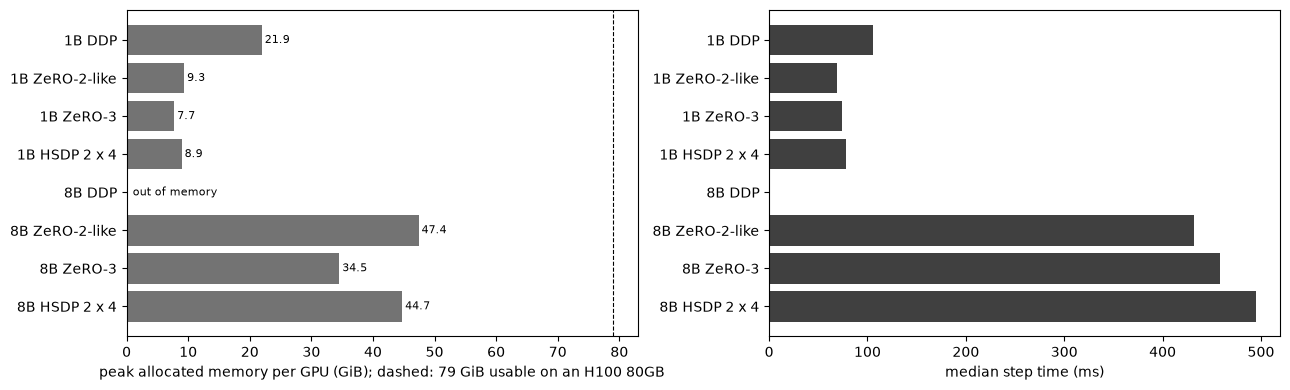

In [14]:
df = pd.DataFrame(partA)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
y = range(len(df))
ax[0].barh(list(y), df.peak_gb.where(df.status == 'ok', 0), color='0.45')
ax[0].axvline(79, color='k', ls='--', lw=0.8)
ax[0].set_xlabel('peak allocated memory per GPU (GiB); dashed: 79 GiB usable on an H100 80GB')
for i, (s, v) in enumerate(zip(df.status, df.peak_gb)):
    ax[0].text(1 if s != 'ok' else v + 0.5, i, 'out of memory' if s != 'ok' else f'{v:.1f}', va='center', fontsize=8)
ok = df[df.status == 'ok']
ax[1].barh([list(df.tag).index(t) for t in ok.tag], ok.step_ms_median, color='0.25')
ax[1].set_xlabel('median step time (ms)')
for a in ax:
    a.set_yticks(list(y)); a.set_yticklabels(df.tag); a.invert_yaxis()
plt.tight_layout(); plt.show()

**What to check**
- *Memory between steps.* The first run measured `state_gb` 12.70 GiB for 1B DDP and 1.22 GiB for 1B ZeRO-3: the prediction above (12.71 and 1.19) holds. The ratio is about 1/10, not 1/8, because DDP's buckets stay allocated.
- *8B DDP runs out of memory.* Weights, buckets and Adam alone are 16 × 7.24e9 bytes = 108 GiB per GPU. Both FSDP variants fit (first run: ZeRO-2-like 47.4 GiB peak, ZeRO-3 34.5 GiB).
- *ZeRO-3 against ZeRO-2-like.* ZeRO-3 pays one more all-gather per block and holds less at the peak: 77.9 against 71.9 ms at 1B, 462.9 against 436.8 ms at 8B. The gathers mostly overlap with compute on NVLink, so the cost is a few percent.
- *FSDP faster than DDP at 1B* (77.9 against 106.5 ms in the first run). This is specific to this setup, not a general rule. Three things favour FSDP here: the optimizer step runs on 1/8 of the parameters, FSDP's all-gathers and reduce-scatters are per block and overlap with compute, and DDP with autocast re-casts the FP32 weights to BF16 on every forward. In the profiled steps (`profiles/A`, rank 0), the optimizer range takes 23.7 ms on the GPU with DDP and 3.8 ms with ZeRO-3: DDP updates all 0.85B parameters on every GPU, FSDP updates its eighth. DDP's gradient all-reduces (17.6 ms) were all exposed: in this trace none of them overlapped with compute. ZeRO-3 had 15.4 ms of exposed NCCL time. Kernels other than matmul and attention (casts, elementwise, optimizer) took 49.9 ms with DDP and 23.4 ms with ZeRO-3. NCCL kernels per step: DDP 69 AllReduce; ZeRO-3 34 AllGather, 3 AllReduce, 17 ReduceScatter. With slow links between GPUs, or a model small enough that the per-block collectives are latency-bound, DDP can win.
- *Losses.* All four 1B runs have the same first four losses and agree to about 0.01 after 8 steps. Sharding changes where the numbers live and the order of the additions in the reductions, not the math (Part C shows what happens when training is unstable).

**Questions**
1. At 8B, how much peak memory did ZeRO-3 save per GPU against ZeRO-2-like, and what did it cost in step time? Explain both from the lecture's ZeRO stages.
2. Rerun 8B ZeRO-3 with `--global-batch 32`. Which number grows, `state_gb` or `peak_gb`, and why?

In [15]:
for r in partA:
    print(f"{r['tag']:18s}", r['losses'][:8])

1B DDP             [10.7855, 10.7879, 10.7822, 10.7885, 9.8168, 9.8654, 10.0249, 10.1167]
1B ZeRO-2-like     [10.7855, 10.7877, 10.7821, 10.7889, 9.8157, 9.867, 10.0247, 10.1243]
1B ZeRO-3          [10.7855, 10.7878, 10.7823, 10.7891, 9.8159, 9.8648, 10.0244, 10.1271]
1B HSDP 2 x 4      [10.7855, 10.7878, 10.7824, 10.7888, 9.8162, 9.8663, 10.0253, 10.1242]
8B DDP             []
8B ZeRO-2-like     [11.2011, 11.1822, 11.189, 11.1885, 4.5802, 4.1302, 4.4126, 4.4738]
8B ZeRO-3          [11.2011, 11.1818, 11.1896, 11.1891, 4.598, 4.128, 4.4204, 4.4626]
8B HSDP 2 x 4      [11.2011, 11.1815, 11.1899, 11.1894, 4.5597, 4.1315, 4.4139, 4.4589]


In [16]:
# Optional, off by default: record 2 profiled steps of each run on rank 0.
if PROFILE:
    prof_A = profile_pair('A', [('ddp_1B', '--mode ddp --model 1B'),
                       ('zero3_1B', '--mode fsdp --model 1B')], gpus=8, ranks='0')
    display(prof_A)
else:
    print('Profiling is off (PROFILE = False in the helpers cell). The figure below comes from traces recorded on 8 x H100.')

Profiling is off (PROFILE = False in the helpers cell). The figure below comes from traces recorded on 8 x H100.


**One measured step, GPU 0** (from `profiles/A`). Dark: matmul kernels; mid-gray: attention; light gray: everything else (elementwise, norms, optimizer, copies); hatched: NCCL. The top row is our `record_function` ranges. In the DDP trace, look for the all-reduces during backward and the long optimizer range at the end; in the FSDP trace, the all-gathers before each block and the reduce-scatters during backward, on their own stream, under the compute.


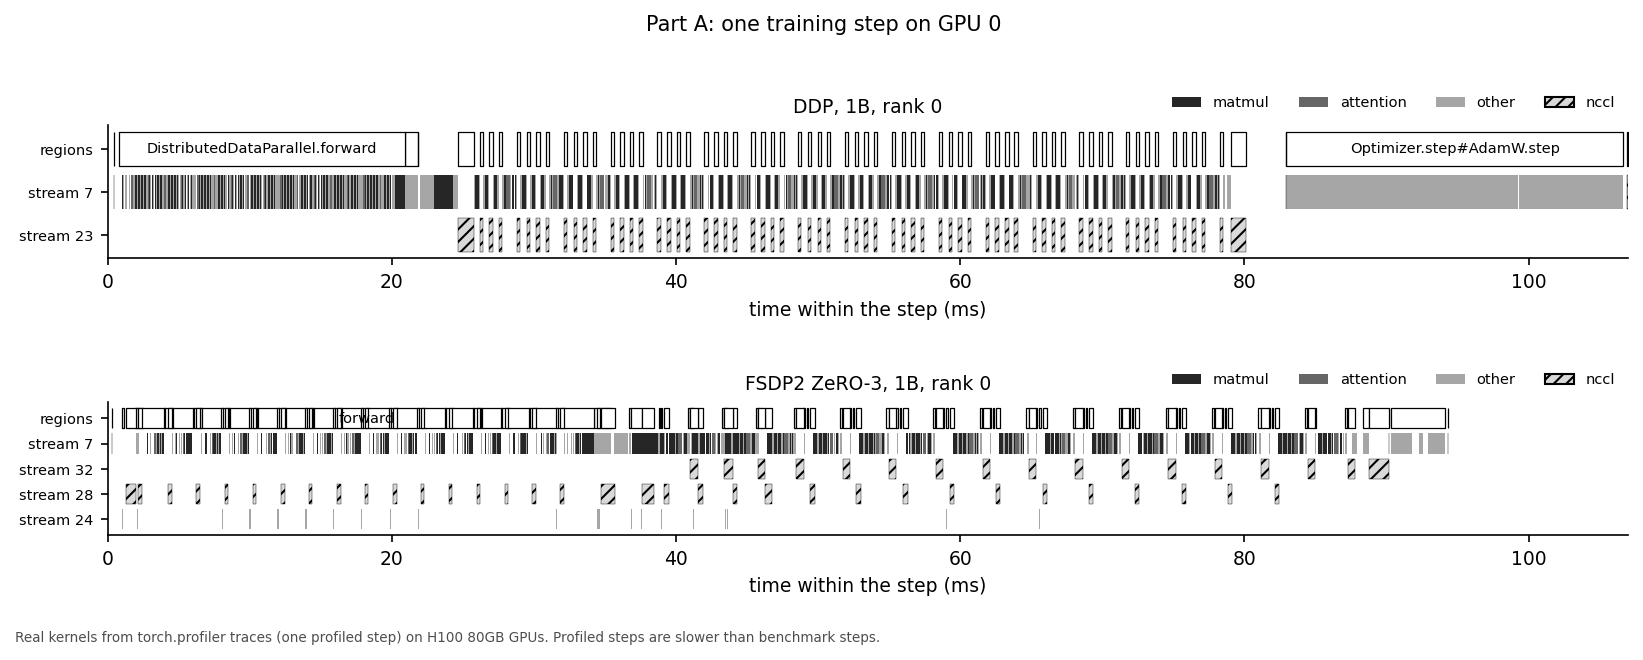

## Part B: Activation checkpointing (lecture: activation memory and checkpointing)

**What we are doing.** FSDP2 ZeRO-3 on the 3B model at sequence lengths 2K, 4K and 8K, without and with full activation checkpointing (`checkpoint_wrapper` around each block). The global batch shrinks as s grows (32, 16, 8 sequences), so every row has 64K tokens per step and 8K tokens per GPU.

**Why it matters.** Activations, not weights, usually set the memory limit for long sequences. Checkpointing keeps only each block's input during forward and reruns the block's forward during backward: memory for compute.

**What to notice.** `checkpoint_wrapper` wraps the 28 blocks only. The embedding, the final norm, the 3072 × 32000 output layer and the loss are outside the blocks and are not recomputed; neither are the optimizer step and FSDP's communication.

**What to expect.** The lecture's formula for one layer's saved activations is about 34·s·b·h + 5·a·s²·b bytes (16-bit activations, a heads). Two of its assumptions matter here:
- The s² term is the attention score matrix. `scaled_dot_product_attention` in BF16 uses a fused kernel that never stores it, so only the linear term 34·s·b·h applies.
- s·b, the tokens per GPU, is the same 8,192 in every row of this experiment. So the linear term predicts the *same* activation memory at every s.
With full checkpointing a layer keeps only its input, 2·s·b·h bytes. Recomputing the blocks' forward costs about one more forward of the blocks: a third of the blocks' compute if backward takes twice as long as forward, less of the whole step. The lecture's figure of about 33% more compute is this one third of the blocks' compute; the whole step costs less.

In [17]:
partB = []
for seq in [2048, 4096, 8192]:
    gb = 32 * 2048 // seq                    # 64K tokens per step at every length: 32, 16, 8 sequences
    for ac in ['none', 'full']:
        partB.append(run(f'--mode fsdp --model 3B --seq {seq} --global-batch {gb} --ac {ac} --steps 12 --tag "3B s={seq} ac={ac}"'))
table(partB, extra=['seq', 'ac'])

$ torchrun --standalone --nproc_per_node=8 train.py --mode fsdp --model 3B --seq 2048 --global-batch 32 --ac none --steps 12 --tag "3B s=2048 ac=none"


   model 3B: 3.02B parameters, 28 layers, h = 3072, seq 2048, 8 GPUs
   -> ok: 360.9 ms/step (median 359.4, p10-p90 353.8-369.1), 181,590 tokens/s, MFU 45.0%, peak 32.25 GB, state 4.216 GB
$ torchrun --standalone --nproc_per_node=8 train.py --mode fsdp --model 3B --seq 2048 --global-batch 32 --ac full --steps 12 --tag "3B s=2048 ac=full"


   model 3B: 3.02B parameters, 28 layers, h = 3072, seq 2048, 8 GPUs
   -> ok: 443.2 ms/step (median 442.0, p10-p90 436.0-451.2), 147,870 tokens/s, MFU 36.7%, peak 9.048 GB, state 4.224 GB
$ torchrun --standalone --nproc_per_node=8 train.py --mode fsdp --model 3B --seq 4096 --global-batch 16 --ac none --steps 12 --tag "3B s=4096 ac=none"


   model 3B: 3.02B parameters, 28 layers, h = 3072, seq 4096, 8 GPUs
   -> ok: 379.9 ms/step (median 379.4, p10-p90 373.9-385.6), 172,509 tokens/s, MFU 47.4%, peak 32.251 GB, state 4.217 GB
$ torchrun --standalone --nproc_per_node=8 train.py --mode fsdp --model 3B --seq 4096 --global-batch 16 --ac full --steps 12 --tag "3B s=4096 ac=full"


   model 3B: 3.02B parameters, 28 layers, h = 3072, seq 4096, 8 GPUs
   -> ok: 465.2 ms/step (median 465.5, p10-p90 458.0-471.2), 140,877 tokens/s, MFU 38.7%, peak 9.048 GB, state 4.224 GB
$ torchrun --standalone --nproc_per_node=8 train.py --mode fsdp --model 3B --seq 8192 --global-batch 8 --ac none --steps 12 --tag "3B s=8192 ac=none"


   model 3B: 3.02B parameters, 28 layers, h = 3072, seq 8192, 8 GPUs
   -> ok: 415.1 ms/step (median 415.1, p10-p90 410.6-419.8), 157,880 tokens/s, MFU 51.8%, peak 32.253 GB, state 4.219 GB
$ torchrun --standalone --nproc_per_node=8 train.py --mode fsdp --model 3B --seq 8192 --global-batch 8 --ac full --steps 12 --tag "3B s=8192 ac=full"


   model 3B: 3.02B parameters, 28 layers, h = 3072, seq 8192, 8 GPUs
   -> ok: 508.2 ms/step (median 506.6, p10-p90 504.5-512.4), 128,957 tokens/s, MFU 42.3%, peak 9.051 GB, state 4.227 GB


,tag,seq,ac,status,seqs_per_gpu,step_ms,step_ms_median,tokens_per_s,mfu,peak_gb,state_gb
0,3B s=2048 ac=none,2048,none,ok,4,360.900000,359.400000,"181,590",45.0%,32.250000,4.216000
1,3B s=2048 ac=full,2048,full,ok,4,443.200000,442.000000,"147,870",36.7%,9.048000,4.224000
2,3B s=4096 ac=none,4096,none,ok,2,379.900000,379.400000,"172,509",47.4%,32.251000,4.217000
3,3B s=4096 ac=full,4096,full,ok,2,465.200000,465.500000,"140,877",38.7%,9.048000,4.224000
4,3B s=8192 ac=none,8192,none,ok,1,415.100000,415.100000,"157,880",51.8%,32.253000,4.219000
5,3B s=8192 ac=full,8192,full,ok,1,508.200000,506.600000,"128,957",42.3%,9.051000,4.227000


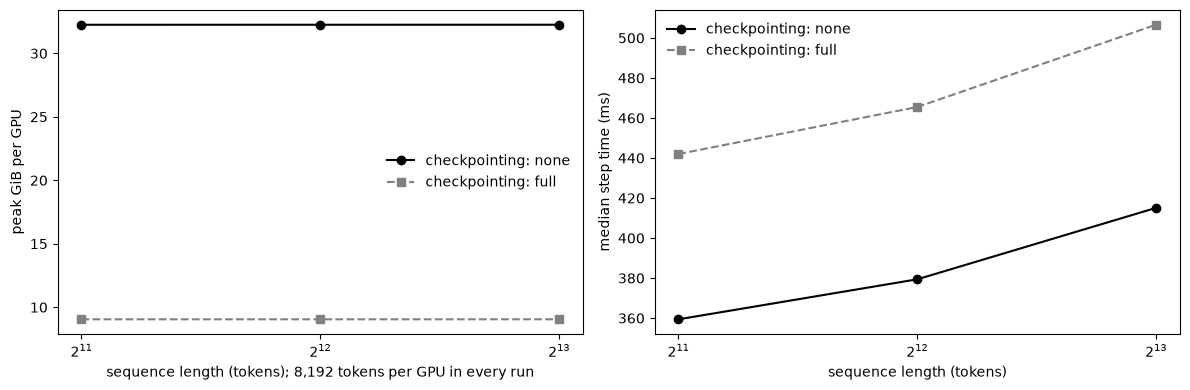

s=2048: checkpointing saves 23.2 GiB and costs +23% time
s=4096: checkpointing saves 23.2 GiB and costs +22% time
s=8192: checkpointing saves 23.2 GiB and costs +22% time


In [18]:
df = pd.DataFrame(partB)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for ac, st in [('none', dict(color='0.0', marker='o', ls='-')), ('full', dict(color='0.5', marker='s', ls='--'))]:
    d = df[(df.ac == ac) & (df.status == 'ok')]
    ax[0].plot(d.seq, d.peak_gb, label=f'checkpointing: {ac}', **st)
    ax[1].plot(d.seq, d.step_ms_median, label=f'checkpointing: {ac}', **st)
ax[0].set(xlabel='sequence length (tokens); 8,192 tokens per GPU in every run', ylabel='peak GiB per GPU')
ax[1].set(xlabel='sequence length (tokens)', ylabel='median step time (ms)')
for x in ax: x.set_xscale('log', base=2); x.legend(frameon=False)
plt.tight_layout(); plt.show()
for s in [2048, 4096, 8192]:
    a, b = df[(df.seq == s) & (df.ac == 'none')].iloc[0], df[(df.seq == s) & (df.ac == 'full')].iloc[0]
    if a.status == b.status == 'ok':
        print(f's={s}: checkpointing saves {a.peak_gb - b.peak_gb:.1f} GiB and costs {b.step_ms / a.step_ms - 1:+.0%} time')

**What to check**
- *Memory.* First run: s = 2048: 23.2 GiB saved, +23% time | s = 4096: 23.2 GiB saved, +22% time | s = 8192: 23.2 GiB saved, +22% time. The saving is the same at every s, as the linear term predicts for a fixed number of tokens per GPU. The formula's estimate, (34 − 2)·s·b·h·L = 32 × 8192 × 3072 × 28 bytes = 21.0 GiB, is within about 10% of the measured saving: the formula assumes a 4h MLP and dropout masks, this model has a SwiGLU MLP and no dropout.
- *Time.* The cost is about 22%, not a third. The recomputed forward covers the blocks only, and the step also contains work that is not recomputed: the output layer and loss, the FSDP all-gathers and reduce-scatters, and the optimizer. In the profiled 3B step at s = 4096 (rank 0, `profiles/B`), checkpointing raised the GPU's compute time from 366.7 to 446.8 ms per step: matmul kernels 218.4 to 261.1 ms, attention 46.3 to 58.8 ms, other kernels 105.3 to 127.5 ms. The `forward` range itself takes 115.8 ms of a 382.8 ms step, about 30%, so recomputing it cannot cost a third of the step.
- If you hold the global batch fixed instead (so tokens per GPU grow with s), activation memory grows linearly with s, still with no s² term.

**Questions**
1. What part of the step is not recomputed, and roughly what fraction of the step is it here?
2. At which sequence length does the run without checkpointing stop fitting? Add `--seq 16384 --global-batch 4` (still 64K tokens per step) and then `--seq 16384 --global-batch 8`, and explain the difference.

In [19]:
# Optional, off by default: record 2 profiled steps of each run on rank 0.
if PROFILE:
    prof_B = profile_pair('B', [('ac_none', '--mode fsdp --model 3B --seq 4096 --global-batch 16 --ac none'),
                       ('ac_full', '--mode fsdp --model 3B --seq 4096 --global-batch 16 --ac full')], gpus=8, ranks='0')
    display(prof_B)
else:
    print('Profiling is off (PROFILE = False in the helpers cell). The figure below comes from traces recorded on 8 x H100.')

Profiling is off (PROFILE = False in the helpers cell). The figure below comes from traces recorded on 8 x H100.


**One measured step, GPU 0** (from `profiles/B`). With full checkpointing, the backward pass contains a second copy of each block's forward kernels (the recomputation) just before that block's backward kernels.


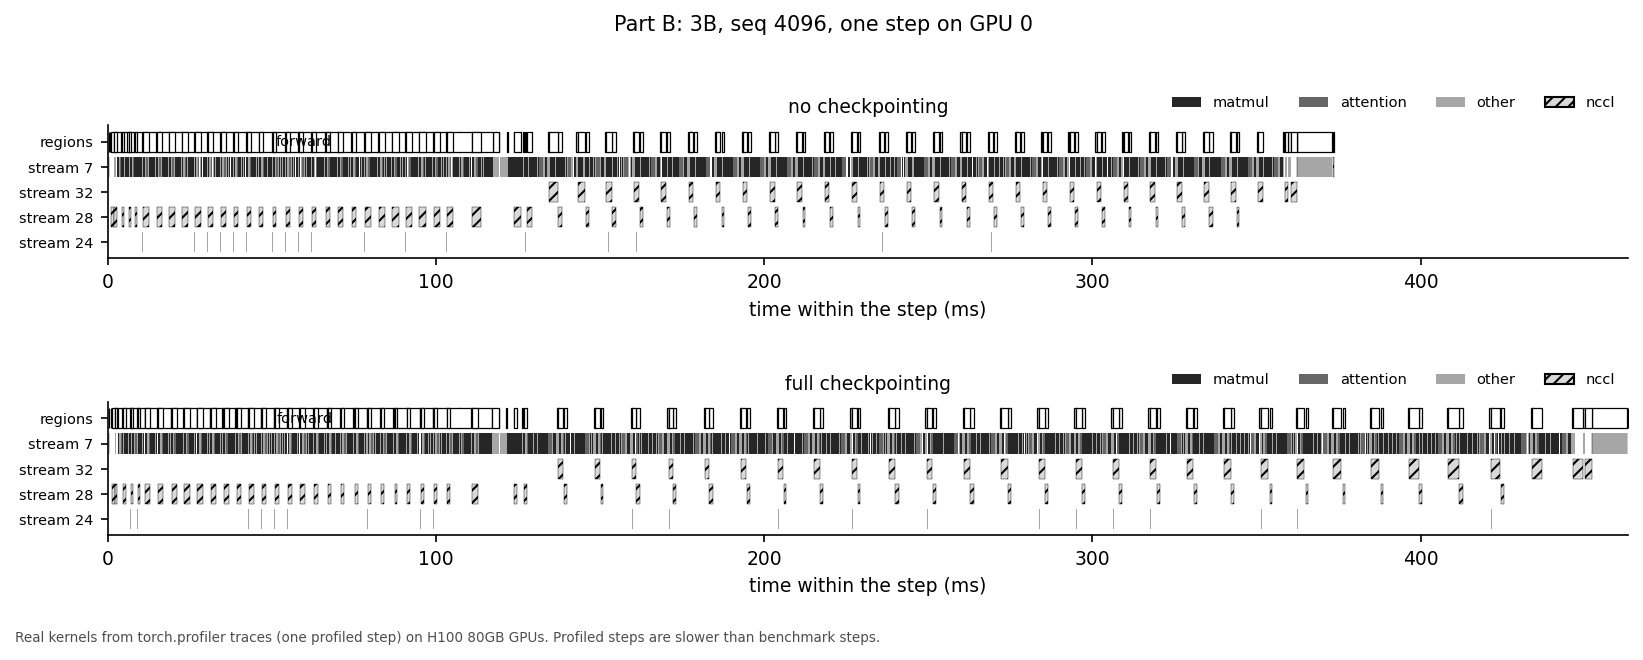

## Part C: Tensor and sequence parallelism (lecture: Megatron tensor parallelism, TP cost, sequence parallelism)

**What we are doing.** The 8B model on 8 GPUs, split by tensor parallelism over t GPUs and FSDP2 over the remaining 8/t, with global batch 16 and sequence 2048 in every row.

| t | dp | sequences per GPU | tokens per GPU per step |
|---|---|---|---|
| 1 | 8 | 2 | 4,096 |
| 2 | 4 | 4 | 8,192 |
| 4 | 2 | 8 | 16,384 |
| 8 | 1 | 16 | 32,768 |

The t GPUs of a TP group compute on the same sequences, so with a fixed global batch each GPU processes 2t sequences. The rows hold the total work fixed, not the work per GPU.

**What to notice in the plan** (`apply_tp`). For one block on t = 4, with b = 8 sequences of s = 2048 tokens and h = 4096:
- With SP, the residual stream between blocks is `Shard(1)`: each GPU holds (8, 512, 4096), a quarter of the tokens.
- `PrepareModuleInput` all-gathers it to `Replicate()`: (8, 2048, 4096) on every GPU, because `wq`, `wk`, `wv` (and `w1`, `w3`) are column-parallel and need every token.
- Each column-parallel matmul produces its own quarter of the features: q is (8, 2048, 1024) per GPU, 8 of the 32 query heads; k and v are 2 of the 8 KV heads.
- `wo` and `w2` are row-parallel. Each GPU's output is a partial sum of the full (8, 2048, 4096); with SP it is reduce-scattered back to (8, 512, 4096). Two all-gathers and two reduce-scatters per block in forward, the same again in backward.
- The output layer all-gathers the logits: every GPU of the group holds the full (b, s, 32000) logits, and the loss makes an FP32 copy.

**What to expect.** The weights and optimizer state per GPU are the same in every row (FSDP or TP divide them by 8). The textbook activation estimate with SP divides the per-layer activations by t; with 2t sequences per GPU that gives the same activation memory in every row. Two things in this implementation are not divided by t: the gathered block inputs (`PrepareModuleInput` keeps the full (b, s, h) BF16 tensor for the backward of the column-parallel matmuls; Megatron-LM avoids this by saving the sharded input and gathering again in backward) and the replicated logits. Both grow with the sequences per GPU, so peak memory grows with t here. The lecture says that sequence parallelism divides activation memory per GPU by t; that holds for the Megatron design per unit of work, and the table below shows where this implementation differs.

**A fix made after the first run.** In the first run, t = 8 (dp = 1) skipped FSDP and fell back to autocast with FP32 weights, while t = 2 and 4 used FSDP's BF16 mixed-precision policy. Under autocast the residual stream stays FP32 and the gathered input is cast to BF16 separately for `wq`, `wk`, `wv`, `w1` and `w3`, each copy saved for backward. `train.py` now applies FSDP2 over the one-GPU dp mesh as well, so every row uses the same precision recipe. `--tp-dp1-autocast 1` reproduces the first-run path.

In [20]:
partC = []
for t in [1, 2, 4, 8]:
    mode = '--mode fsdp' if t == 1 else f'--mode tp --tp {t}'
    partC.append(run(f'{mode} --model 8B --seq 2048 --global-batch 16 --steps 12 --tag "TP {t} x FSDP {8 // t}"'))
partC.append(run('--mode tp --tp 8 --sp 0 --model 8B --seq 2048 --global-batch 16 --steps 12 --tag "TP 8, no SP"'))
# With the logits sharded, TP8 fits with and without SP, so the two can be compared.
for sp in (1, 0):
    partC.append(run(f'--mode tp --tp 8 --sp {sp} --vocab-parallel-loss 1 --model 8B --seq 2048 --global-batch 16 --steps 12 '
                     f'--tag "TP 8, SP={sp}, vocab-parallel loss"'))
# The first run's TP8 path (no FSDP, autocast with FP32 weights): expected to run out of memory.
partC.append(run('--mode tp --tp 8 --tp-dp1-autocast 1 --model 8B --seq 2048 --global-batch 16 --steps 12 --tag "TP 8, original autocast path"'))
# Logits sharded over the vocabulary: cross-entropy with loss_parallel(), no gathered (b, s, V) tensor.
partC.append(run('--mode tp --tp 4 --vocab-parallel-loss 1 --model 8B --seq 2048 --global-batch 16 --steps 12 --tag "TP 4, vocab-parallel loss"'))
# A different workload, labeled as such: 2 sequences per GPU in every row (fewer tokens per step for t > 1).
partC.append(run('--mode tp --tp 4 --model 8B --seq 2048 --global-batch 4 --steps 12 --tag "TP 4, 2 seq per GPU (global batch 4)"'))
partC.append(run('--mode tp --tp 8 --model 8B --seq 2048 --global-batch 2 --steps 12 --tag "TP 8, 2 seq per GPU (global batch 2)"'))
table(partC, extra=['tp', 'sp', 'global_batch'])

$ torchrun --standalone --nproc_per_node=8 train.py --mode fsdp --model 8B --seq 2048 --global-batch 16 --steps 12 --tag "TP 1 x FSDP 8"


   model 8B: 7.24B parameters, 32 layers, h = 4096, seq 2048, 8 GPUs
   -> ok: 458.9 ms/step (median 457.3, p10-p90 453.1-465.9), 71,406 tokens/s, MFU 41.4%, peak 34.509 GB, state 10.118 GB
$ torchrun --standalone --nproc_per_node=8 train.py --mode tp --tp 2 --model 8B --seq 2048 --global-batch 16 --steps 12 --tag "TP 2 x FSDP 4"


   model 8B: 7.24B parameters, 32 layers, h = 4096, seq 2048, 8 GPUs
   -> ok: 479.9 ms/step (median 479.7, p10-p90 478.2-481.8), 68,281 tokens/s, MFU 39.6%, peak 37.646 GB, state 10.118 GB
$ torchrun --standalone --nproc_per_node=8 train.py --mode tp --tp 4 --model 8B --seq 2048 --global-batch 16 --steps 12 --tag "TP 4 x FSDP 2"


   model 8B: 7.24B parameters, 32 layers, h = 4096, seq 2048, 8 GPUs
   -> ok: 541.6 ms/step (median 541.2, p10-p90 540.8-542.9), 60,502 tokens/s, MFU 35.1%, peak 45.128 GB, state 10.119 GB
$ torchrun --standalone --nproc_per_node=8 train.py --mode tp --tp 8 --model 8B --seq 2048 --global-batch 16 --steps 12 --tag "TP 8 x FSDP 1"


   model 8B: 7.24B parameters, 32 layers, h = 4096, seq 2048, 8 GPUs
   -> ok: 673.0 ms/step (median 672.8, p10-p90 672.6-673.4), 48,689 tokens/s, MFU 28.2%, peak 60.09 GB, state 10.121 GB
$ torchrun --standalone --nproc_per_node=8 train.py --mode tp --tp 8 --sp 0 --model 8B --seq 2048 --global-batch 16 --steps 12 --tag "TP 8, no SP"


   model 8B: 7.24B parameters, 32 layers, h = 4096, seq 2048, 8 GPUs
   OUT OF MEMORY: CUDA out of memory. Tried to allocate 3.91 GiB. GPU 0 has a total capacity of 79.18 GiB of which 2.49 GiB is free. Including non-PyTorch memory, this process has 76.68 GiB memory in use. Of the allocated memory 70.41 GiB is allocated by PyTorch, and 3.54 GiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)
   -> OOM: peak 70.41 GB when it failed
$ torchrun --standalone --nproc_per_node=8 train.py --mode tp --tp 8 --sp 1 --vocab-parallel-loss 1 --model 8B --seq 2048 --global-batch 16 --steps 12 --tag "TP 8, SP=1, vocab-parallel loss"


... (3 outputs left out)

   model 8B: 7.24B parameters, 32 layers, h = 4096, seq 2048, 8 GPUs
   -> ok: 534.4 ms/step (median 533.5, p10-p90 532.6-536.6), 61,317 tokens/s, MFU 35.6%, peak 40.49 GB, state 10.119 GB
$ torchrun --standalone --nproc_per_node=8 train.py --mode tp --tp 4 --model 8B --seq 2048 --global-batch 4 --steps 12 --tag "TP 4, 2 seq per GPU (global batch 4)"


   model 8B: 7.24B parameters, 32 layers, h = 4096, seq 2048, 8 GPUs
   -> ok: 401.5 ms/step (median 401.4, p10-p90 401.0-402.1), 20,403 tokens/s, MFU 11.8%, peak 18.871 GB, state 10.119 GB
$ torchrun --standalone --nproc_per_node=8 train.py --mode tp --tp 8 --model 8B --seq 2048 --global-batch 2 --steps 12 --tag "TP 8, 2 seq per GPU (global batch 2)"


   model 8B: 7.24B parameters, 32 layers, h = 4096, seq 2048, 8 GPUs
   -> ok: 380.7 ms/step (median 380.1, p10-p90 379.9-381.9), 10,759 tokens/s, MFU 6.2%, peak 16.868 GB, state 10.121 GB


,tag,tp,sp,global_batch,status,seqs_per_gpu,step_ms,step_ms_median,tokens_per_s,mfu,peak_gb,state_gb
0,TP 1 x FSDP 8,1,OOM,16,ok,2,458.900000,457.300000,"71,406",41.4%,34.509000,10.118000
1,TP 2 x FSDP 4,2,1.000000,16,ok,4,479.900000,479.700000,"68,281",39.6%,37.646000,10.118000
2,TP 4 x FSDP 2,4,1.000000,16,ok,8,541.600000,541.200000,"60,502",35.1%,45.128000,10.119000
3,TP 8 x FSDP 1,8,1.000000,16,ok,16,673.000000,672.800000,"48,689",28.2%,60.090000,10.121000
4,"TP 8, no SP",8,0.000000,16,OOM,16,OOM,OOM,OOM,OOM,70.410000,10.121000
5,"TP 8, SP=1, vocab-parallel loss",8,1.000000,16,ok,16,653.500000,653.400000,"50,142",29.1%,48.617000,10.121000
6,"TP 8, SP=0, vocab-parallel loss",8,0.000000,16,ok,16,752.000000,752.200000,"43,574",25.3%,62.843000,10.121000
7,"TP 8, original autocast path",8,1.000000,16,OOM,16,OOM,OOM,OOM,OOM,73.219000,3.375000
8,"TP 4, vocab-parallel loss",4,1.000000,16,ok,8,534.400000,533.500000,"61,317",35.6%,40.490000,10.119000
9,"TP 4, 2 seq per GPU (global batch 4)",4,1.000000,4,ok,2,401.500000,401.400000,"20,403",11.8%,18.871000,10.119000


**What to check**
- *Peak memory grows with t at a fixed global batch.* Measured (follow-up runs): TP1 34.5, TP2 37.6, TP4 45.1 GiB, and the first-run TP8 path ran out of memory with and without SP. `state_gb` is about 10.1 GiB in every row that fits: weights and optimizer state are not the cause.
- *Per-GPU work is the cause.* With 2 sequences per GPU in every row, TP4 peaks at 18.9 GiB and TP8 at 21.3 GiB, against 34.5 GiB for FSDP8: at equal work per GPU, TP holds less, because the matmul activations are divided by t. These runs do 4 and 8 times fewer tokens per step, so they are a different experiment, not a fix.
- *The logits are part of it.* Sharding them (`--vocab-parallel-loss 1`) lowers TP4's peak from 45.1 to 40.5 GiB. In the first run of TP8, the allocation that failed was 3.91 GiB, exactly the FP32 logits 16 × 2048 × 32000 × 4 bytes, but 73.2 GiB were already in use: the logits tipped it over, they were not the bulk.
- *The first-run TP8 path had a second problem*, the FP32 autocast path described above (table below). With the fix, TP8 at the same workload fits: peak 60.1 GiB with SP; without SP it still runs out of memory (at 70.4 GiB) unless the logits are sharded too. Benchmarks of the fixed TP8 (15 steps, 10 timed, median): TP8: 672.0 ms, peak 60.1 GiB; TP8 no SP: OOM; TP8, vocab-parallel loss: 652.5 ms, peak 48.6 GiB; TP8 no SP, vocab-parallel loss: 752.8 ms, peak 62.8 GiB.
- *Sequence parallelism.* With the vocabulary-parallel loss, TP8 fits with and without SP: peak 48.6 GiB and median 652.5 ms with SP, 62.8 GiB and 752.8 ms without. SP shards the residual stream and the norms over the 8 GPUs; without it every GPU holds them for all 16 sequences, and the all-reduces after `wo` and `w2` replace the reduce-scatters.
- *Step time grows with t* even inside one node: TP adds two all-gathers and two reduce-scatters per block in forward and again in backward, each of them blocking the next matmul, and each GPU runs more, smaller matmuls. Across two nodes those collectives would run at a tenth of the bandwidth (the lecture's tensor-parallelism cost example).

**Where the memory is** (allocator snapshot on rank 0, grouped by the line of code that allocated each live tensor; measured with `--mem-regions ... --mem-snapshot 1`; "before backward" is the peak of saved activations, "at the OOM" is the moment the failed allocation was requested):

| GiB on rank 0 | TP1 x FSDP8 | TP2 x FSDP4 | TP4 x FSDP2 | TP8, original autocast path | TP8, FSDP policy (fixed) |
|---|---:|---:|---:|---:|---:|
| sequences per GPU | 2 | 4 | 8 | 16 | 16 |
| snapshot taken | before backward | before backward | before backward | at the OOM | before backward |
| MLP: w1, w3 outputs and SwiGLU product (`hpml_llm.py:97`) | 14.0 | 14.0 | 14.0 | 31.3 | 14.0 |
| wq input copy and output (`hpml_llm.py:75`) |  |  |  | 8.1 |  |
| wk input copy and output (`hpml_llm.py:76`) |  |  |  | 8.0 |  |
| wv input copy and output (`hpml_llm.py:77`) |  |  |  | 8.0 |  |
| attention-norm output, gathered over the TP group (`hpml_llm.py:109`) | 2.0 | 3.0 | 5.0 | 2.0 | 9.0 |
| MLP-norm output, gathered over the TP group (`hpml_llm.py:110`) | 2.0 | 3.0 | 5.0 | 2.0 | 9.0 |
| K, V repeated to 32 heads (`hpml_llm.py:82`) | 2.0 | 2.0 | 2.0 | 2.0 | 2.0 |
| attention output and statistics (`hpml_llm.py:85`) | 1.0 | 1.0 | 1.0 | 1.0 | 1.0 |
| rotary embedding of q, k (`hpml_llm.py:59`) | 1.0 | 1.0 | 1.0 | 1.0 | 1.0 |
| BF16 logits (`hpml_llm.py:129`) | 0.2 | 0.6 | 1.1 | 2.2 | 2.2 |
| FP32 logits and log-softmax for the loss (`train.py, forward_backward`) | 0.5 | 1.0 | 1.9 | 3.9 | 3.9 |
| Adam moments (optimizer state) (`train.py, optimizer_step`) | 6.7 | 6.8 | 6.8 |  | 6.8 |
| **all live allocations** | **32.9** | **35.7** | **41.2** | **73.2** | **52.3** |


Read the first three columns: the MLP and attention activations (lines 97, 82, 85) stay the same as t grows, as the textbook estimate says; the gathered norm outputs (lines 109 and 110) and the logits (line 129 and the loss) grow with t. In the "TP8, original autocast path" column (the first-run setup), the `wq`, `wk`, `wv` rows and the larger MLP row are the separate BF16 copies made by autocast.

**Measured peak memory per layout** (follow-up runs, 2 steps each; OOM shown as a label).

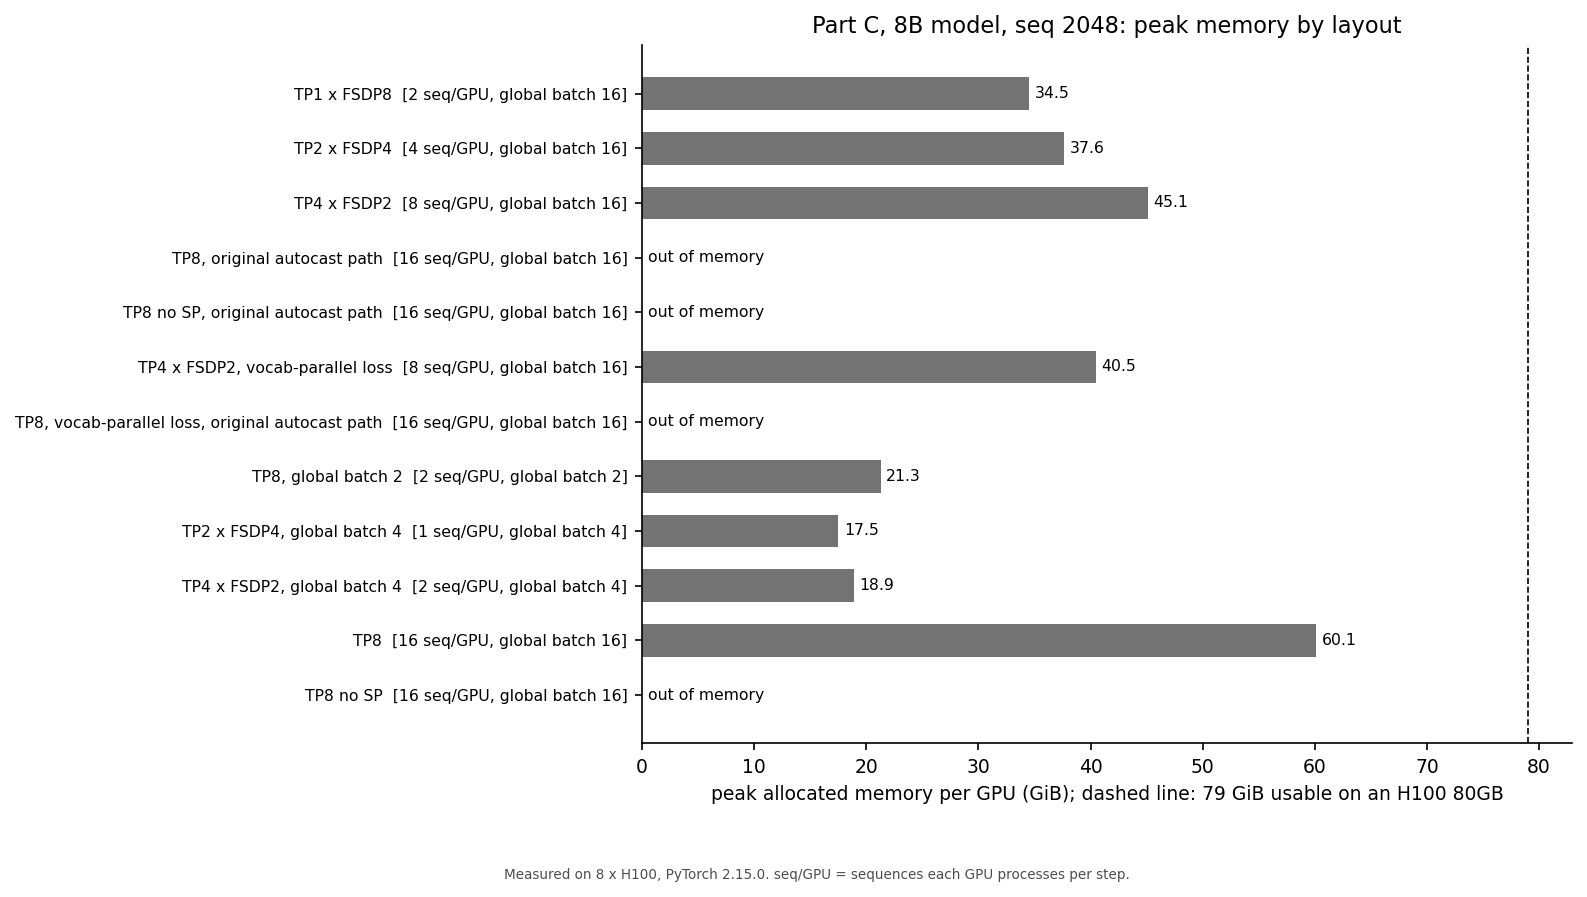

**Memory held as the forward pass runs**, rank 0: each point is after one module. The slope through the 32 blocks is the activation memory one block keeps for backward; the jump at the end is the output layer and the loss.

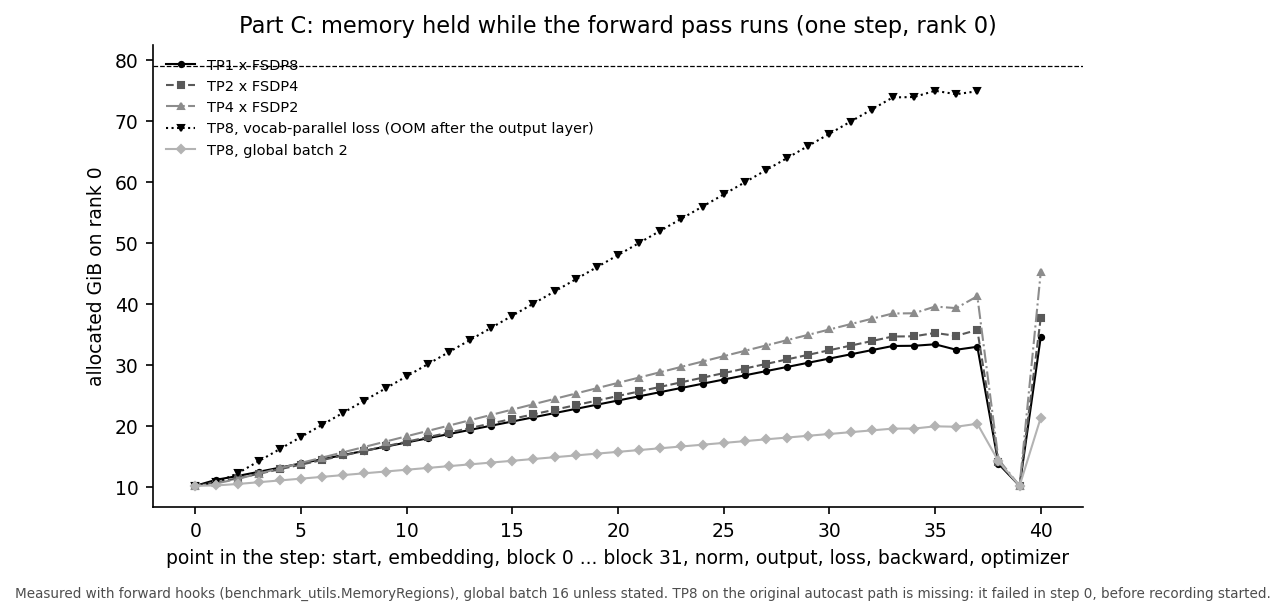

### Do the layouts compute the same training run?

**What we are doing.** Printing every Part C row's loss at the same step (Part A's 8B rows ran 15 steps, Part C 12).

**What to expect, and what was measured.**
- *Step 0 agrees.* Loss 11.20108 (TP1 × FSDP8) and 11.20115 (TP2 × FSDP4); global gradient norm 24.2997 and 24.2994. In FP32, a one-step comparison of every layout with a one-GPU reference (350M model, `numerical_validation.py`) matches every gradient to about 5e-6 relative. There is no layout bug.
- *The same run does not repeat itself in BF16.* Two runs of the identical FSDP8 configuration differ by up to 0.47 in loss within 12 steps; FSDP8 against TP2 × FSDP4 differ by up to 0.57. BF16 reductions on GPUs are not bit-reproducible from run to run, so the layout comparison is no worse than a repeat.
- *In FP32 the two layouts agree* to 0.00 over all 12 steps, and the loss still climbs from 3.14 to 7.67. The rise is the optimization, not rounding: the learning rate (3e-4 after 5 warm-up steps, no clipping) is too high for an 8B model memorizing 64 random sequences. With lr 1e-4 the loss falls to 0.05 and stays there. Rounding only decides which way each unstable run goes.

So "the losses should agree" holds for the first steps and in FP32. After an unstable stretch, two BF16 runs of the same configuration disagree as much as two layouts do.

In [21]:
print('loss at step 11 (12th step)')
for r in [x for x in partA if x['tag'].startswith('8B')] + partC:
    print(f"{r['tag']:42s}", r['losses'][11] if r['status'] == 'ok' and len(r['losses']) > 11 else r['status'])

loss at step 11 (12th step)
8B DDP                                     OOM
8B ZeRO-2-like                             7.5591
8B ZeRO-3                                  7.8812
8B HSDP 2 x 4                              8.0811
TP 1 x FSDP 8                              8.1451
TP 2 x FSDP 4                              7.4972
TP 4 x FSDP 2                              8.0635
TP 8 x FSDP 1                              8.5325
TP 8, no SP                                OOM
TP 8, SP=1, vocab-parallel loss            8.0568
TP 8, SP=0, vocab-parallel loss            7.3753
TP 8, original autocast path               OOM
TP 4, vocab-parallel loss                  7.9249
TP 4, 2 seq per GPU (global batch 4)       10.8676
TP 8, 2 seq per GPU (global batch 2)       10.848


**Loss curves, 8B model, same weights and data in every run** (follow-up runs). Left: the default settings, including a repeat of the same FSDP8 run and both layouts in FP32. Right: gradient clipping at 1.0 and a lower learning rate.

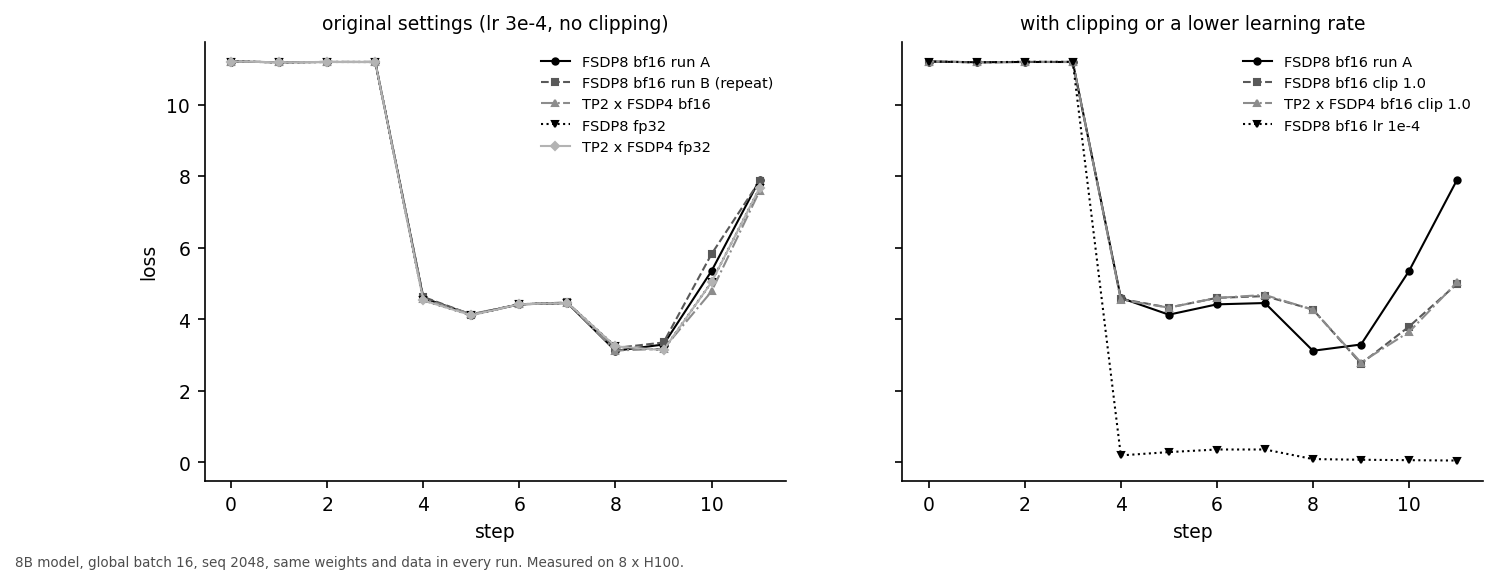

**Questions**
1. Using the table above, explain why TP2 × FSDP4 needs more memory than FSDP8 although each GPU stores the same weights. Which two tensors would you change first, and how?
2. The repeat of the same FSDP8 run differs from the first by about as much as TP2 does. What does that tell you about comparing two parallel layouts by their loss curves?
3. In the TP2 trace, count the all-gather and reduce-scatter kernels for one block in forward and in backward. Does it match two of each per block per pass, plus FSDP's own gathers and reduce-scatters?

In [22]:
# Optional, off by default: record 2 profiled steps of each run on rank 0.
if PROFILE:
    prof_C = profile_pair('C', [('tp1', '--mode fsdp --model 8B'),
                       ('tp2', '--mode tp --tp 2 --model 8B')], gpus=8, ranks='0')
    display(prof_C)
else:
    print('Profiling is off (PROFILE = False in the helpers cell). The figure below comes from traces recorded on 8 x H100.')

Profiling is off (PROFILE = False in the helpers cell). The figure below comes from traces recorded on 8 x H100.


**One measured step on GPU 0** (from `profiles/C`). TP2 adds the TP collectives inside each block, between the matmuls, where nothing else can run.

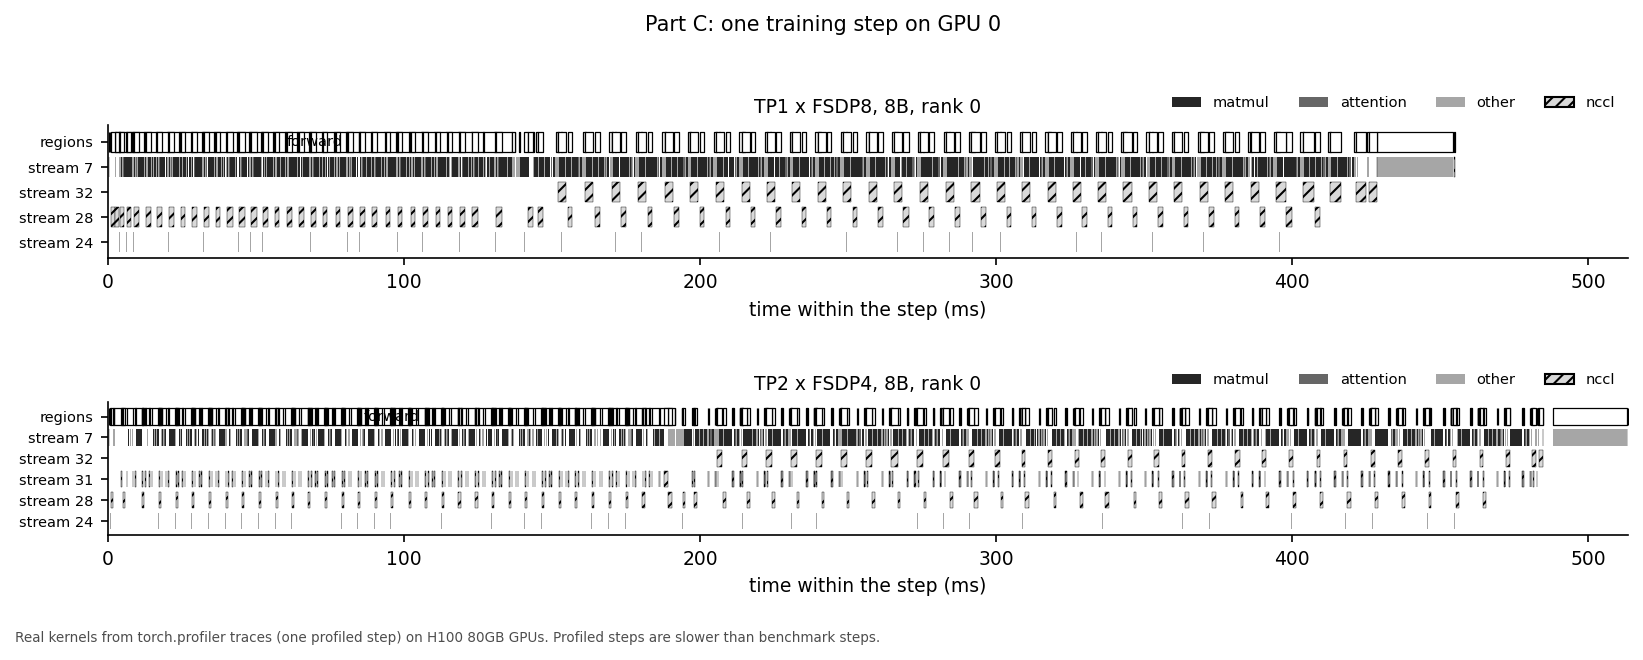

## Part D: Pipeline schedules (lecture: pipeline bubble, micro-batches, schedules)

**What we are doing.** The 1B model (16 layers) on 4 GPUs as a 4-stage pipeline, global batch 32 sequences cut into m micro-batches. GPipe and 1F1B use one stage of 4 layers per GPU. Interleaved 1F1B uses v = 2 stages of 2 layers per GPU: GPU 0 holds layers 0 to 1 and 8 to 9, GPU 3 holds layers 6 to 7 and 14 to 15.

**What to notice.** `torch.distributed.pipelining` passes activations forward and gradients backward between stages with point-to-point `send`/`recv` (NCCL SendRecv kernels in a trace). Only the first stage gets token ids and only the last stage gets targets and computes the loss. The stages have equal numbers of layers but not equal work: the last stage also runs the final norm, the 2048 × 32000 output layer (65M weights, about 1.5 blocks' worth) and the loss. With interleaving, the last *virtual* stage is 2 layers plus that output layer, so the imbalance is larger relative to one stage.

**What to expect from the model.** For p_pp stages of equal duration and m micro-batches, the idle fraction ("bubble") of GPipe and 1F1B is (p_pp − 1)/(m + p_pp − 1): 43% at m = 4, 27% at m = 8, 16% at m = 16 for p_pp = 4. Interleaving with v stages per GPU divides it by about v. 1F1B has the same bubble as GPipe but keeps at most p_pp micro-batches of activations alive instead of m. That model assumes equal stages, a micro-batch time proportional to its size, and free communication. None of the three holds exactly here, so a smaller modelled bubble does not have to give a shorter step. The lecture's schedules table gives interleaved 1F1B a smaller bubble under the same assumptions.

In [23]:
partD = []
for sched in ['gpipe', '1f1b', 'interleaved']:
    for m in [4, 8, 16, 32]:
        partD.append(run(f'--mode pp --schedule {sched} --microbatches {m} --model 1B --seq 2048 --global-batch 32 --steps 12 '
                         f'--tag "{sched} m={m}"', gpus=4))
table(partD, extra=['schedule', 'microbatches'])

$ torchrun --standalone --nproc_per_node=4 train.py --mode pp --schedule gpipe --microbatches 4 --model 1B --seq 2048 --global-batch 32 --steps 12 --tag "gpipe m=4"


   model 1B: 0.85B parameters, 16 layers, h = 2048, seq 2048, 4 GPUs
   -> ok: 425.6 ms/step (median 425.7, p10-p90 425.1-426.0), 153,985 tokens/s, MFU 21.5%, peak 43.617 GB, state 6.656 GB
$ torchrun --standalone --nproc_per_node=4 train.py --mode pp --schedule gpipe --microbatches 8 --model 1B --seq 2048 --global-batch 32 --steps 12 --tag "gpipe m=8"


   model 1B: 0.85B parameters, 16 layers, h = 2048, seq 2048, 4 GPUs
   -> ok: 362.6 ms/step (median 362.3, p10-p90 362.1-363.3), 180,739 tokens/s, MFU 25.2%, peak 41.664 GB, state 6.656 GB
$ torchrun --standalone --nproc_per_node=4 train.py --mode pp --schedule gpipe --microbatches 16 --model 1B --seq 2048 --global-batch 32 --steps 12 --tag "gpipe m=16"


   model 1B: 0.85B parameters, 16 layers, h = 2048, seq 2048, 4 GPUs
   -> ok: 348.5 ms/step (median 348.4, p10-p90 348.1-348.8), 188,052 tokens/s, MFU 26.3%, peak 40.688 GB, state 6.656 GB
$ torchrun --standalone --nproc_per_node=4 train.py --mode pp --schedule gpipe --microbatches 32 --model 1B --seq 2048 --global-batch 32 --steps 12 --tag "gpipe m=32"


   model 1B: 0.85B parameters, 16 layers, h = 2048, seq 2048, 4 GPUs
   -> ok: 366.4 ms/step (median 366.4, p10-p90 366.2-366.7), 178,865 tokens/s, MFU 25.0%, peak 40.224 GB, state 6.677 GB
$ torchrun --standalone --nproc_per_node=4 train.py --mode pp --schedule 1f1b --microbatches 4 --model 1B --seq 2048 --global-batch 32 --steps 12 --tag "1f1b m=4"


   model 1B: 0.85B parameters, 16 layers, h = 2048, seq 2048, 4 GPUs
   -> ok: 425.1 ms/step (median 425.3, p10-p90 424.7-425.4), 154,166 tokens/s, MFU 21.5%, peak 27.631 GB, state 6.656 GB
$ torchrun --standalone --nproc_per_node=4 train.py --mode pp --schedule 1f1b --microbatches 8 --model 1B --seq 2048 --global-batch 32 --steps 12 --tag "1f1b m=8"


... (4 outputs left out)

   model 1B: 0.85B parameters, 16 layers, h = 2048, seq 2048, 4 GPUs
   -> ok: 383.9 ms/step (median 383.8, p10-p90 383.4-384.4), 170,711 tokens/s, MFU 23.8%, peak 21.718 GB, state 6.656 GB
$ torchrun --standalone --nproc_per_node=4 train.py --mode pp --schedule interleaved --microbatches 16 --model 1B --seq 2048 --global-batch 32 --steps 12 --tag "interleaved m=16"


   model 1B: 0.85B parameters, 16 layers, h = 2048, seq 2048, 4 GPUs
   -> ok: 365.4 ms/step (median 365.5, p10-p90 365.0-365.8), 179,354 tokens/s, MFU 25.1%, peak 14.801 GB, state 6.656 GB
$ torchrun --standalone --nproc_per_node=4 train.py --mode pp --schedule interleaved --microbatches 32 --model 1B --seq 2048 --global-batch 32 --steps 12 --tag "interleaved m=32"


   model 1B: 0.85B parameters, 16 layers, h = 2048, seq 2048, 4 GPUs
   -> ok: 377.9 ms/step (median 377.9, p10-p90 377.6-378.2), 173,422 tokens/s, MFU 24.2%, peak 12.443 GB, state 6.657 GB


,tag,schedule,microbatches,status,seqs_per_gpu,step_ms,step_ms_median,tokens_per_s,mfu,peak_gb,state_gb
0,gpipe m=4,gpipe,4,ok,32,425.600000,425.700000,"153,985",21.5%,43.617000,6.656000
1,gpipe m=8,gpipe,8,ok,32,362.600000,362.300000,"180,739",25.2%,41.664000,6.656000
2,gpipe m=16,gpipe,16,ok,32,348.500000,348.400000,"188,052",26.3%,40.688000,6.656000
3,gpipe m=32,gpipe,32,ok,32,366.400000,366.400000,"178,865",25.0%,40.224000,6.677000
4,1f1b m=4,1f1b,4,ok,32,425.100000,425.300000,"154,166",21.5%,27.631000,6.656000
5,1f1b m=8,1f1b,8,ok,32,363.100000,363.100000,"180,490",25.2%,16.274000,6.657000
6,1f1b m=16,1f1b,16,ok,32,348.000000,348.000000,"188,322",26.3%,12.436000,6.656000
7,1f1b m=32,1f1b,32,ok,32,364.500000,364.400000,"179,797",25.1%,12.439000,6.657000
8,interleaved m=4,interleaved,4,ok,32,463.700000,463.300000,"141,333",19.8%,30.262000,6.656000
9,interleaved m=8,interleaved,8,ok,32,383.900000,383.800000,"170,711",23.8%,21.718000,6.656000


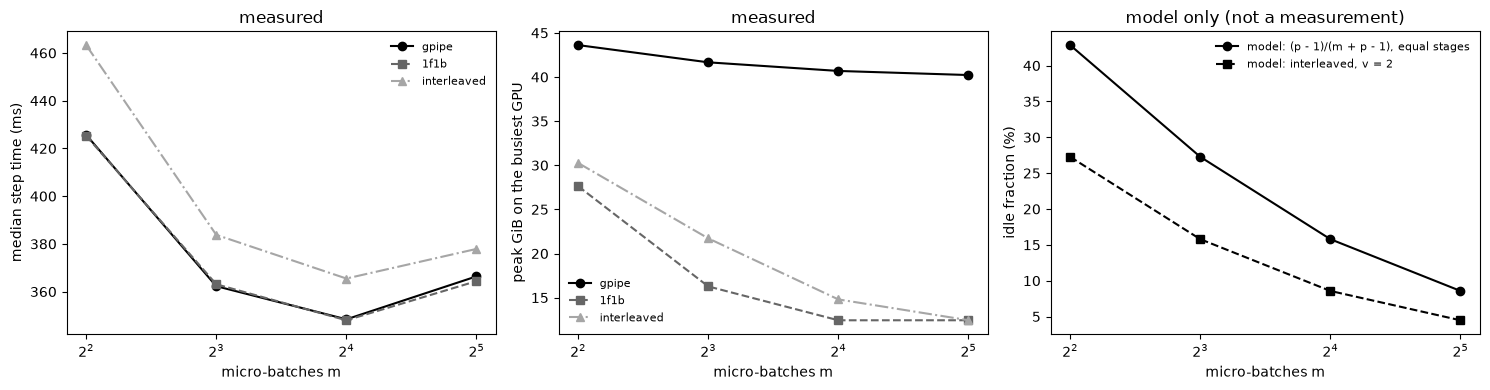

In [24]:
df = pd.DataFrame(partD); p = 4
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
styles = {'gpipe': dict(color='0.0', marker='o', ls='-'), '1f1b': dict(color='0.4', marker='s', ls='--'),
          'interleaved': dict(color='0.65', marker='^', ls='-.')}
for s, st in styles.items():
    d = df[df.schedule == s]
    ax[0].plot(d.microbatches, d.step_ms_median, label=s, **st)
    ax[1].plot(d.microbatches, d.peak_gb, label=s, **st)
m = sorted(df.microbatches.unique())
ax[2].plot(m, [100 * (p - 1) / (x + p - 1) for x in m], 'k-', marker='o', label='model: (p - 1)/(m + p - 1), equal stages')
ax[2].plot(m, [100 * (p - 1) / (2 * x + p - 1) for x in m], 'k--', marker='s', label='model: interleaved, v = 2')
ax[0].set(xlabel='micro-batches m', ylabel='median step time (ms)', title='measured')
ax[1].set(xlabel='micro-batches m', ylabel='peak GiB on the busiest GPU', title='measured')
ax[2].set(xlabel='micro-batches m', ylabel='idle fraction (%)', title='model only (not a measurement)')
for x in ax: x.set_xscale('log', base=2); x.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

**What to check**
- *GPipe and 1F1B* take the same time at each m (first run: 424.4 and 425.5 ms at m = 4), as the model says. 1F1B's peak memory falls as m grows (27.6 to 12.4 GiB) while GPipe's stays near 43.6 GiB: GPipe keeps the activations of all m micro-batches, 1F1B at most p_pp.
- *Interleaved is slower than 1F1B at every m* in our runs (463.7 against 425.5 ms at m = 4), even though its modelled bubble is about half. Interleaving shortens the fill and drain but doubles the number of stage boundaries each micro-batch crosses, and each virtual stage has only 2 layers, so the fixed cost per stage (send/recv, synchronization, launching the stage) is a larger share of its time. The unequal last stage also sets the pace for everyone. Measured per rank at m = 8 (profiled step, `profiles/D`). 1F1B: rank 0 computes 206.6 of 366.8 ms, rank 1 computes 200.5 of 366.8 ms, rank 2 computes 199.2 of 366.8 ms, rank 3 computes 277.2 of 366.7 ms. Interleaved: rank 0 computes 220.5 of 389.3 ms, rank 1 computes 213.0 of 389.3 ms, rank 2 computes 206.7 of 389.2 ms, rank 3 computes 286.8 of 389.2 ms. The last rank, which holds the output layer and the loss, computes the most in both schedules and the others wait for it. In the interleaved trace one forward of the last virtual stage (layers 14 and 15, the output layer and the loss) takes 7.6 ms against 4.1 ms for the same rank's other stage (layers 6 and 7). SendRecv kernels per step on rank 1: 21 with 1F1B, 64 interleaved. Waiting shows up as time inside those SendRecv kernels, not as an idle GPU: an NCCL receive occupies the GPU until the data arrives.
- *Step time does not keep falling with m.* At m = 32 each micro-batch is one sequence, the matmuls are smaller and less efficient, and there are 32 rounds of per-micro-batch overhead. That is why the m = 32 runs are slower than m = 16 here, and why real runs pick m around 4 to 8 times p_pp. The lecture's advice to use m much larger than p_pp is about the bubble only; kernel efficiency and per-micro-batch overhead set the other side of the tradeoff.
- Do not estimate the bubble by comparing step times across m: the time of one micro-batch is not proportional to its size, so the comparison mixes the bubble with kernel efficiency. Measure each rank's compute time in a trace instead (next cell): the rest of the step is waiting, whether it shows as an idle GPU or as a receive kernel.

**Questions**
1. In the 1F1B traces, which rank spends the most time computing, and why that one? What would you change in `build_pipeline` to balance the stages?
2. Why can a schedule with a smaller theoretical bubble take longer per step? Name two costs the bubble model leaves out.
3. Try `--schedule zb` (interleaved zero bubble), which splits each backward into the input gradient and the weight gradient and uses the weight part to fill gaps (the lecture's pipeline schedules table). Does it beat 1F1B here?

In [25]:
# Optional, off by default: record 2 profiled steps of each run on ranks 0,1,2,3. All four ranks, because the bubble is ranks waiting for each other.
if PROFILE:
    prof_D = profile_pair('D', [('1f1b_m8', '--mode pp --schedule 1f1b --microbatches 8 --model 1B --global-batch 32'),
                       ('interleaved_m8', '--mode pp --schedule interleaved --microbatches 8 --model 1B --global-batch 32')], gpus=4, ranks='0,1,2,3')
    display(prof_D)
else:
    print('Profiling is off (PROFILE = False in the helpers cell). The figure below comes from traces recorded on 8 x H100.')

Profiling is off (PROFILE = False in the helpers cell). The figure below comes from traces recorded on 8 x H100.


**One measured 1F1B step, all four ranks, m = 8** (from `profiles/D`, same time axis). The hatched SendRecv kernels are where a rank waits for its neighbour: long ones at the start of ranks 1 to 3 are the fill, long ones at the end of ranks 0 to 2 the drain. Rank 3 has the densest compute.


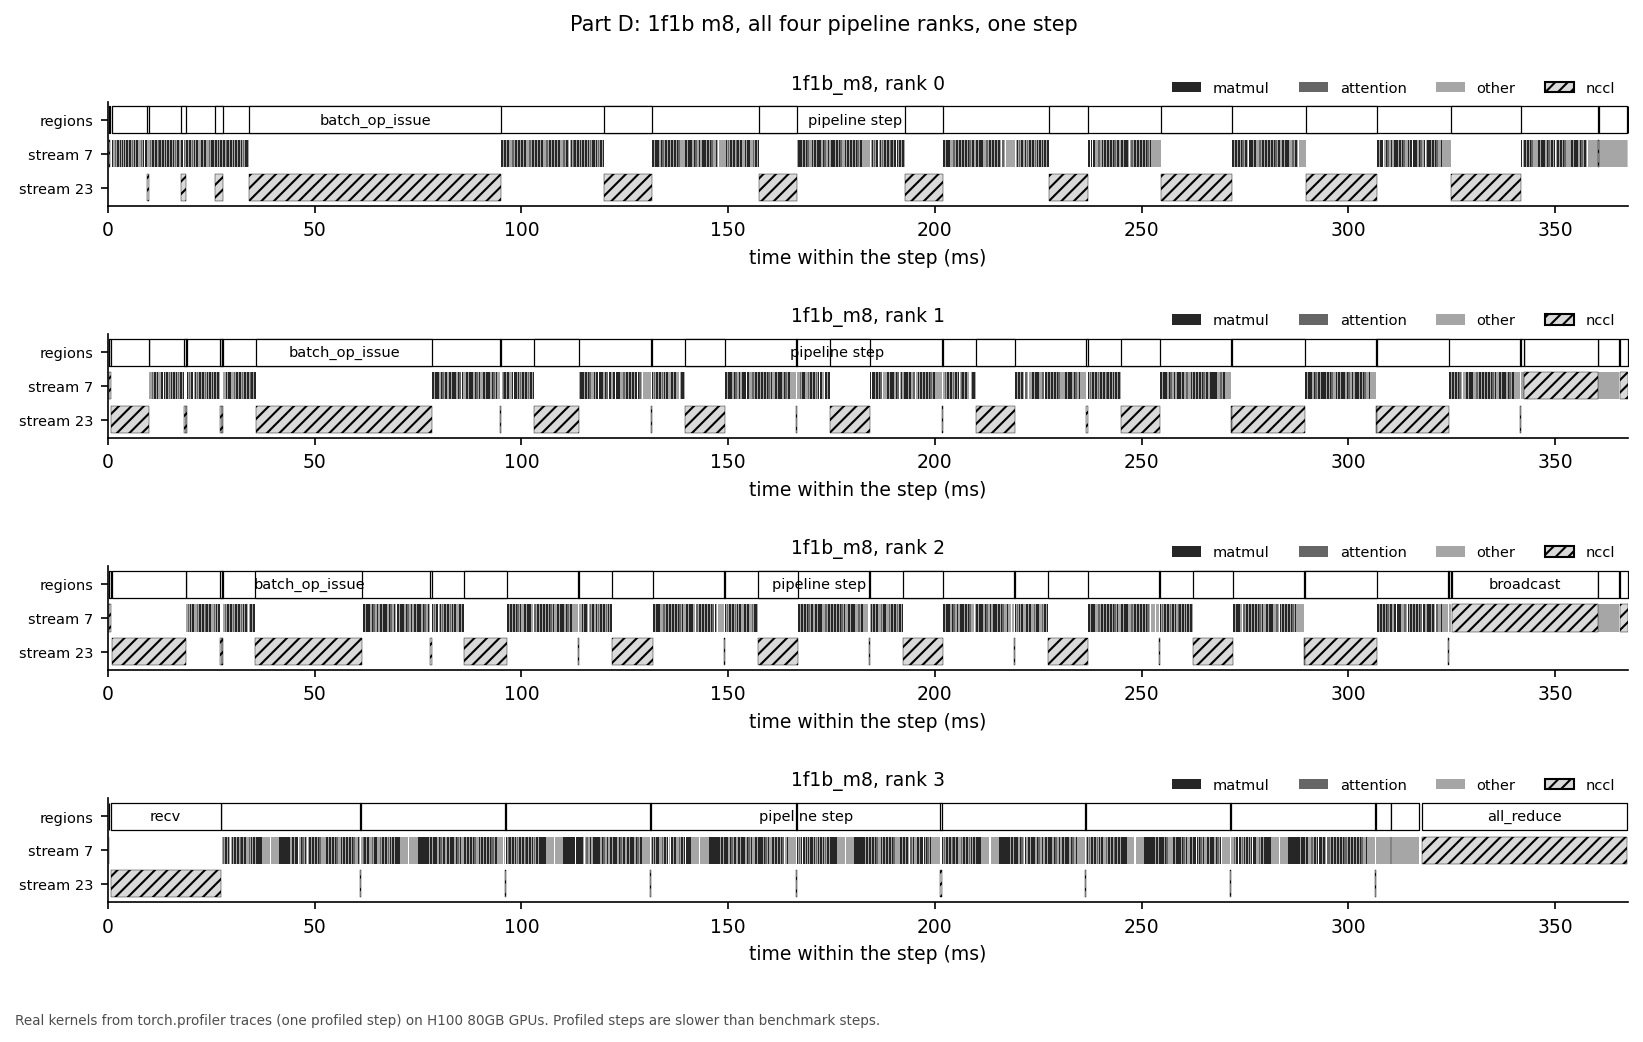

**The same for interleaved 1F1B.** Several times more SendRecv kernels per rank, and shorter compute segments between them.


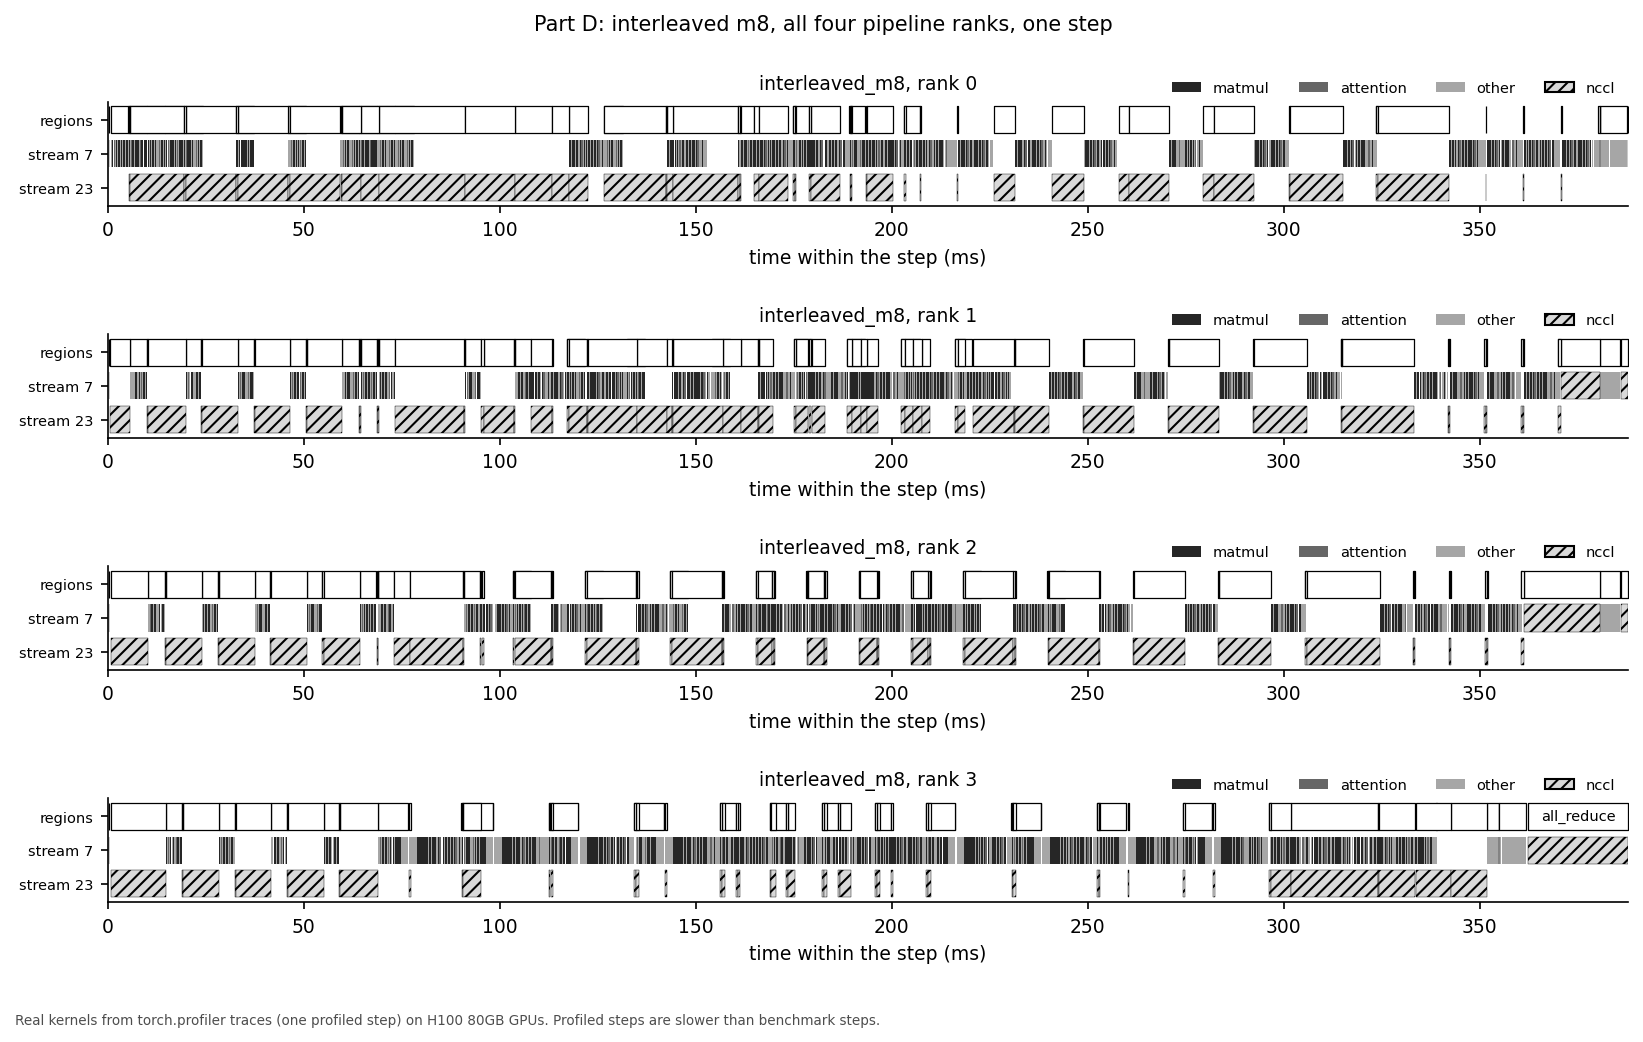

## Part E: Context parallelism for long sequences (lecture: context parallelism)

**What we are doing.** The 1B model with FSDP2 over all 8 GPUs and context parallelism over c GPUs, at 8K to 64K tokens per sequence. Each data-parallel group trains one sequence per step. With c = 1 there are 8 groups of one GPU, each holding a whole sequence (global batch 8). With c = 8 there is one group: every GPU holds s/8 tokens of the same sequence (global batch 1). Tokens per step therefore differ by 8 between the c = 1 and c = 8 rows at the same s; tokens per GPU are the same at s for c = 1 and at 8s for c = 8.

**What to notice.** `context_parallel(...)` shards the input ids, the targets and the RoPE table along the sequence dimension for the duration of the step, and replaces `scaled_dot_product_attention` with a distributed version. Each sequence is cut into 2c chunks and GPU i gets chunks i and 2c − 1 − i, so every GPU has the same amount of work under the causal mask. Queries stay local; keys and values must be seen by every GPU. `--rotate allgather` all-gathers K and V once per layer (what Llama 3 did); `--rotate alltoall` passes K, V blocks around a ring and overlaps each transfer with attention on the block it already has. The model has 8 KV heads of 64 dimensions, but `Attention.forward` expands K and V to one copy per query head (`repeat_interleave`, 32 heads) before it calls `scaled_dot_product_attention`, and that call is what context parallelism replaces. So what CP exchanges per layer at 64K tokens is 2 × 64K × 2048 × 2 bytes = 512 MiB of K and V, four times what the 8 KV heads alone would need. Doing the expansion after the exchange would move four times less; this lab does not test that.

**What to expect.** Activation memory per GPU depends on tokens per GPU, so c = 8 at 64K should look like c = 1 at 8K. The lecture describes the ring as hiding each transfer behind attention and Llama 3 as using an all-gather; both are tested below, on NVLink at 64K tokens, not across nodes at 131K. Attention FLOPs per token grow linearly with s.

In [26]:
partE = []
for seq in [8192, 16384, 32768, 65536]:
    for c in [1, 8]:
        partE.append(run(f'--mode cp --cp {c} --model 1B --seq {seq} --global-batch {8 // c} --steps 10 --warmup 3 '
                         f'--tag "s={seq // 1024}K cp={c}"'))
partE.append(run('--mode cp --cp 8 --rotate alltoall --model 1B --seq 65536 --global-batch 1 --steps 10 --warmup 3 --tag "s=64K cp=8 ring"'))
table(partE, extra=['seq', 'cp', 'tokens_per_gpu_per_step', 'tokens_per_s_per_gpu', 'mfu_causal'])

$ torchrun --standalone --nproc_per_node=8 train.py --mode cp --cp 1 --model 1B --seq 8192 --global-batch 8 --steps 10 --warmup 3 --tag "s=8K cp=1"


   model 1B: 0.85B parameters, 16 layers, h = 2048, seq 8192, 8 GPUs
   -> ok: 141.9 ms/step (median 141.3, p10-p90 140.1-144.2), 461,846 tokens/s, MFU 46.4%, peak 14.215 GB, state 1.218 GB
$ torchrun --standalone --nproc_per_node=8 train.py --mode cp --cp 8 --model 1B --seq 8192 --global-batch 1 --steps 10 --warmup 3 --tag "s=8K cp=8"


   model 1B: 0.85B parameters, 16 layers, h = 2048, seq 8192, 8 GPUs
   -> ok: 147.2 ms/step (median 146.5, p10-p90 146.2-148.8), 55,652 tokens/s, MFU 5.6%, peak 3.362 GB, state 1.218 GB
$ torchrun --standalone --nproc_per_node=8 train.py --mode cp --cp 1 --model 1B --seq 16384 --global-batch 8 --steps 10 --warmup 3 --tag "s=16K cp=1"


   model 1B: 0.85B parameters, 16 layers, h = 2048, seq 16384, 8 GPUs
   -> ok: 333.9 ms/step (median 330.9, p10-p90 329.5-341.1), 392,549 tokens/s, MFU 55.4%, peak 27.212 GB, state 1.217 GB
$ torchrun --standalone --nproc_per_node=8 train.py --mode cp --cp 8 --model 1B --seq 16384 --global-batch 1 --steps 10 --warmup 3 --tag "s=16K cp=8"


   model 1B: 0.85B parameters, 16 layers, h = 2048, seq 16384, 8 GPUs
   -> ok: 167.5 ms/step (median 167.5, p10-p90 167.3-167.6), 97,815 tokens/s, MFU 13.8%, peak 4.722 GB, state 1.236 GB
$ torchrun --standalone --nproc_per_node=8 train.py --mode cp --cp 1 --model 1B --seq 32768 --global-batch 8 --steps 10 --warmup 3 --tag "s=32K cp=1"


   model 1B: 0.85B parameters, 16 layers, h = 2048, seq 32768, 8 GPUs
   -> ok: 936.9 ms/step (median 936.8, p10-p90 933.1-941.0), 279,799 tokens/s, MFU 62.3%, peak 53.211 GB, state 1.222 GB
$ torchrun --standalone --nproc_per_node=8 train.py --mode cp --cp 8 --model 1B --seq 32768 --global-batch 1 --steps 10 --warmup 3 --tag "s=32K cp=8"


   model 1B: 0.85B parameters, 16 layers, h = 2048, seq 32768, 8 GPUs
   -> ok: 272.3 ms/step (median 272.2, p10-p90 271.9-272.9), 120,338 tokens/s, MFU 26.8%, peak 7.992 GB, state 1.234 GB
$ torchrun --standalone --nproc_per_node=8 train.py --mode cp --cp 1 --model 1B --seq 65536 --global-batch 8 --steps 10 --warmup 3 --tag "s=64K cp=1"


   model 1B: 0.85B parameters, 16 layers, h = 2048, seq 65536, 8 GPUs
   OUT OF MEMORY: CUDA out of memory. Tried to allocate 256.00 MiB. GPU 0 has a total capacity of 79.18 GiB of which 81.81 MiB is free. Including non-PyTorch memory, this process has 79.09 GiB memory in use. Of the allocated memory 76.97 GiB is allocated by PyTorch, and 212.43 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)
   -> OOM: peak 76.972 GB when it failed
$ torchrun --standalone --nproc_per_node=8 train.py --mode cp --cp 8 --model 1B --seq 65536 --global-batch 1 --steps 10 --warmup 3 --tag "s=64K cp=8"


   model 1B: 0.85B parameters, 16 layers, h = 2048, seq 65536, 8 GPUs
   -> ok: 535.7 ms/step (median 535.6, p10-p90 534.3-537.5), 122,337 tokens/s, MFU 47.1%, peak 14.75 GB, state 1.233 GB
$ torchrun --standalone --nproc_per_node=8 train.py --mode cp --cp 8 --rotate alltoall --model 1B --seq 65536 --global-batch 1 --steps 10 --warmup 3 --tag "s=64K cp=8 ring"


   model 1B: 0.85B parameters, 16 layers, h = 2048, seq 65536, 8 GPUs
   -> ok: 641.8 ms/step (median 642.0, p10-p90 641.0-642.3), 102,113 tokens/s, MFU 39.4%, peak 14.751 GB, state 1.234 GB


,tag,seq,cp,tokens_per_gpu_per_step,tokens_per_s_per_gpu,mfu_causal,status,seqs_per_gpu,step_ms,step_ms_median,tokens_per_s,mfu,peak_gb,state_gb
0,s=8K cp=1,8192,1,8192,57731.000000,0.369700,ok,1,141.900000,141.300000,"461,846",46.4%,14.215000,1.218000
1,s=8K cp=8,8192,8,1024,6957.000000,0.044500,ok,1,147.200000,146.500000,"55,652",5.6%,3.362000,1.218000
2,s=16K cp=1,16384,1,16384,49069.000000,0.394100,ok,1,333.900000,330.900000,"392,549",55.4%,27.212000,1.217000
3,s=16K cp=8,16384,8,2048,12227.000000,0.098200,ok,1,167.500000,167.500000,"97,815",13.8%,4.722000,1.236000
4,s=32K cp=1,32768,1,32768,34975.000000,0.394800,ok,1,936.900000,936.800000,"279,799",62.3%,53.211000,1.222000
5,s=32K cp=8,32768,8,4096,15042.000000,0.169800,ok,1,272.300000,272.200000,"120,338",26.8%,7.992000,1.234000
6,s=64K cp=1,65536,1,65536,OOM,OOM,OOM,1,OOM,OOM,OOM,OOM,76.972000,0.839000
7,s=64K cp=8,65536,8,8192,15292.000000,0.272200,ok,1,535.700000,535.600000,"122,337",47.1%,14.750000,1.233000
8,s=64K cp=8 ring,65536,8,8192,12764.000000,0.227200,ok,1,641.800000,642.000000,"102,113",39.4%,14.751000,1.234000


**What to check**
- *Memory.* With c = 1, peak memory grows with s until 64K does not fit. With c = 8, `s=64K cp=8` peaks at 14.8 GiB, close to `s=8K cp=1` at 14.2 GiB: same 8K tokens per GPU.
- *Throughput within c = 8 rises with s* (first run: 54,625, 96,991, 119,688, 120,858 tokens/s from 8K to 64K), even though attention costs more per token at longer s. Each step also has a cost that does not depend on s: FSDP all-gathers and reduce-scatters all 0.85B parameters, the optimizer updates them, and the CP machinery runs per layer on the CPU. At 8K each GPU has only 1K tokens, so that fixed cost is most of the step; at 64K it is spread over 8K tokens per GPU. In the profiled steps (rank 0, `profiles/E`): at 8K tokens with c = 8 the GPU was idle 137.9 of 226.6 ms per step (61%), with 6.6 ms of attention kernels and 54.0 ms of NCCL kernels; at 64K it was idle 6% of the step, with 282.1 ms of attention kernels.
- *MFU at long s.* The `mfu` column counts the full s × s attention; the causal kernel does half of it. At 32K tokens the attention term is most of the counted FLOPs, so `mfu` overstates the useful work; `mfu_causal` is the fairer number.
- *All-gather against ring.* All-gather was faster here (542.3 against 627.3 ms at 64K): on NVLink, one gather of 512 MiB per layer costs less than the ring's seven smaller steps with their synchronization. In the traces, the all-gather version spends 54.7 ms per step on NCCL that no compute overlapped, the ring version 156.6 ms. The ring's advantage, never holding all of K and V, matters when they are large (many KV heads, very long s) or the links are slow.

**Questions**
1. At which sequence length did c = 1 run out of memory, and what was the peak per GPU with c = 8 at that length?
2. Compare `tokens_per_s_per_gpu` for `s=8K cp=1` and `s=64K cp=8`: both hold 8K tokens per GPU. Why is one much faster per GPU?

In [27]:
# Optional, off by default: record 2 profiled steps of each run on rank 0.
if PROFILE:
    prof_E = profile_pair('E', [('allgather_64K', '--mode cp --cp 8 --model 1B --seq 65536 --global-batch 1'),
                       ('ring_64K', '--mode cp --cp 8 --rotate alltoall --model 1B --seq 65536 --global-batch 1')], gpus=8, ranks='0')
    display(prof_E)
else:
    print('Profiling is off (PROFILE = False in the helpers cell). The figure below comes from traces recorded on 8 x H100.')

Profiling is off (PROFILE = False in the helpers cell). The figure below comes from traces recorded on 8 x H100.


**One measured step at 64K tokens, c = 8, GPU 0** (from `profiles/E`). The all-gather version shows one gather of K and V before each layer's attention; the ring version shows a series of SendRecv steps interleaved with partial attention kernels.


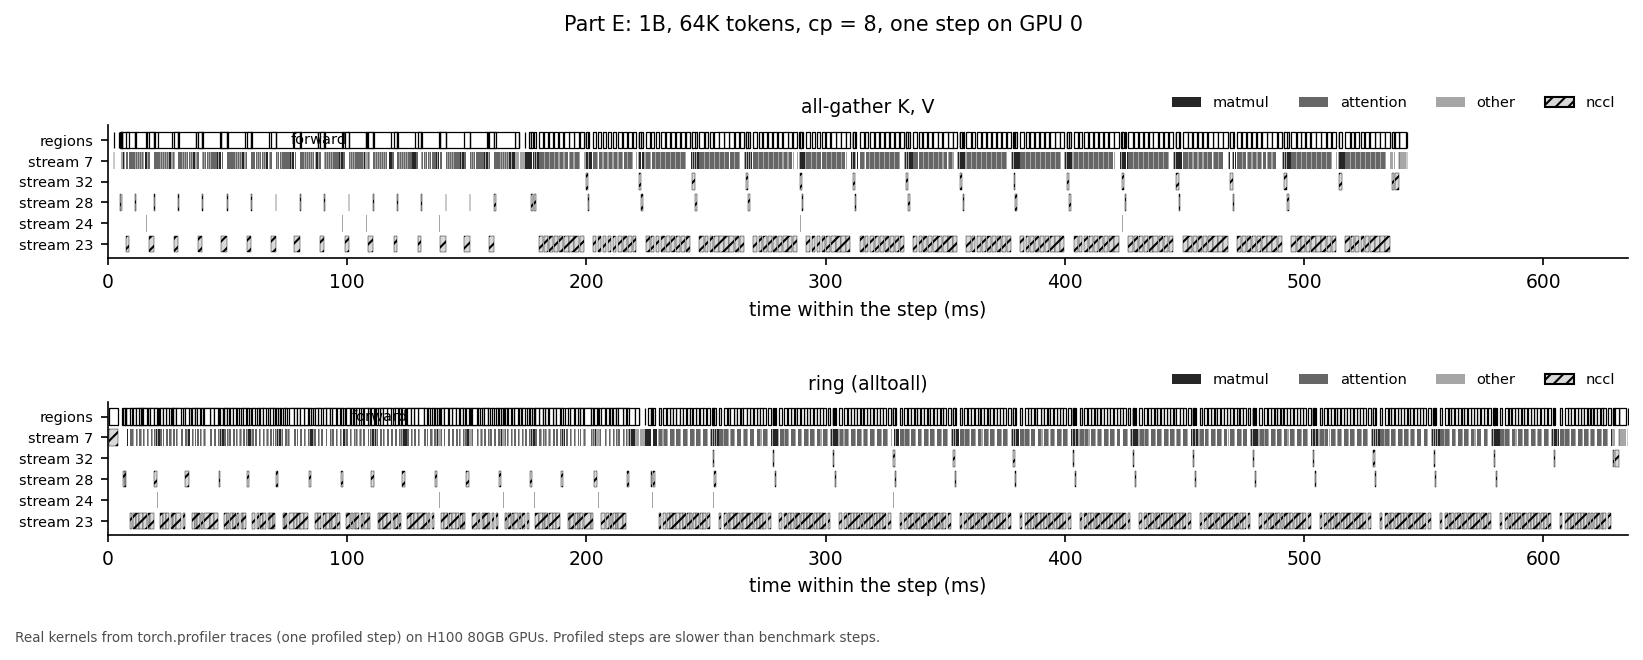

## Part F: Distributed checkpoint, saved on 8 GPUs and resumed on 8 and on 4 (lecture: distributed checkpointing)

**What we are doing.** Train 10 steps of the 1B model on 8 GPUs and save with `torch.distributed.checkpoint` (DCP). Then start fresh jobs that load it and continue from step 10: one on 8 GPUs (the control) and one on 4 GPUs (resharding). Compare both with a run that never stopped.

**What to notice in `train.py`.** `get_state_dict(model, opt)` returns the model and optimizer state as DTensors with their sharding; `dcp.save` has every rank write its own shards in parallel plus one `.metadata` file that records which piece of which tensor is in which file. On load, `dcp.load` reads that metadata, and each rank of the new layout reads exactly the byte ranges it now owns; `set_state_dict` puts them back into the FSDP model and the Adam state. `--start-step 10` restores the two things DCP does not save here: the learning-rate schedule position and the position in the data. The model has no dropout, so there is no RNG state to restore.

**What to expect.** Load success alone does not prove a mathematically identical continuation. Resuming on the same 8 GPUs repeats the same reductions in the same order, so it should track the uninterrupted run closely. Resuming on 4 GPUs sums each gradient from 4 partial sums instead of 8 and gives each GPU 4 sequences instead of 2, so the continuation is equivalent in exact arithmetic but not bit-identical in BF16.

$ torchrun --standalone --nproc_per_node=8 train.py --mode fsdp --model 1B --steps 10 --warmup 3 --save ckpt_step10 --tag "steps 0-9 on 8 GPUs"


   model 1B: 0.85B parameters, 16 layers, h = 2048, seq 2048, 8 GPUs
   saved ckpt_step10: every rank wrote its own shards
   -> ok: 75.0 ms/step (median 74.2, p10-p90 74.0-77.2), 436,907 tokens/s, MFU 30.5%, peak 7.718 GB, state 1.219 GB
$ torchrun --standalone --nproc_per_node=4 train.py --mode fsdp --model 1B --steps 10 --warmup 3 --load ckpt_step10 --start-step 10 --tag "steps 10-19 on 4 GPUs"


   model 1B: 0.85B parameters, 16 layers, h = 2048, seq 2048, 4 GPUs
   resumed from ckpt_step10 on 4 GPUs
   -> ok: 117.0 ms/step (median 115.9, p10-p90 115.3-119.2), 280,068 tokens/s, MFU 39.1%, peak 15.502 GB, state 2.505 GB
$ torchrun --standalone --nproc_per_node=8 train.py --mode fsdp --model 1B --steps 10 --warmup 3 --load ckpt_step10 --start-step 10 --tag "steps 10-19 on 8 GPUs"


   model 1B: 0.85B parameters, 16 layers, h = 2048, seq 2048, 8 GPUs
   resumed from ckpt_step10 on 8 GPUs
   -> ok: 88.6 ms/step (median 74.8, p10-p90 74.6-113.7), 369,842 tokens/s, MFU 25.8%, peak 7.714 GB, state 1.215 GB
$ torchrun --standalone --nproc_per_node=8 train.py --mode fsdp --model 1B --steps 20 --warmup 3 --tag "steps 0-19 on 8 GPUs, no restart"


   model 1B: 0.85B parameters, 16 layers, h = 2048, seq 2048, 8 GPUs
   -> ok: 75.0 ms/step (median 74.7, p10-p90 74.5-76.6), 436,907 tokens/s, MFU 30.5%, peak 7.718 GB, state 1.219 GB
total 9997368
drwxr-xr-x 2 user     user           4096 Nov 23 08:31 .
drwxr-xr-x 4 user     user           4096 Nov 23 08:31 ..
-rw-r--r-- 1 user     user     1279535265 Nov 23 08:31 __0_0.distcp
-rw-r--r-- 1 user     user     1279570904 Nov 23 08:31 __1_0.distcp
-rw-r--r-- 1 user     user     1279570904 Nov 23 08:31 __2_0.distcp
-rw-r--r-- 1 user     user     1279570904 Nov 23 08:31 __3_0.distcp
-rw-r--r-- 1 user     user     1279570904 Nov 23 08:31 __4_0.distcp
-rw-r--r-- 1 user     user     1279576152 Nov 23 08:31 __5_0.distcp
-rw-r--r-- 1 user     user     1279569643 Nov 23 08:31 __6_0.distcp
-rw-r--r-- 1 user     user     1279569643 Nov 23 08:31 __7_0.distcp
-rw-r--r-- 1 user     user         741415 Nov 23 08:31 .metadata


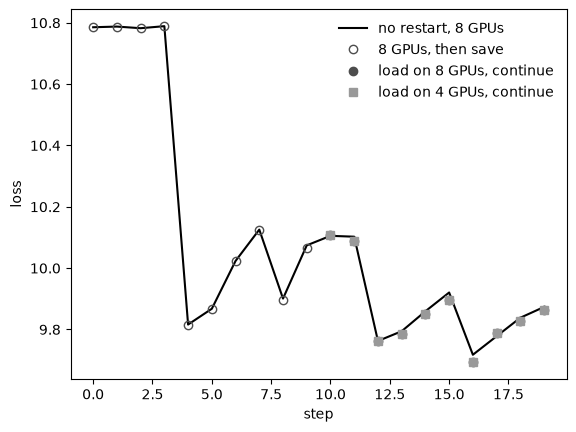

largest difference from the uninterrupted run, steps 10-19: 8 GPUs 0.0241, 4 GPUs 0.0240


In [28]:
import shutil; shutil.rmtree('ckpt_step10', ignore_errors=True)
f1 = run('--mode fsdp --model 1B --steps 10 --warmup 3 --save ckpt_step10 --tag "steps 0-9 on 8 GPUs"', gpus=8)
f2 = run('--mode fsdp --model 1B --steps 10 --warmup 3 --load ckpt_step10 --start-step 10 --tag "steps 10-19 on 4 GPUs"', gpus=4)
f3 = run('--mode fsdp --model 1B --steps 10 --warmup 3 --load ckpt_step10 --start-step 10 --tag "steps 10-19 on 8 GPUs"', gpus=8)
ref = run('--mode fsdp --model 1B --steps 20 --warmup 3 --tag "steps 0-19 on 8 GPUs, no restart"', gpus=8)
!ls -la ckpt_step10
plt.plot(range(20), ref['losses'], 'k-', label='no restart, 8 GPUs')
plt.plot(range(10), f1['losses'], 'o', color='0.3', mfc='none', label='8 GPUs, then save')
plt.plot(range(10, 20), f3['losses'], 'o', color='0.3', label='load on 8 GPUs, continue')
plt.plot(range(10, 20), f2['losses'], 's', color='0.6', label='load on 4 GPUs, continue')
plt.xlabel('step'); plt.ylabel('loss'); plt.legend(frameon=False); plt.show()
print('largest difference from the uninterrupted run, steps 10-19:',
      f"8 GPUs {max(abs(a - b) for a, b in zip(f3['losses'], ref['losses'][10:])):.4f},",
      f"4 GPUs {max(abs(a - b) for a, b in zip(f2['losses'], ref['losses'][10:])):.4f}")

**What to check:** the folder has one `.distcp` file per rank and a `.metadata` file (`ls -la`, because a plain `ls` hides dot files). Both resumed runs continue the black line. In the follow-up runs, resuming on 8 GPUs stayed within 0.0587 of the uninterrupted run over steps 10 to 19 (first resumed step: 0.0059); resuming on 4 GPUs started within 0.0059 and drifted to 0.0589. If you remove the `set_state_dict` call in `train.py`, the loss jumps at step 10: the weights would still be the freshly initialized ones and Adam would restart from zero.

**Questions**
1. Why does the checkpoint have one file per rank and not one file? What would a single file cost at 405B parameters?
2. The 4-GPU continuation drifts slowly away from the uninterrupted run. Is that a checkpointing bug? What experiment above tells you?

## Part G: The same on a Hugging Face model (lecture: FSDP2 and tensor parallelism)

**What we are doing.** Qwen2.5-1.5B with real text (Tiny Shakespeare), loaded with `from_pretrained` and wrapped three ways:
- DDP on 8 GPUs (FP32 weights, BF16 autocast).
- FSDP2 on 8 GPUs: `fully_shard` on each `model.model.layers[i]`, then on the model. The same two lines as in the lecture's FSDP2 code example; no change to the model code.
- Tensor parallelism on 2 GPUs with `from_pretrained(..., tp_plan="auto")`: transformers applies the model's own plan (q, k, v, gate and up by columns; o and down by rows). Qwen2.5-1.5B has 2 key-value heads, so t can be at most 2. Both GPUs see the same sequences (dp = 1).

**Workload.** Global batch 8 sequences of 1024 tokens in every run (the first run used 16; TP with FP32 master weights does not fit at 16 on 2 GPUs, because each GPU then holds the FP32 logits of 16 × 1024 tokens over a 151,936-token vocabulary, 9.3 GiB, on top of the rest). DDP and FSDP2 put 1 sequence on each GPU, TP puts all 8 on each of its 2 GPUs.

**Why the TP dtype matters.** The first run loaded the TP model in BF16 and trained it in pure BF16, so its weights and Adam state were BF16 while DDP and FSDP2 kept FP32 master weights. At lr = 1e-5, Adam's first update is about 1e-5 per weight, and a BF16 number of size w can only change in steps of w/256 to w/128 (8 significant bits); for a weight of 0.02 that step is about 8e-5, and an update smaller than half a step rounds back to the old value. `hf_train.py` now loads the TP model in FP32 and uses autocast like DDP (`--tp-dtype fp32`); `--tp-dtype bf16` reproduces the first-run setup. `update_frac_changed` reports the fraction of weights the first step actually changed.

Needs access to the Hugging Face Hub and raw.githubusercontent.com from the node.

In [29]:
%%writefile hf_train.py
"""The same ideas on a real Hugging Face model (default Qwen/Qwen2.5-1.5B) and real text.

  torchrun --standalone --nproc_per_node=8 hf_train.py --mode fsdp
  torchrun --standalone --nproc_per_node=2 hf_train.py --mode tp      # transformers' built-in tensor-parallel plan

Modes: ddp | fsdp (FSDP2 on each decoder layer) | tp (from_pretrained(tp_plan="auto"), all GPUs in one TP group).
Needs the Hub (model weights) and, for real text, raw.githubusercontent.com. Without the text it falls back to random tokens.

Precision: all three modes keep FP32 master weights and compute in BF16, so their losses can be
compared. The first run loaded the TP model in BF16 and trained it in pure BF16 (BF16 weights and
BF16 Adam state); --tp-dtype bf16 reproduces that. With lr = 1e-5, a BF16 weight of size w only changes
when the update is larger than about w / 256, so most updates round away (see update_frac_changed).
"""
import argparse
import datetime
import json
import os
import time
import urllib.request

import torch
import torch.distributed as dist
from torch.distributed.tensor import DTensor
from transformers import AutoModelForCausalLM, AutoTokenizer

import benchmark_utils as bu
from hpml_parallel import MixedPrecisionPolicy, fully_shard

TEXT_URL = 'https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt'


def load_tokens(tok, seq, n_seq):
    try:
        text = urllib.request.urlopen(TEXT_URL, timeout=20).read().decode()
        ids = tok(text, return_tensors='pt').input_ids[0]
        n = min(n_seq, (len(ids) - 1) // (seq + 1))
        return ids[: n * (seq + 1)].view(n, seq + 1), 'tiny shakespeare'
    except Exception as e:
        print('no text download, using random tokens:', e, flush=True)
        g = torch.Generator().manual_seed(1234)
        return torch.randint(0, tok.vocab_size, (n_seq, seq + 1), generator=g), 'random tokens'


def local(t):
    return t.to_local() if isinstance(t, DTensor) else t


def main():
    p = argparse.ArgumentParser()
    p.add_argument('--mode', required=True, choices=['ddp', 'fsdp', 'tp'])
    p.add_argument('--name', default='Qwen/Qwen2.5-1.5B')
    p.add_argument('--seq', type=int, default=1024)
    p.add_argument('--global-batch', type=int, default=16)
    p.add_argument('--steps', type=int, default=20)
    p.add_argument('--warmup', type=int, default=5)
    p.add_argument('--lr', type=float, default=1e-5)
    p.add_argument('--tp-dtype', default='fp32', choices=['fp32', 'bf16'],
                   help='tp mode weights: fp32 master + BF16 autocast (default), or pure BF16 (original lab)')
    p.add_argument('--tag', default='')
    p.add_argument('--out', default='results_hf.jsonl')
    a = p.parse_args()

    dist.init_process_group('nccl', timeout=datetime.timedelta(minutes=10))
    rank, W = dist.get_rank(), dist.get_world_size()
    dev = torch.device('cuda', int(os.environ['LOCAL_RANK']))
    torch.cuda.set_device(dev)
    say = (lambda *m: print(*m, flush=True)) if rank == 0 else (lambda *m: None)

    tok = AutoTokenizer.from_pretrained(a.name)
    data, source = load_tokens(tok, a.seq, 256)
    if a.mode == 'tp':
        # transformers reads the model's own TP plan (q, k, v, gate, up by columns; o, down by rows)
        # and builds a TP mesh over all W GPUs. Every GPU sees the same sequences (dp = 1).
        dtype = torch.float32 if a.tp_dtype == 'fp32' else torch.bfloat16
        model = AutoModelForCausalLM.from_pretrained(a.name, torch_dtype=dtype, tp_plan='auto')
        dp, dp_rank = 1, 0
        amp = a.tp_dtype == 'fp32'
    else:
        model = AutoModelForCausalLM.from_pretrained(a.name, torch_dtype=torch.float32).to(dev)
        dp, dp_rank = W, rank
        if a.mode == 'ddp':
            model = torch.nn.parallel.DistributedDataParallel(model, device_ids=[dev.index])
            amp = True
        else:
            mp = MixedPrecisionPolicy(param_dtype=torch.bfloat16, reduce_dtype=torch.float32)
            for layer in model.model.layers:
                fully_shard(layer, mp_policy=mp)
            fully_shard(model, mp_policy=mp)
            amp = False       # FSDP's policy already casts the weights to BF16 for compute
    say(f'{a.name} | mode {a.mode} | {W} GPUs | data: {source}')
    # the TP plan leaves the norm weights as plain tensors next to DTensors; the fused (foreach)
    # AdamW cannot mix the two, so use the per-tensor loop only in that case.
    params = list(model.parameters())
    mixed = len({isinstance(q, DTensor) for q in params}) > 1
    opt = torch.optim.AdamW(params, lr=a.lr, weight_decay=0.0, foreach=not mixed)
    per = a.global_batch // dp
    times, losses, frac_changed = [], [], None
    for i in range(a.steps):
        rows = data[[(i * a.global_batch + j) % len(data) for j in range(a.global_batch)]]
        ids = rows[dp_rank * per:(dp_rank + 1) * per].to(dev)
        if i == a.warmup:
            torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()
        dist.barrier()
        t0 = time.perf_counter()
        with torch.autocast('cuda', dtype=torch.bfloat16, enabled=amp):
            loss = model(input_ids=ids, labels=ids).loss      # the model shifts the labels itself
        loss.backward()
        if i == 0:
            before = [local(q).detach().clone() for q in params]
        opt.step()
        if i == 0:
            # fraction of this GPU's weight elements that the first update changed at all
            changed = sum((local(q).detach() != b).sum().item() for q, b in zip(params, before))
            total = sum(b.numel() for b in before)
            frac_changed = changed / total
            del before
        opt.zero_grad(set_to_none=True)
        l = loss.detach().float()
        dist.all_reduce(l, op=dist.ReduceOp.AVG)
        torch.cuda.synchronize()
        t = torch.tensor([time.perf_counter() - t0], device=dev)
        dist.all_reduce(t, op=dist.ReduceOp.MAX)
        losses.append(round(l.item(), 4))
        if i >= a.warmup:
            times.append(t.item())
        say(f'step {i:3d}  loss {l.item():.4f}  {t.item() * 1e3:8.1f} ms')
    peak = torch.tensor([torch.cuda.max_memory_allocated()], device=dev, dtype=torch.float64)
    dist.all_reduce(peak, op=dist.ReduceOp.MAX)
    state = torch.tensor([torch.cuda.memory_allocated()], device=dev, dtype=torch.float64)
    dist.all_reduce(state, op=dist.ReduceOp.MAX)
    st = bu.time_stats(times)
    step_s = st['step_ms'] / 1e3
    res = dict(tag=a.tag, mode=a.mode, model=a.name, gpus=W, seq=a.seq, global_batch=a.global_batch,
               step_ms=st['step_ms'], tokens_per_s=round(a.global_batch * a.seq / step_s),
               peak_gb=round(peak.item() / 2**30, 2), losses=losses, data=source, torch=torch.__version__,
               status='ok', state_gb=round(state.item() / 2**30, 2), dp=dp, seqs_per_gpu=per,
               weights_dtype='bf16' if (a.mode == 'tp' and a.tp_dtype == 'bf16') else 'fp32',
               update_frac_changed=round(frac_changed, 4), **{k: v for k, v in st.items() if k != 'step_ms'})
    if rank == 0:
        print('RESULT ' + json.dumps(res), flush=True)
        with open(a.out, 'a') as f:
            f.write(json.dumps(res) + '\n')
    dist.destroy_process_group()


if __name__ == '__main__':
    main()

Writing hf_train.py


In [30]:
partG = [run('--mode ddp --global-batch 8 --tag "HF DDP 8"', script='hf_train.py', gpus=8),
         run('--mode fsdp --global-batch 8 --tag "HF FSDP2 8"', script='hf_train.py', gpus=8),
         run('--mode tp --global-batch 8 --tag "HF TP 2, FP32 master weights"', script='hf_train.py', gpus=2),
         run('--mode tp --tp-dtype bf16 --global-batch 8 --tag "HF TP 2, pure BF16 (original lab)"', script='hf_train.py', gpus=2)]
dg = pd.DataFrame(partG)
dg['max_loss_diff_vs_ddp'] = [max(abs(a - b) for a, b in zip(r['losses'], partG[0]['losses'])) for r in partG]
dg[['tag', 'gpus', 'seqs_per_gpu', 'weights_dtype', 'update_frac_changed', 'max_loss_diff_vs_ddp', 'step_ms_median', 'peak_gb', 'state_gb', 'data']]

$ torchrun --standalone --nproc_per_node=8 hf_train.py --mode ddp --global-batch 8 --tag "HF DDP 8"


   -> ok: 139.5 ms/step (median 138.8, p10-p90 138.5-141.3), 58,724 tokens/s, MFU nan%, peak 34.54 GB, state 23.03 GB
$ torchrun --standalone --nproc_per_node=8 hf_train.py --mode fsdp --global-batch 8 --tag "HF FSDP2 8"


   -> ok: 147.6 ms/step (median 147.2, p10-p90 146.9-149.3), 55,501 tokens/s, MFU nan%, peak 7.26 GB, state 2.2 GB
$ torchrun --standalone --nproc_per_node=2 hf_train.py --mode tp --global-batch 8 --tag "HF TP 2, FP32 master weights"


   -> ok: 310.2 ms/step (median 309.2, p10-p90 308.3-313.9), 26,409 tokens/s, MFU nan%, peak 41.11 GB, state 8.63 GB
$ torchrun --standalone --nproc_per_node=2 hf_train.py --mode tp --tp-dtype bf16 --global-batch 8 --tag "HF TP 2, pure BF16 (original lab)"


   -> ok: 283.8 ms/step (median 283.8, p10-p90 282.8-285.2), 28,865 tokens/s, MFU nan%, peak 32.02 GB, state 4.31 GB


,tag,gpus,seqs_per_gpu,weights_dtype,update_frac_changed,max_loss_diff_vs_ddp,step_ms_median,peak_gb,state_gb,data
0,HF DDP 8,8,1,fp32,0.9998,0.0000,138.8,34.54,23.03,tiny shakespeare
1,HF FSDP2 8,8,1,fp32,0.9999,0.0009,147.2,7.26,2.20,tiny shakespeare
2,"HF TP 2, FP32 master weights",2,8,fp32,1.0000,0.0010,309.2,41.11,8.63,tiny shakespeare
3,"HF TP 2, pure BF16 (original lab)",2,8,bf16,0.1135,0.0573,283.8,32.02,4.31,tiny shakespeare


**What to check:** the loss starts near 3.26 (a trained model on English text) and moves around 2.8 to 3.2, with step-to-step noise because each step sees different text. DDP, FSDP2 and TP with FP32 master weights give the same losses to about 3 decimals: the layout does not change the training. Measured at global batch 8: the first optimizer step changed 99.98% of DDP's weights, 100.00% with TP and FP32 master weights, and 11.3% with TP in pure BF16. TP with FP32 master weights follows DDP to within 0.001 at every one of the 20 steps; FSDP2 to within 0.001. Pure BF16 departs by up to 0.06, and in the first run, at global batch 16, by up to 0.26. Over 20 steps the pure-BF16 run is not consistently worse; it is a different trajectory, because most of its small updates are lost.

**Questions**
1. Why does pure BF16 lose updates at lr = 1e-5 but would lose fewer at lr = 1e-3? What does a mixed-precision optimizer keep in FP32, and why?
2. Compare `peak_gb` of the two TP runs and of FSDP2, and explain each difference from what each GPU stores and how many sequences it processes.

## Part H: TorchTitan, the production version of this notebook (lecture: 4D layouts and production recipes)

**What we are doing.** Running TorchTitan, Meta's PyTorch-native trainer for Llama 3 and MoE models, with the 3D layout FSDP 2 × TP 2 × PP 2 on 8 GPUs and its debug-size Llama 3 (a test tokenizer from the repository, no downloads).

**What to notice.** Everything above is a few lines in our script; TorchTitan composes the same pieces (FSDP2, HSDP, TP with SP, async TP, PP schedules, CP, Float8, `torch.compile`). In the version used here, v0.4.0, a run is not configured with command-line flags or TOML files: it is a Python *recipe*, a function that returns the full `Trainer.Config`, selected with `MODULE` and `CONFIG`. The only command-line options are operational (`--override`, `--comm-backend`, `--output-dir`, `--resume-step`, `--print-config`); run `python -m torchtitan.train --help` in your clone to check. The main branch needs a PyTorch nightly; v0.4.0 runs on PyTorch 2.15.

In [31]:
# v0.4.0 is the TorchTitan release for PyTorch 2.15; the main branch needs a PyTorch nightly.
!git clone --depth 1 --branch v0.4.0 https://github.com/pytorch/torchtitan.git 2>/dev/null || echo "already cloned"
%cd torchtitan
%pip install -q -r requirements.txt
!git log -1 --format='TorchTitan %H %cd'
!ls torchtitan/models

/tmp/hpml-lab/run/torchtitan


Note: you may need to restart the kernel to use updated packages.
TorchTitan 45e33cd413b64cb37a7840cfd3c9765d3c639ae1 Wed Oct 28 11:02:07 2026 -0700


base	     deepseek_v4  __init__.py  llama3	     qwen3    qwen3_8
common	     flux	  kimi_k2_7    muse_glimmer  qwen3_5  README.md
deepseek_v3  gpt_oss	  kimi_k3      muse_spark    qwen3_6


In [32]:
# A recipe is a function returning the whole config. Ours starts from the debug model, picks PyTorch's
# FlexAttention (the default 'varlen' backend needs the FlashAttention 3 wheel), and sets the three
# degrees. Their product must equal NGPU: 2 x 2 x 2 = 8.
recipe = '''
from tests.integration_tests.features import _set_spmd_typechecking
from torchtitan_recipes.tests.models.llama3 import llama3_debugmodel


def hpml_fsdp2_tp2_pp2():
    config = llama3_debugmodel(seq_len=2048, attn_backend='flex')
    _set_spmd_typechecking(config, typechecking=False)
    config.parallelism.data_parallel_shard_degree = 2
    config.parallelism.tensor_parallel_degree = 2
    config.parallelism.pipeline_parallel_degree = 2
    config.parallelism.num_pp_microbatches = 8
    config.training.num_tokens_per_microbatch_per_dp_rank = 2048
    config.training.steps = 20
    return config
'''
open('torchtitan_recipes/hpml_l8.py', 'w').write(recipe)
# The loss is computed on the last pipeline stage, which lives on ranks 4 to 7, so log rank 4
# (rank 0 holds the first stage and logs a placeholder loss of -2.0).
!NGPU=8 LOG_RANK=4 MODULE=torchtitan_recipes.hpml_l8 CONFIG=hpml_fsdp2_tp2_pp2 ./run_train.sh 2>&1 | grep -E "loss|tps|mfu|mesh|Error" | tail -30

[rank4]:[rank4]:W1123 08:35:48.497000 2879560 site-packages/torch/distributed/tensor/_redistribute.py:394] While redistributing from (_NormPartial(2.0), _NormPartial(2.0)) to (Replicate(), Replicate()), 2 sequential all_reduce operations will be performed. This is suboptimal: multiple collective operations have higher latency (separate kernel launches and synchronization points) and may give inconsistent results between ranks due to different reduction orders. To optimize, flatten mesh dimensions ["dp_shard", "tp"] so DTensor can use a single operation instead.
[rank4]:[titan] 2026-11-23 08:35:06,215 - torchtitan.distributed.parallelism_context - INFO - Building device mesh with parallelism: pp=2, dp_replicate=1, dp_shard=2, cp=1, tp=2, ep=1
[rank4]:[titan] 2026-11-23 08:35:10,326 - torchtitan.distributed.parallelism_context - INFO - Successfully created meshes with active axes: ['pp', 'loss', 'tp', 'dp', 'dp_shard']
[rank4]:[titan] 2026-11-23 08:35:10,585 - httpx - INFO - HTTP Request

**What to check:** the log prints the device mesh (`pp=2, dp_shard=2, tp=2`) and, for each step, loss, tokens per second and MFU. The loss falls from about 8.1 to about 3.2 in 20 steps. MFU is under 1%: the debug model is far too small to keep an H100 busy, so this run shows the mechanics, not performance.

**Context parallelism instead of PP.** Setting `config.parallelism.context_parallel_degree = 2` alone is not the whole change in this version. The shipped recipe `llama3_debugmodel_fsdp2_tp2_cp2` (in `tests/integration_tests/features.py`) also applies a `ContextParallelTransform` that replaces the attention module with a CP-aware one (all-gather of K and V with FlexAttention). Checked on 8 × H100 with v0.4.0: the shipped recipe ran 20 steps, loss 8.01 at step 1 and 3.14 at step 20, mesh pp=1, dp_replicate=1, dp_shard=2, cp=2, tp=2, ep=1; a recipe that only sets the degree failed: `ChildFailedError: `. The next cell runs the shipped layout, FSDP 2 × TP 2 × CP 2.

In [33]:
cp_recipe = '''
from tests.integration_tests.features import llama3_debugmodel_fsdp2_tp2_cp2


def hpml_fsdp2_tp2_cp2():
    config = llama3_debugmodel_fsdp2_tp2_cp2()     # CP degree 2 plus the transform that swaps in CP-aware attention
    config.training.steps = 20
    return config
'''
open('torchtitan_recipes/hpml_l8_cp.py', 'w').write(cp_recipe)
!NGPU=8 MODULE=torchtitan_recipes.hpml_l8_cp CONFIG=hpml_fsdp2_tp2_cp2 ./run_train.sh 2>&1 | grep -E "loss|mesh|Error" | tail -12
%cd ..

[rank0]:[titan] 2026-11-23 08:36:51,349 - torchtitan.observability.metrics - INFO - step:  9  loss:  4.08430  grad_norm:  1.4930  memory:  0.34GiB(0.43%)  tps: 113,755  tflops: 8.14  mfu: 0.82%
[rank0]:[titan] 2026-11-23 08:36:51,385 - torchtitan.observability.metrics - INFO - step: 10  loss:  3.61205  grad_norm:  1.6149  memory:  0.34GiB(0.43%)  tps: 116,097  tflops: 8.31  mfu: 0.84%
[rank0]:[titan] 2026-11-23 08:36:51,420 - torchtitan.observability.metrics - INFO - step: 11  loss:  3.53079  grad_norm:  1.3013  memory:  0.34GiB(0.43%)  tps: 116,463  tflops: 8.34  mfu: 0.84%
[rank0]:[titan] 2026-11-23 08:36:51,450 - torchtitan.observability.metrics - INFO - step: 12  loss:  3.47034  grad_norm:  1.1768  memory:  0.34GiB(0.43%)  tps: 140,115  tflops: 10.03  mfu: 1.01%
[rank0]:[titan] 2026-11-23 08:36:51,484 - torchtitan.observability.metrics - INFO - step: 13  loss:  3.35624  grad_norm:  1.0447  memory:  0.34GiB(0.43%)  tps: 120,377  tflops: 8.62  mfu: 0.87%
[rank0]:[titan] 2026-11-23 08

/tmp/hpml-lab/run


**Questions**
1. Which mesh dimension does TorchTitan put outermost, and why does that place the pipeline stages on GPUs 0 to 3 and 4 to 7?
2. Why does a CP run need a different attention module, while a TP run only needs a different sharding of the weights?

## When Theory and Measurement Disagree

Several "What to check" predictions in this lab were contradicted by the measurements of the first run. They are kept here on purpose: each one shows an assumption of a simple model that a real implementation breaks. The distinctions matter:
- a *mathematical guarantee* holds for exact arithmetic (sharding does not change the gradient);
- an *idealized model* holds under stated assumptions (the pipeline bubble formula, the activation-memory formula);
- an *implementation-dependent expectation* depends on what a library does (whether a gathered tensor is saved for backward);
- an *observation* is one measurement on one machine (FSDP faster than DDP at 1B on this node).

Numbers below are from the first run and the follow-up runs on one node of a GPU cluster with 8 × H100 80GB GPUs (PyTorch 2.15.0). The table gives the short version; Cases A to E below give the measurements and the explanation for each row, and the "What to check" notes in Parts A to E show the runs they come from.

### The lecture's claims against the measurements

Read this table first. Each row is a statement from the lecture and what this lab measured; the case that explains the difference follows below.

| Lecture topic | What the lecture says | What this lab measured | Why they differ |
|---|---|---|---|
| Activation checkpointing | Full checkpointing costs about 33% more compute. | +22% to +23% step time at 2K, 4K and 8K tokens. | The one third applies to the blocks only. The output layer, the loss, FSDP communication and the optimizer are not recomputed (Case B). |
| Sequence parallelism | Activation memory per GPU falls by t. | At a fixed global batch, peak memory grew with t: 34.5, 37.6 and 45.1 GiB for t = 1, 2, 4. At 2 sequences per GPU, TP4 and TP8 used less than FSDP8. | Each GPU ran 2t sequences. PyTorch's TP plan keeps the full gathered block input and the full logits on every GPU; Megatron-LM gathers again in backward instead (Case C1). |
| Interleaved pipeline schedules | The bubble shrinks by about v. | Interleaved 1F1B was slower than 1F1B at every m. | The last stage is heavier and sets the pace, there were about three times more SendRecv kernels, and each virtual stage had only 2 layers (Case D). |
| Micro-batches | The bubble shrinks as m grows, so use m much larger than p_pp. | Step time stopped falling at m = 32. | Smaller matmuls and per-micro-batch overhead; the bubble formula leaves both out (Part D). |
| ZeRO communication | ZeRO-3 sends 1.5 times the values of DDP. | FSDP2 was faster than DDP at 1B. | The lecture counts values sent, not time. DDP's optimizer step and weight casts cost more here (Case A). |
| Context parallelism | The ring hides each transfer behind attention; Llama 3 used an all-gather. | All-gather was faster than the ring at 64K on NVLink (542 against 627 ms). | At this size on NVLink one gather costs less than the ring's steps and their synchronization (Part E). |

What agreed with the lecture: sharding does not change the math (in FP32 all 13 layouts match a one-GPU reference to about 5e-6); the linear activation term predicted the checkpointing saving (21.0 GiB predicted, 23.2 GiB measured); context parallelism holds activations per GPU to the tokens per GPU (14.8 GiB at 64K with c = 8, against 14.2 GiB at 8K with c = 1); GPipe and 1F1B take the same time, and 1F1B keeps at most p_pp micro-batches of activations; a checkpoint saved on 8 GPUs resumes correctly on 4.

### Case A: FSDP2 was faster than DDP at 1B

| | |
|---|---|
| **Model** | DDP and FSDP move about the same gradient bytes; FSDP adds all-gathers, so it should be no faster. |
| **Assumptions** | communication is the main cost; compute and the optimizer cost the same in both. |
| **Measured** | 1B: DDP 106.5 ms, ZeRO-3 77.9 ms, ZeRO-2-like 71.9 ms per step (first run). |
| **Discrepancy** | FSDP is about 27% faster, not slower. |
| **Verified explanation** | Measured in traces: optimizer range 23.7 ms (DDP) against 3.8 ms (ZeRO-3); exposed NCCL 17.6 against 15.4 ms; matmul kernels 25.7 against 27.8 ms; other kernels (elementwise, casts, optimizer) 49.9 against 23.4 ms per step. DDP updates all parameters on every GPU and, with autocast, re-casts the FP32 weights every forward; FSDP updates one eighth and overlaps its per-block collectives with compute. |
| **Not yet tested** | how much of the gap is the autocast casting alone; how the comparison changes across nodes, where DDP sends fewer, larger messages. |
| **Next experiment** | repeat on 2 nodes with HSDP, and DDP with a BF16 parameter copy. |

### Case B: Activation checkpointing saved the same memory at every sequence length, and cost 22%, not 33%

| | |
|---|---|
| **Model** | activations per layer about 34·s·b·h + 5·a·s²·b bytes; recomputation costs one extra forward (one third of the compute). |
| **Assumptions** | the s² attention matrix is stored; the step is all recomputable block compute; backward costs twice forward. |
| **Measured** | saving 23.2 GiB at s = 2048, 4096 and 8192; time +23%, +22%, +22%. |
| **Discrepancy** | the saving does not grow with s, and the cost is below a third. |
| **Verified explanation** | Peak memory saving matches the linear term (21.0 GiB predicted, 23.2 GiB measured). Trace (s = 4096): total compute time 366.7 ms without and 446.8 ms with checkpointing; matmul time 218.4 against 261.1 ms, attention kernels 46.3 against 58.8 ms. The fused attention kernel never stores the s² term, and tokens per GPU (8,192) are the same in every row, so the linear term is constant. The output layer, the loss, FSDP communication and the optimizer are not recomputed. |
| **Not yet tested** | the exact backward-to-forward time ratio of each kernel class. |
| **Next experiment** | repeat with a fixed global batch (tokens per GPU growing with s) and with selective checkpointing. |

### Case C1: Peak memory grew with the tensor-parallel degree, and TP8 ran out of memory

| | |
|---|---|
| **Model** | TP divides weights by t and SP divides activations by t, so memory per GPU should stay about the same. |
| **Assumptions** | the same work per GPU; every activation is sharded; the same precision recipe in every row. |
| **Measured** | peak 34.5, 37.6, 45.1 GiB for t = 1, 2, 4 and OOM at t = 8 (first run); 2t sequences per GPU. |
| **Discrepancy** | memory grows with t, and the largest layout does not fit. |
| **Verified explanation** | Allocator snapshots: the gathered block inputs (saved for the backward of the column-parallel matmuls) and the replicated FP32 logits grow with the sequences per GPU; the MLP and attention activations do not. At 2 sequences per GPU, TP4 and TP8 use less memory than FSDP8. The first-run TP8 path also used autocast with an FP32 residual stream, which saved five BF16 copies of each block input; fixed by applying FSDP2 over the one-GPU dp mesh. |
| **Not yet tested** | saving the sharded input and gathering again in backward (as Megatron-LM does) inside PyTorch's TP plan. |
| **Next experiment** | compare peak memory with a custom column-parallel linear that re-gathers in backward. |

### Case C2: Losses of different layouts separated after step 8

| | |
|---|---|
| **Model** | sharding does not change the math, so loss curves should agree. |
| **Assumptions** | exact arithmetic, or rounding too small to matter; a stable optimization. |
| **Measured** | FSDP8 run against its own repeat: up to 0.47 apart in 12 steps (BF16); FSDP8 against TP2 in FP32: up to 0.004; FP32 loss still rises to 7.67; with lr 1e-4 the loss ends at 0.05. |
| **Discrepancy** | the curves agree for 8 steps, then differ by up to 0.8 in the first run (up to about 0.5 in the controlled 12-step runs). |
| **Verified explanation** | A mathematical guarantee for one step (FP32: every layout matches a one-GPU reference to about 5e-6) does not extend to an unstable training run in BF16. The instability is the learning rate; BF16 run-to-run nondeterminism decides which way it goes. |
| **Not yet tested** | whether a deterministic-algorithm setting makes two BF16 runs bit-identical on this stack. |
| **Next experiment** | rerun with `torch.use_deterministic_algorithms(True)` and NCCL_ALGO fixed, and compare the repeat. |

### Case D: Interleaved 1F1B was slower than 1F1B

| | |
|---|---|
| **Model** | interleaving with v stages per GPU divides the bubble (p_pp − 1)/(m + p_pp − 1) by about v. |
| **Assumptions** | equal stages; micro-batch time proportional to its size; free communication and scheduling. |
| **Measured** | interleaved 463.7 against 1F1B 425.5 ms at m = 4; 364.5 against 348.8 ms at m = 16. |
| **Discrepancy** | slower at every m, although its modelled bubble is half. |
| **Verified explanation** | Per-rank traces at m = 8: 1F1B rank 0: busy 206.6 ms, idle 9.3 ms, SendRecv kernels 11; 1F1B rank 1: busy 200.5 ms, idle 7.8 ms, SendRecv kernels 21; 1F1B rank 2: busy 199.2 ms, idle 8.1 ms, SendRecv kernels 19; 1F1B rank 3: busy 277.2 ms, idle 11.2 ms, SendRecv kernels 9; interleaved rank 0: busy 220.5 ms, idle 7.9 ms, SendRecv kernels 48; interleaved rank 1: busy 213.0 ms, idle 6.4 ms, SendRecv kernels 64; interleaved rank 2: busy 206.7 ms, idle 6.9 ms, SendRecv kernels 64; interleaved rank 3: busy 286.8 ms, idle 10.0 ms, SendRecv kernels 48. The last stage carries the output layer and the loss, and interleaving doubles the stage boundaries each micro-batch crosses. |
| **Not yet tested** | the effect of balancing the stages (fewer layers on the last stage). |
| **Next experiment** | move one block from the last stage to the first and repeat both schedules. |

### Case E: Context-parallel throughput rose with sequence length

| | |
|---|---|
| **Model** | attention FLOPs per token grow with s, so tokens per second should fall as s grows. |
| **Assumptions** | the step is dominated by attention compute. |
| **Measured** | c = 8: 54,625, 96,991, 119,688, 120,858 tokens/s from 8K to 64K. |
| **Discrepancy** | throughput rises. |
| **Verified explanation** | Trace of `s=8K cp=8` (rank 0): idle 61% of the step, attention kernels 6.6 ms, NCCL 54.0 ms of a 226.6 ms profiled step. A fixed cost per step (FSDP all-gathers and reduce-scatters of all weights, the optimizer, the per-layer CP machinery on the CPU) dominates when each GPU has only 1K tokens. |
| **Not yet tested** | how much of the fixed cost is CPU-side dispatch. |
| **Next experiment** | profile with `with_stack` and compare CPU and GPU timelines at 8K. |

### A short diagnostic procedure

When a distributed run surprises you, work through the questions in this order. Each step is cheap compared with the next.

1. **Is it correct?** Compare the first loss against a one-GPU run with the same weights and data. If step 0 differs by more than about 1e-5 in FP32, there is a layout bug (wrong placement, missing gradient reduction, data duplicated or skipped). `numerical_validation.py` does this for every mode. If step 0 agrees and later steps drift, compare a repeat of the same run, then the same comparison in FP32: drift that disappears in FP32 is rounding, drift that stays is the training itself.
2. **Is it the same workload?** Write down global batch, dp, sequences per GPU, tokens per step and micro-batch size for both runs. Many "slower" or "larger" results are a different amount of work per GPU.
3. **Where is the memory?** `state_gb` against `peak_gb` separates weights and optimizer state from activations and temporaries. `--mem-regions` shows how memory grows through the forward pass; `--mem-snapshot 1` names the lines that hold it at the peak or at the OOM.
4. **Where is the time?** Profile one representative pair. Look first at `idle_ms` (the GPU waited for the CPU, a peer, or a pipeline stage), then at `exposed_nccl_ms` (communication nothing hid), then at the compute kernels themselves (are they the size you expected, or many small ones?).
5. **Only then** compare with the model from the slides, and write down which of its assumptions the run broke.

## All results

Every benchmark run of this notebook, with the workload columns. Profiled runs are in `results_profiled.jsonl` and are not included.

In [34]:
allres = pd.DataFrame([json.loads(l) for l in open(RESULTS)])
allres[['tag', 'mode', 'model', 'dp', 'tp', 'pp', 'cp', 'seqs_per_gpu', 'tokens_per_step', 'status', 'step_ms', 'step_ms_median',
        'tokens_per_s', 'tokens_per_s_per_gpu', 'mfu', 'mfu_causal', 'peak_gb', 'peak_reserved_gb', 'state_gb']]

,tag,mode,model,dp,tp,pp,cp,seqs_per_gpu,tokens_per_step,status,step_ms,step_ms_median,tokens_per_s,tokens_per_s_per_gpu,mfu,mfu_causal,peak_gb,peak_reserved_gb,state_gb
0,1B DDP,ddp,1B,8,1,1,1,2,32768,ok,105.8,105.7,309716.0,38715.0,0.2164,0.2006,21.935,22.512,12.705
1,1B ZeRO-2-like,fsdp,1B,8,1,1,1,2,32768,ok,69.6,69.2,470805.0,58851.0,0.3289,0.3050,9.330,10.877,1.236
2,1B ZeRO-3,fsdp,1B,8,1,1,1,2,32768,ok,74.0,74.0,442811.0,55351.0,0.3094,0.2868,7.718,9.102,1.219
3,1B HSDP 2 x 4,fsdp,1B,8,1,1,1,2,32768,ok,78.3,78.4,418493.0,52312.0,0.2924,0.2711,8.923,11.520,2.425
4,8B DDP,ddp,8B,8,1,1,1,2,32768,OOM,NaN,NaN,NaN,NaN,NaN,NaN,77.561,77.609,53.957
5,8B ZeRO-2-like,fsdp,8B,8,1,1,1,2,32768,ok,433.2,432.3,75642.0,9455.0,0.4387,0.4233,47.395,53.627,10.118
6,8B ZeRO-3,fsdp,8B,8,1,1,1,2,32768,ok,458.0,458.0,71546.0,8943.0,0.4149,0.4004,34.509,41.078,10.118
7,8B HSDP 2 x 4,fsdp,8B,8,1,1,1,2,32768,ok,493.6,494.6,66386.0,8298.0,0.3850,0.3715,44.727,54.094,20.234
8,3B s=2048 ac=none,fsdp,3B,8,1,1,1,4,65536,ok,360.9,359.4,181590.0,22699.0,0.4502,0.4260,32.250,35.561,4.216
9,3B s=2048 ac=full,fsdp,3B,8,1,1,1,4,65536,ok,443.2,442.0,147870.0,18484.0,0.3666,0.3469,9.048,12.578,4.224


## Questions to answer from your numbers

1. Part A: at 8B, how much peak memory did ZeRO-3 save per GPU against ZeRO-2-like, and what did it cost in step time? Explain both from the lecture's ZeRO stages, and say why `state_gb` is the same for both.
2. Part B: was the time cost of full checkpointing closer to 33% or to something else? Name the parts of the step that are not recomputed.
3. Part C: TP 2 and FSDP 8 hold the same bytes of weights per GPU. Why does TP 2 use more peak memory in this experiment, and how much of the difference comes from running more sequences per GPU? Which layout would you pick across 2 nodes, and why?
4. Part C: the two 8B layouts agree for the first steps and then separate. What experiment tells you whether this is a bug, rounding, or the training itself?
5. Part D: from the per-rank traces, which rank is idle least, and what limits the pipeline? Why is interleaving not faster here?
6. Part E: at which sequence length did c = 1 run out of memory, and what was the peak per GPU with c = 8 at that length? Why does throughput per GPU rise with s at c = 8?
7. Part F: why does the checkpoint have one file per rank and not one file, and why is the 4-GPU continuation not bit-identical?